# Report statistics: frozen analysis notebook

This copy contains the setup and Parts 2–3 of the report workspace, preserving the saved analysis and cell IDs. It excludes working notes and report prose. The original workspace is unchanged.

Set `COMP0245_REPORT_DATA` to the extracted `report-analysis/notebook/data` directory before running. See [reproduction instructions](https://github.com/NatMota/mlai-vnc/blob/v2-sensor/docs/REPRODUCE.md).

Source SHA-256: `d7e4327a33a395252e4d35330649bf44e0d8697714408cda1660d0308db445cd`. Only the setup data path was made configurable in this copy.


In [1]:
import json, csv, math, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
DATA = Path(os.environ['COMP0245_REPORT_DATA']).expanduser()
assert DATA.is_dir(), DATA
BLUE, ORANGE, AQUA, GREY, INK, MUTED, LIGHT = '#2a78d6', '#eb6834', '#1baf7a', '#52514e', '#0b0b0b', '#8a8984', '#e8e7e3'
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'regular', 'axes.titlelocation': 'left', 'axes.labelsize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
                     'axes.linewidth': .6, 'axes.edgecolor': MUTED, 'xtick.color': GREY, 'ytick.color': GREY, 'axes.labelcolor': GREY, 'text.color': INK, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': LIGHT, 'grid.linewidth': .6, 'axes.axisbelow': True, 'lines.linewidth': 2, 'legend.frameon': False, 'legend.fontsize': 9, 'figure.dpi': 110})
def J(name):
    p = DATA / name
    return json.load(open(p)) if p.exists() else None
OFF, DEEP, EXTRA, STAB, COMP, HEAD, SWEEP, MAC, ARM, CL, PROBE = (J(n) for n in ('offline_stats.json', 'deep_stats.json', 'extra_stats.json', 'stability.json', 'compounding.json', 'head_balance.json', 'sweep.json', 'mac_stats.json', 'arm_dynamics.json', 'closed_loop_stats.json', 'copycat_probe.json'))
def per_target(name):
    t = pd.read_csv(DATA / f'per-target/{name}.csv'); t['stopped'] = t.stop_s.notna(); return t.set_index('dot')
NAMES = {'golden_seed7': '34 seed 7', 'golden_seed1': '35 seed 1', 'golden_seed2': '36 seed 2', 'height': '37 height', 'no_speed': '38 no speeds', 'longer_arm': '39 longer', 'wider_arm': '40 wider', 'baseline': '41 learned arm', 'basics_standard': '43 standardised', 'dart': '52 fixed-noise DART', 'dagger': '54 DAgger', 'dart_dagger': '56 both'}
MODELS = ['baseline', 'basics_standard', 'dart', 'dagger', 'dart_dagger']
SHORT = {'baseline': '41 learned arm', 'basics_standard': '43 clean', 'dart': '52 fixed DART', 'dagger': '54 DAgger', 'dart_dagger': '56 both'}
COL = {'baseline': MUTED, 'basics_standard': BLUE, 'dart': AQUA, 'dagger': ORANGE, 'dart_dagger': GREY, 'expert': INK, 'height': BLUE, 'no_speed': ORANGE}
print('loaded:', {k: v is not None for k, v in dict(offline=OFF, deep=DEEP, extra=EXTRA, stability=STAB, compounding=COMP, heads=HEAD, sweep=SWEEP, mac=MAC, arm=ARM, full_runs=CL).items()})

loaded: {'offline': True, 'deep': True, 'extra': True, 'stability': True, 'compounding': True, 'heads': True, 'sweep': True, 'mac': True, 'arm': True, 'full_runs': True}


# Part 2: verifying the experimental setup

The checks made before trusting any result. In the report these get one short section.

## 2.1 The 1 kg end-effector link

With the simulator's URDF flags, Bullet loads the virtual end-effector link at 1 kg and 1 kg m². That sets the arm's joint inertia to about 1 kg m² on every joint and opens a gap between the gravity the simulator applies and the gravity the supplied controller's Pinocchio model cancels. Raised with the lecturers. Francisco replied: "That's well spotted. I'd rather you do not change the simulation." So it stays. Under the position gain alone the gripper sags by 33 to 47 mm.

The `changeDynamics` massless test had no effect, so those fields in the results file are invalid and are not used here.

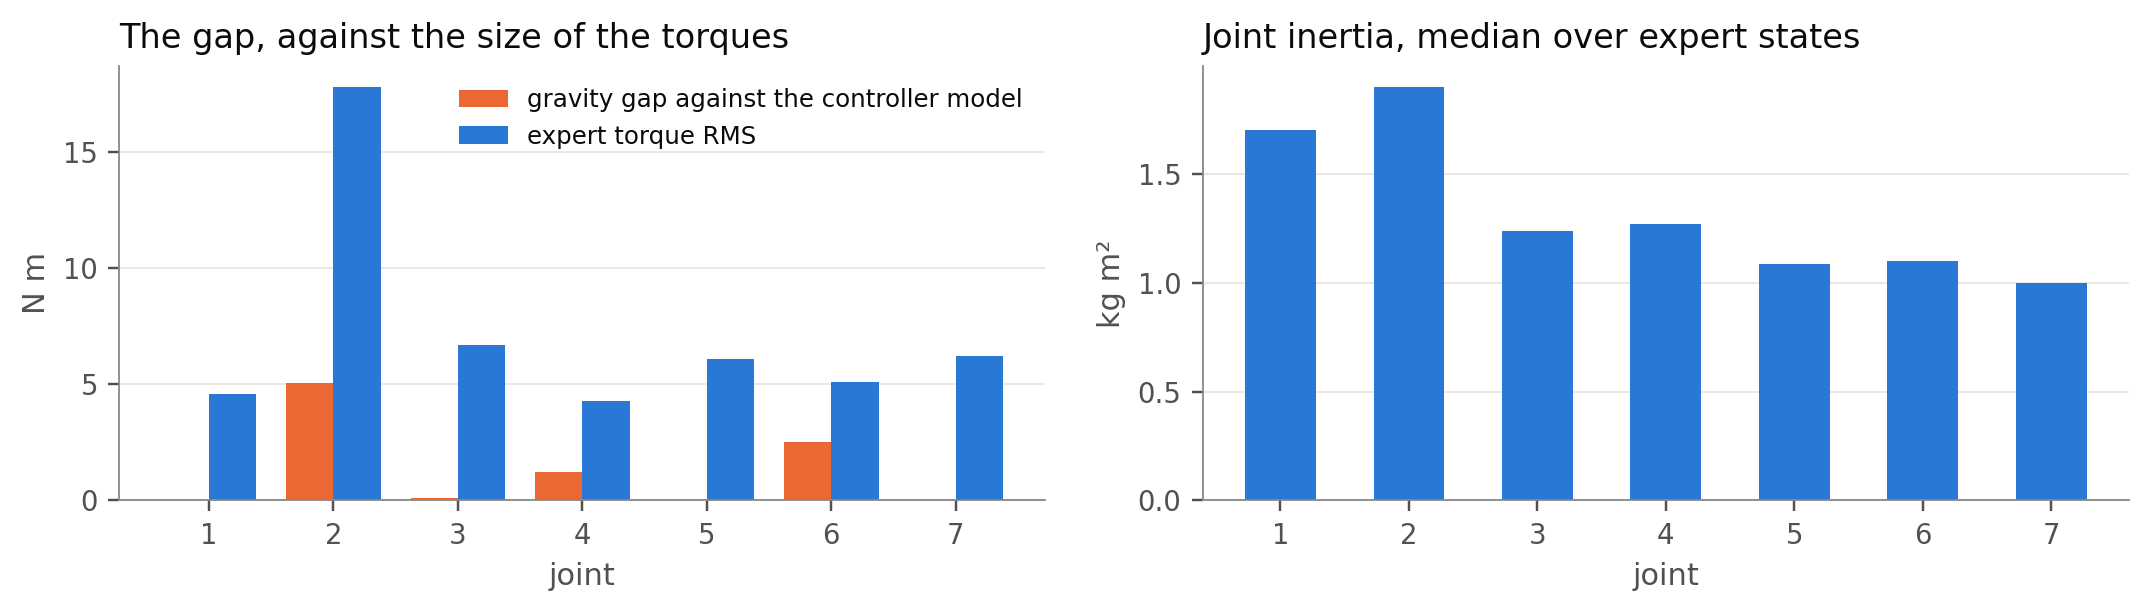

End-effector link: {'mass': 1.0, 'local_inertia': [1.0, 1.0, 1.0]}


In [2]:
g = ARM['pinocchio']['gravity_gap_median_nm']; rms = ARM['expert_torque_rms_nm']; I_ = ARM['joint_inertia_default_median']; x = np.arange(1, 8); w = .38
fig, ax = plt.subplots(1, 2, figsize=(10, 2.9))
ax[0].bar(x - w / 2, g, w, color=ORANGE, label='gravity gap against the controller model'); ax[0].bar(x + w / 2, rms, w, color=BLUE, label='expert torque RMS'); ax[0].set_xlabel('joint'); ax[0].set_ylabel('N m'); ax[0].set_title('The gap, against the size of the torques'); ax[0].legend(fontsize=8)
ax[1].bar(x, I_, color=BLUE, width=.55); ax[1].set_xlabel('joint'); ax[1].set_ylabel('kg m²'); ax[1].set_title('Joint inertia, median over expert states')
for a in ax: a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show(); print('End-effector link:', ARM['end_effector_link'])

## 2.2 C++ data collection

The expert was ported to C++ on the same Bullet build. About 9 times faster on the M1 and 12 times on Mint, with no numerical difference across ten audited runs (80,010 samples). Options that changed results were rejected: Eigen-only maths and a Bullet built from source.

| Machine | C++, seconds per saved run | Python, seconds per saved run | Speed-up |
|---|---|---|---|
| M1 laptop | 0.640 | 5.46 to 5.77 | about 9 times |
| Mint | 0.882 | 10.48 to 10.88 | about 12 times |

## 2.3 The expert issues torque at 1 kHz, and the real arm cannot

The Kinova Gen2 datasheet gives a low-level API limit of 500 Hz. So how does the expert behave if each torque is held for longer than one 1 ms simulator step? Tested on 30 targets. Other limits differ too: 0.20 m/s against the simulator's 0.25, joint 6 at 8 rad/s against a declared 48°/s, 30 against 20 N m. So this behaviour is simulator only.

The earlier one-joint estimate, kd·dt/I of about 0.06 at 500 Hz, predicts no trouble, so I had left the cause open. The right panel redoes the check with the full 7 by 7 mass matrix. **This check was not on the approved list.** It is a CPU check of a few seconds on the same saved states.

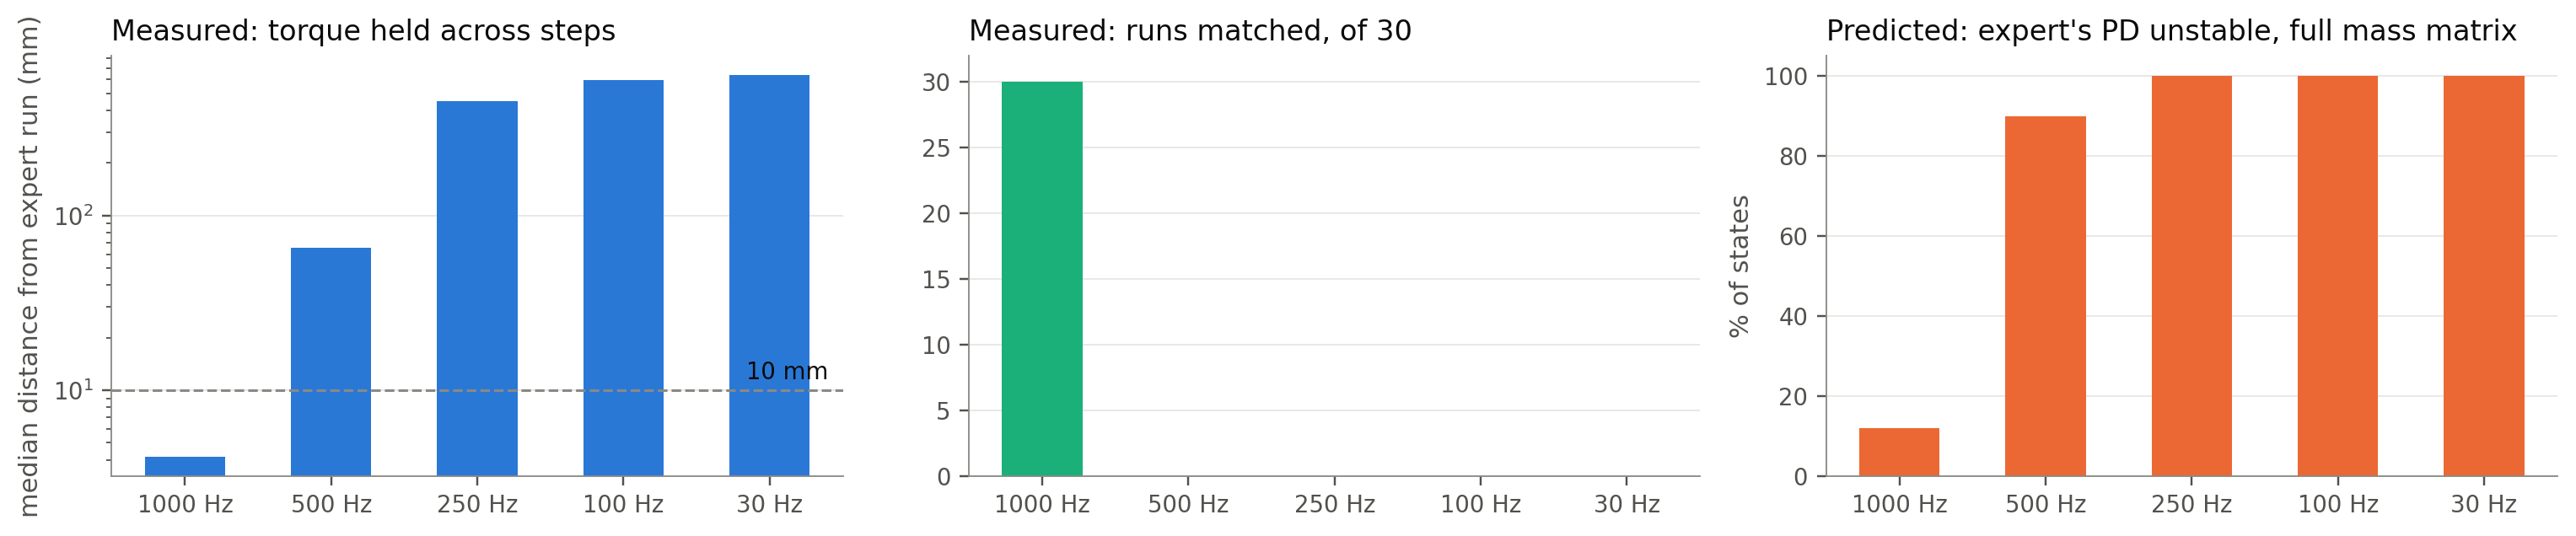

,rate,radius_p10,radius_p50,radius_p90,unstable_pct
0,1000 Hz,0.997,0.997,1.135,12.0
1,500 Hz,1.006,1.699,3.277,90.0
2,333 Hz,2.015,3.055,5.425,100.0
3,250 Hz,3.026,4.415,7.580,100.0
4,100 Hz,9.162,12.667,20.656,100.0
5,30 Hz,33.763,45.743,73.056,100.0


Mass matrix eigenvalues, median over states (kg m²): [0.022 0.127 0.215 0.337 1.583 3.256 3.909]


In [3]:
RATE = J('stability_rate.json'); H = MAC['hold_rate']; hz = ['1000', '500', '250', '100', '30']; lab = [f'{h} Hz' for h in hz]
fig, ax = plt.subplots(1, 3, figsize=(14, 3)); x = np.arange(5)
ax[0].bar(x, [H[h]['median_mm'] for h in hz], color=BLUE, width=.55); ax[0].axhline(10, color=MUTED, ls='--', lw=1); ax[0].text(4.4, 11.5, '10 mm', ha='right', fontsize=9); ax[0].set_yscale('log'); ax[0].set_ylabel('median distance from expert run (mm)'); ax[0].set_title('Measured: torque held across steps')
ax[1].bar(x, [H[h]['matched_of_30'] for h in hz], color=AQUA, width=.55); ax[1].set_ylim(0, 32); ax[1].set_title('Measured: runs matched, of 30')
ax[2].bar(x, [RATE['rates'][l]['unstable_share'] * 100 for l in lab], color=ORANGE, width=.55); ax[2].set_ylim(0, 105); ax[2].set_ylabel('% of states'); ax[2].set_title("Predicted: expert's PD unstable, full mass matrix")
for a in ax: a.set_xticks(x); a.set_xticklabels(lab); a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
display(pd.DataFrame([dict(rate=k, radius_p10=v['radius'][0], radius_p50=v['radius'][1], radius_p90=v['radius'][2], unstable_pct=v['unstable_share'] * 100) for k, v in RATE['rates'].items()]).round(3))
print('Mass matrix eigenvalues, median over states (kg m²):', np.round(RATE['mass_matrix_eigenvalues_median'], 3))

**Reading.** The joint diagonals are about 1 kg m², because the heavy link dominates them, but the lightest direction of the whole matrix is 0.022 kg m². Along that direction kd·dt/I is 1.35 at 1 kHz and 2.69 at 500 Hz, and the limit for this kind of integrator is about 2. So 1 kHz sits near the edge and 500 Hz is over it, which matches the measurement. This is a linear model with no solver damping, so it shows the failure is expected and does not prove the cause.

## 2.4 Other checks

- **Renderer.** The GPU renderer applies a debug colour palette, the CPU one gives white. Training and testing use one renderer. My earlier explanation of the red marking was wrong twice, and was corrected by checking the files.
- **Expert runs differ between machines.** Rebuilt runs do not match the supplied package: PARK moves by up to 0.21 s on one target. So scores are only compared on one machine. Table below.
- **Tracking.** MLflow experiment `v2-sensors`, two experiment notebooks of 361 and 398 cells, a written hypothesis before each training, 66 commits on the branch.
- **Input features.** Long feature analysis of the simulator with ChatGPT, then 12 wheel features (mean, right minus left), inputs of 16, 17 and finally 11. Camera placement study: hand, nose and corner saw the target at PARK on 0, 12 and 19 of 30. IMU in iterations 28 and 29: loss down 23%, reach worse. Weight sweep in iteration 25. Separate STOP network in iteration 27.

In [4]:
P = J('expert_rebuild_parity_mac_vs_package.json')
if P: display(pd.DataFrame([dict(target=r['dot'], steps_a=r['steps'][0], steps_b=r['steps'][1], park_step_a=r['park'][0], park_step_b=r['park'][1], gripper_distance_mm=r['hand_distance_expert'] * 1000) for r in P]).round(2))

,target,steps_a,steps_b,park_step_a,park_step_b,gripper_distance_mm
0,0,9549,9552,6230,6233,1.86
1,1,10507,10461,6754,6731,4.44
2,3,8001,8001,4075,4070,1.31
3,5,8001,8001,6130,6342,50.21


# Part 3: statistics

Tables and figures below are read from the saved results. Numbers in the readings were filled in from the same files when this notebook was built. The fit statistics use 100 validation runs at the expert's own states. Full-run scores use the 100 test targets. All of it is seed 7 unless a row says otherwise.

## 3.1 How well each model copies the expert

What: R² and adjusted R² per output, RMSE in physical units, F, and F corrected for correlated rows. Source: Lab 1, Lecture 1.2. RSE, RSS and intervals are in the table below it.

The rows are 1 ms apart, so they are far from independent. Lecture 1.2 warns about both: F at large n ("even an F>1 close to one can be an indication that H0 is false") and correlated noise ("reduced confidence margin"). So I also report effective n = n(1-ρ)/(1+ρ) with ρ the lag-1 residual correlation. Treat F and F_eff as descriptive only. Putting a network's parameter count and an effective sample size into a regression test does not give a valid F distribution, so neither column supports a significance claim. They are here because Lab 1 asks for F. R² and RMSE are what to read.

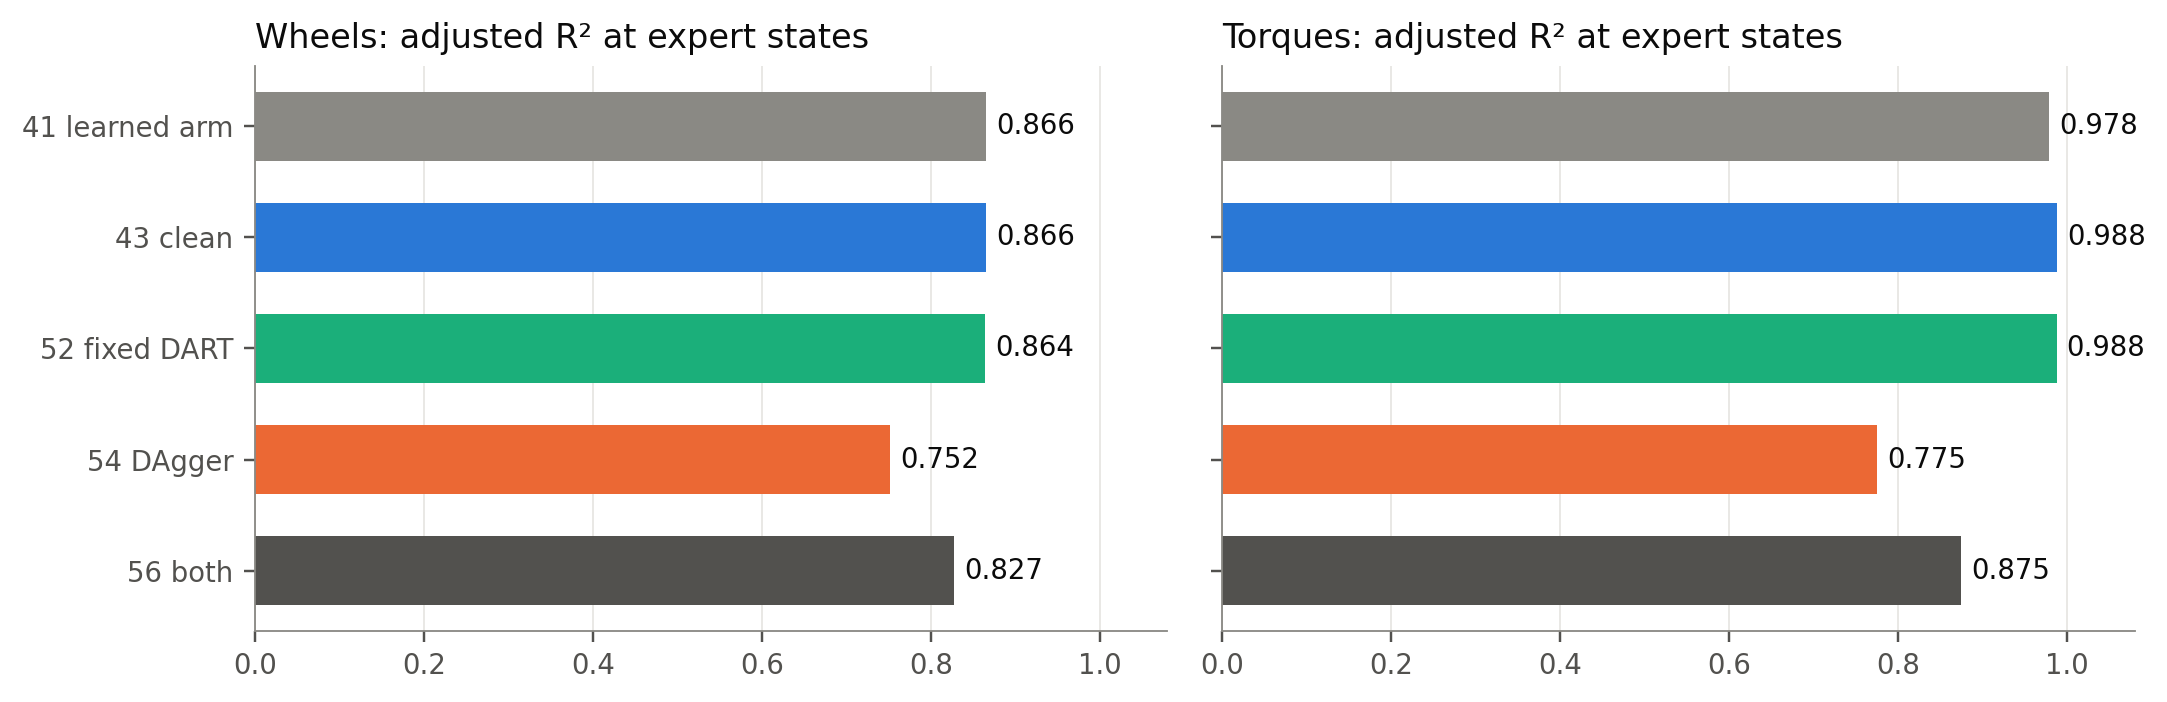

,model,output,R2,adjR2,RMSE,RSE,RSS,F,lag1,n,n_eff,F_eff
0,41 learned arm,wheels (rad/s),0.869,0.866,0.607,0.614,39005.0,314.0,0.909,26428,1266.0,8.8
1,41 learned arm,time to PARK (s),0.960,0.959,0.263,0.265,1824.0,1138.0,0.988,26428,154.0,NaN
2,41 learned arm,torques (N m),0.979,0.978,0.378,0.383,990908.0,2265.0,0.614,897417,214838.0,1168.6
3,41 learned arm,STOP distance (mm),0.977,0.977,13.720,13.729,168923104.0,32718.0,0.983,897417,7674.0,238.0
4,43 clean,wheels (rad/s),0.869,0.866,0.607,0.614,39005.0,314.0,0.909,26428,1266.0,8.8
5,43 clean,time to PARK (s),0.960,0.959,0.263,0.265,1824.0,1138.0,0.988,26428,154.0,NaN
6,43 clean,torques (N m),0.988,0.988,0.296,0.300,655209.0,2783.0,0.469,897417,324620.0,1970.7
7,43 clean,STOP distance (mm),0.993,0.993,7.446,7.451,49761148.0,112927.0,0.983,897417,7570.0,808.4
8,52 fixed DART,wheels (rad/s),0.867,0.864,0.610,0.616,39376.0,311.0,0.909,26428,1259.0,8.6
9,52 fixed DART,time to PARK (s),0.960,0.959,0.264,0.267,1844.0,1125.0,0.988,26428,158.0,NaN


In [5]:
def block(b):
    f = [x['F_eff'] for x in b if x['F_eff'] is not None]
    return dict(R2=np.mean([x['r2'] for x in b]), adjR2=np.mean([x['adj_r2'] for x in b]), RMSE=np.mean([x['rmse'] for x in b]), RSE=np.mean([x['rse'] for x in b]), RSS=np.sum([x['rss'] for x in b]), F=np.median([x['F'] for x in b]), lag1=np.median([x['residual_lag1'] for x in b]), n=b[0]['n'], n_eff=np.median([x['n_eff'] for x in b]), F_eff=np.median(f) if f else np.nan)
rows = []
for m in MODELS:
    for out, lab in (('wheels', 'wheels (rad/s)'), ('time_to_park', 'time to PARK (s)'), ('torque', 'torques (N m)'), ('stop_distance', 'STOP distance (mm)')):
        rows.append(dict(model=SHORT[m], output=lab, **block(OFF['models'][m][out])))
fit = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for a, out, title in ((ax[0], 'wheels (rad/s)', 'Wheels: adjusted R² at expert states'), (ax[1], 'torques (N m)', 'Torques: adjusted R² at expert states')):
    d = fit[fit.output == out]; y = np.arange(len(d))[::-1]
    a.barh(y, d.adjR2, color=[COL[m] for m in MODELS], height=.62); a.set_yticks(y); a.set_yticklabels(d.model); a.set_xlim(0, 1.08); a.set_title(title); a.grid(axis='y', visible=False)
    for yi, v in zip(y, d.adjR2): a.text(v + .012, yi, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout(); plt.show()
display(fit.round({'R2': 3, 'adjR2': 3, 'RMSE': 3, 'RSE': 3, 'RSS': 0, 'F': 0, 'lag1': 3, 'n_eff': 0, 'F_eff': 1}))

**Reading.** The clean arm explains 98.8% of torque variance on rows it has never seen, and the DAgger arm only 77.5%, yet the DAgger arm does far better on the robot. Wheels sit near 0.87. The blind start accounts for part of that, 22% of the squared wheel error from 14% of rows, and most of the error is on rows where the target is seen. F and F_eff are descriptive only, as noted above; the drop from raw to corrected values shows how correlated the rows are and nothing more. Both STOP rows repeat because DAgger gives the STOP network no new rows, so it is the same network.

## 3.2 Per joint: where the torque error sits (Lab 1)

Lab 1 asks for error per joint, confidence intervals and sources of error. The interval on RMSE is a bootstrap over whole runs, because rows within a run are related. The residual interval plays the role of the lecture's prediction interval: the range of error on a new row.

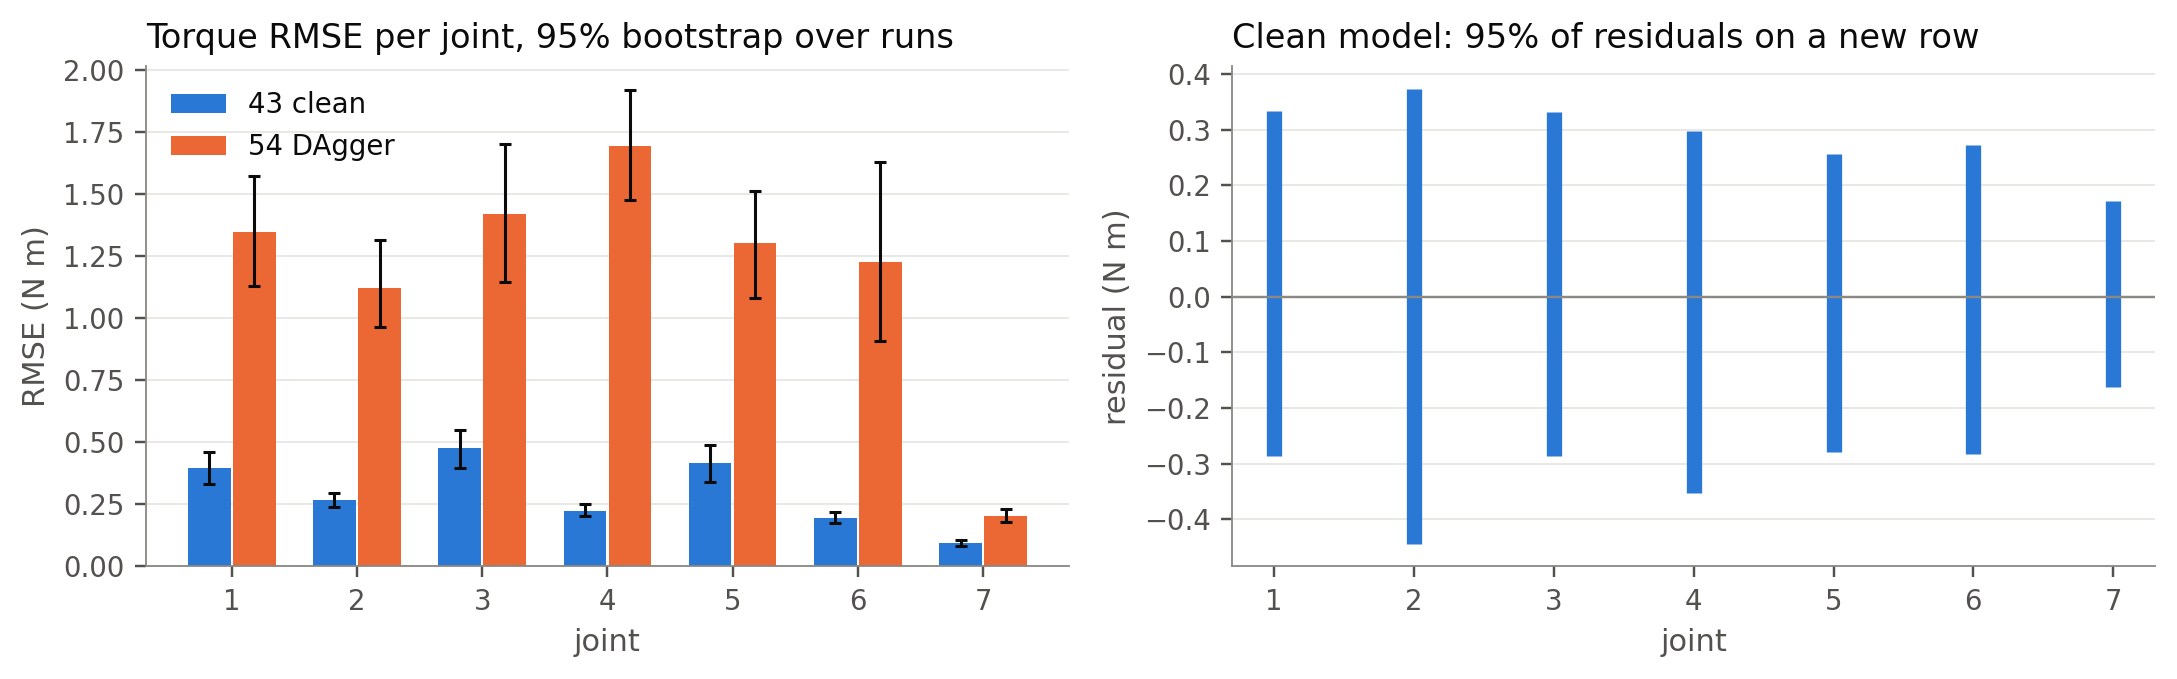

,joint,adjR2,RMSE,RMSE_low,RMSE_high,R2_low,R2_high,resid_low,resid_high,lag1,F_eff
0,1,0.984,0.397,0.333,0.461,0.976,0.990,-0.287,0.334,0.130,2128.553
1,2,0.982,0.269,0.241,0.296,0.978,0.986,-0.444,0.373,0.559,651.410
2,3,0.983,0.479,0.398,0.549,0.968,0.989,-0.286,0.331,0.124,1970.651
3,4,0.993,0.225,0.202,0.250,0.991,0.994,-0.352,0.298,0.773,651.118
4,5,0.984,0.415,0.342,0.488,0.967,0.991,-0.278,0.256,0.150,1996.529
5,6,0.992,0.197,0.176,0.221,0.990,0.993,-0.283,0.272,0.705,822.806
6,7,0.999,0.093,0.082,0.107,0.998,0.999,-0.163,0.171,0.469,17809.327


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for m, off in (('basics_standard', -.18), ('dagger', .18)):
    b = OFF['models'][m]['torque']; x = np.arange(1, 8) + off; v = [q['rmse'] for q in b]; lo = [q['rmse'] - q['rmse_ci'][0] for q in b]; hi = [q['rmse_ci'][1] - q['rmse'] for q in b]
    ax[0].bar(x, v, width=.34, color=COL[m], label=SHORT[m]); ax[0].errorbar(x, v, yerr=[lo, hi], fmt='none', ecolor=INK, elinewidth=1, capsize=2)
ax[0].set_xlabel('joint'); ax[0].set_ylabel('RMSE (N m)'); ax[0].set_title('Torque RMSE per joint, 95% bootstrap over runs'); ax[0].legend(); ax[0].grid(axis='x', visible=False)
b = OFF['models']['basics_standard']['torque']; x = np.arange(1, 8)
ax[1].vlines(x, [q['residual_pi95'][0] for q in b], [q['residual_pi95'][1] for q in b], color=BLUE, lw=5); ax[1].axhline(0, color=MUTED, lw=.8); ax[1].set_xlabel('joint'); ax[1].set_ylabel('residual (N m)'); ax[1].set_title('Clean model: 95% of residuals on a new row'); ax[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
display(pd.DataFrame([dict(joint=q['output'] + 1, adjR2=q['adj_r2'], RMSE=q['rmse'], RMSE_low=q['rmse_ci'][0], RMSE_high=q['rmse_ci'][1], R2_low=q['r2_ci'][0], R2_high=q['r2_ci'][1], resid_low=q['residual_pi95'][0], resid_high=q['residual_pi95'][1], lag1=q['residual_lag1'], F_eff=q['F_eff']) for q in b]).round(3))

## 3.3 Do we need a network? Linear regression, trees, forest (Lab 2)

Same training runs as the networks. Trees use depth 4 to 20, chosen on validation. A random forest answers Lab 2's extra question. Trees and forest were scored offline only and never drove the robot, so Lab 2's real-world question can only be answered in part.

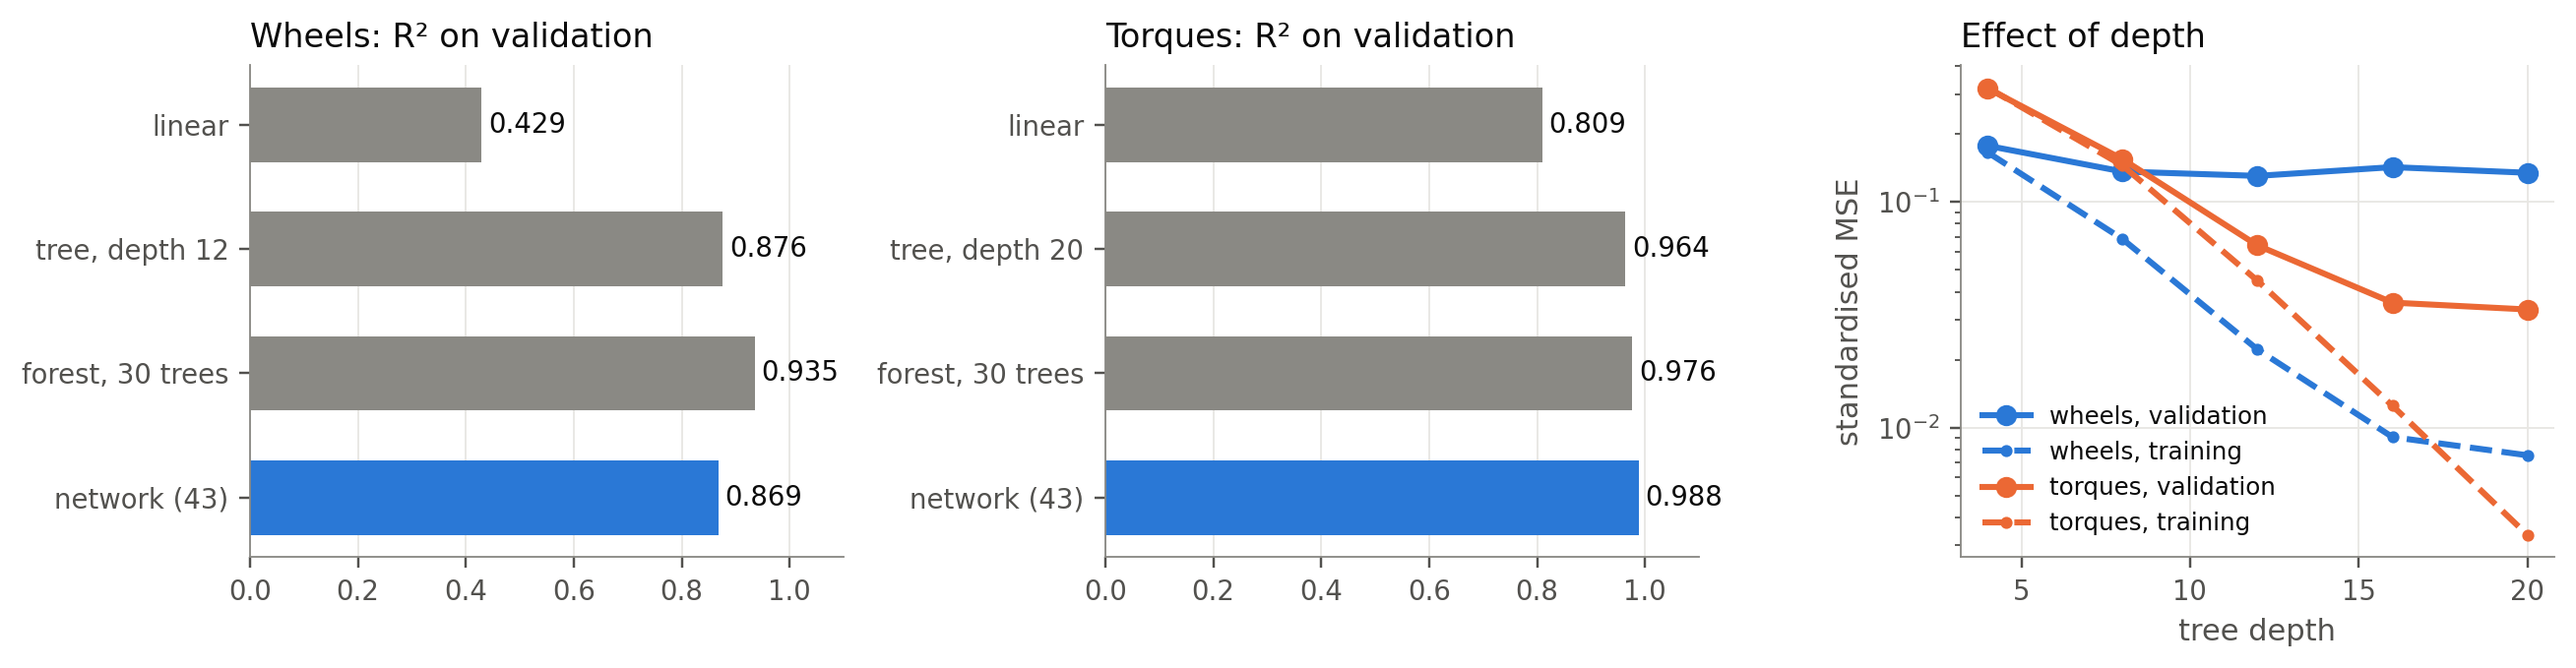

,output,model,R2,adjR2,RMSE,params
0,wheels,linear,0.429,0.428,1.266,48
1,wheels,"tree, depth 12",0.876,0.852,0.588,4300
2,wheels,"forest, 30 trees",0.935,-1708.992,0.426,122620
3,wheels,network (43),0.869,0.866,0.607,549
4,torques,linear,0.809,0.809,1.036,133
5,torques,"tree, depth 20",0.964,0.951,0.543,243901
6,torques,"forest, 30 trees",0.976,0.942,0.426,529165
7,torques,network (43),0.988,0.988,0.296,19847


In [7]:
rows = []
for key, lab, net in (('wheels', 'wheels', 'wheels'), ('torque', 'torques', 'torque')):
    e = OFF['baselines'][key]; n = block(OFF['models']['basics_standard'][net])
    for name, b, params in (('linear', e['linear']['val'], e['linear']['params']), (f"tree, depth {e['tree']['best_depth']}", e['tree']['val'], e['tree']['params']), (f"forest, 30 trees", e['forest']['val'], e['forest']['val'][0]['p'])):
        s = block(b); rows.append(dict(output=lab, model=name, R2=s['R2'], adjR2=s['adjR2'], RMSE=s['RMSE'], params=params))
    rows.append(dict(output=lab, model='network (43)', R2=n['R2'], adjR2=n['adjR2'], RMSE=n['RMSE'], params=OFF['models']['basics_standard'][net][0]['p']))
base = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, out in zip(ax[:2], ('wheels', 'torques')):
    d = base[base.output == out]; y = np.arange(len(d))[::-1]; a.barh(y, d.R2, color=[MUTED, MUTED, MUTED, BLUE], height=.6); a.set_yticks(y); a.set_yticklabels(d.model); a.set_xlim(0, 1.1); a.set_title(f'{out.capitalize()}: R² on validation'); a.grid(axis='y', visible=False)
    for yi, v in zip(y, d.R2): a.text(v + .012, yi, f'{v:.3f}', va='center', fontsize=9)
for key, col, lab in (('wheels', BLUE, 'wheels'), ('torque', ORANGE, 'torques')):
    g = OFF['baselines'][key]['tree']['grid']; x = [q['depth'] for q in g]; ax[2].plot(x, [q['val_mse'] for q in g], color=col, marker='o', label=f'{lab}, validation'); ax[2].plot(x, [q['train_mse'] for q in g], color=col, ls='--', marker='o', ms=3, label=f'{lab}, training')
ax[2].set_yscale('log'); ax[2].set_xlabel('tree depth'); ax[2].set_ylabel('standardised MSE'); ax[2].set_title('Effect of depth'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show(); display(base.round(3))

**Reading.** Linear regression fits torques to R² 0.81 and wheels to only 0.43, so the mapping is strongly non-linear, as Lab 2 expects. Depth overfits wheels past depth 12 (training keeps falling, validation does not). The surprise is that a forest fits wheels better than our network does offline (R² 0.935 against 0.869, RMSE 0.43 against 0.61 rad/s). Given every other result here, that does not tell us it would drive better, and a forest cannot be read as a smooth controller: its output is piecewise constant. The adjusted R² of a forest is meaningless because its leaf count is close to the row count, so the table shows R² for it. The network uses far fewer parameters.

## 3.4 Lowest error any single-instant model could reach

Find the 5 nearest training rows to each validation row and compare their labels. If near-identical inputs carry different labels, no function of those inputs can do better than that spread. This measures irreducible error (Lecture 1.1), the "input data does not contain sufficient information" case (Lecture 4.1), and the ε limit in Spencer. Method not from the course.

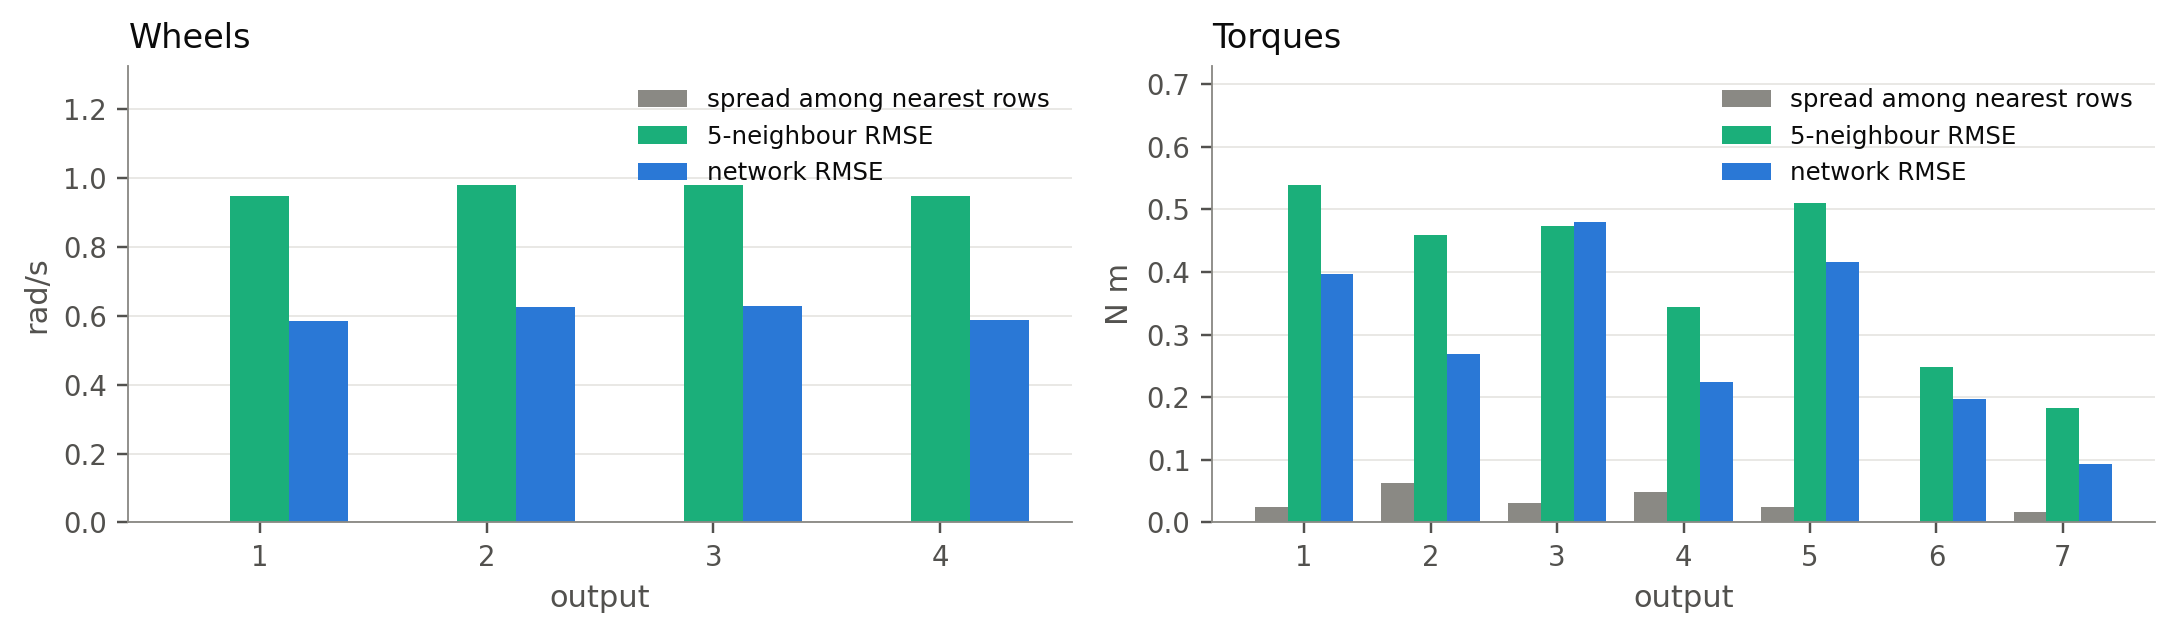

median distance to the 5th neighbour, standardised units: {'drive': 0.502, 'arm': 0.224}


In [8]:
if EXTRA and 'collision' in EXTRA:
    k = EXTRA['collision']; fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    b = OFF['models']['basics_standard']
    for a, key, net, title, unit in ((ax[0], 'drive', 'wheels', 'Wheels', 'rad/s'), (ax[1], 'arm', 'torque', 'Torques', 'N m')):
        n = len(k[key]['knn_rmse']); x = np.arange(1, n + 1); w = .26
        a.bar(x - w, k[key]['neighbour_label_sd'], w, color=MUTED, label='spread among nearest rows'); a.bar(x, k[key]['knn_rmse'], w, color=AQUA, label='5-neighbour RMSE'); a.bar(x + w, [q['rmse'] for q in b[net]], w, color=BLUE, label='network RMSE'); a.set_xticks(x); a.set_ylim(0, 1.35 * max(max(k[key]['knn_rmse']), max(q['rmse'] for q in b[net])))
        a.set_xlabel('output'); a.set_ylabel(unit); a.set_title(title); a.legend(fontsize=8); a.grid(axis='x', visible=False)
    plt.tight_layout(); plt.show(); print('median distance to the 5th neighbour, standardised units:', {q: round(k[q]['neighbour_distance'], 3) for q in k})

**Reading.** Exploratory, and it did not give what I wanted. The spread between neighbours is tiny (0.002 rad/s on the wheels, 0.030 N m on the arm), probably because a row's nearest neighbours are adjacent rows of one training run, which I did not check. So this is no estimate of irreducible error, and it should carry no conclusion. Its own error (0.97 rad/s on the wheels) is worse than the network's (0.61), and on the arm (0.39 N m) about level.

The collision that does exist is at the blind start: identical inputs with opposite expert commands (28 turn left, 27 turn right, of 55 blind training runs), so a deterministic network cannot reproduce both. That rules out imitating the exact command. It does not rule out the task, since either consistent turn eventually brings the target into view. Wheel RMSE is 0.77 rad/s on rows with the target out of view and 0.58 on the rest.

## 3.5 Speed inputs: fit against the robot

RSS with and without the six wheel speed inputs (iteration 37 against 38) on the validation rows, beside the paired robot results. An earlier version of this section called this a partial F test. It is removed as a test: the rows are strongly correlated and a network is not a nested regression, so an F distribution does not apply. The sevenfold RSS difference and the paired robot outcomes stand on their own.

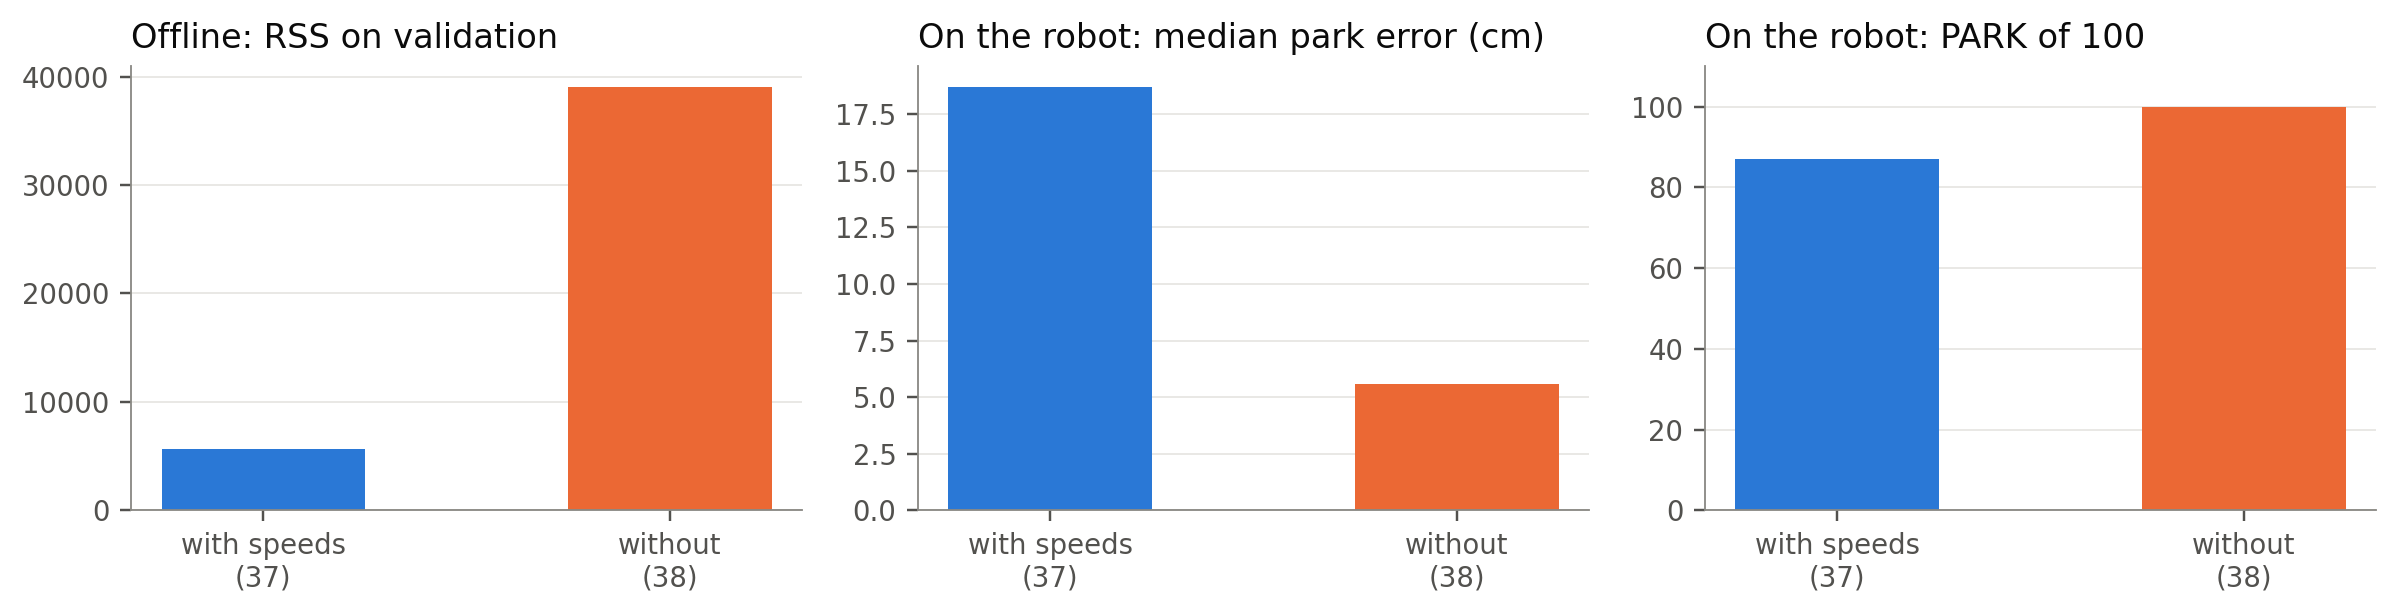

,rss_with_speeds,rss_without_speeds,ratio,rows
0,5611.7,39005.4,7.0,105712


In [9]:
if EXTRA and 'partial_f_speeds' in EXTRA:
    p = EXTRA['partial_f_speeds']; sa = per_target('height'); sb = per_target('no_speed')
    fig, ax = plt.subplots(1, 3, figsize=(11, 2.9))
    ax[0].bar(['with speeds\n(37)', 'without\n(38)'], [p['rss_with'], p['rss_without']], color=[BLUE, ORANGE], width=.5); ax[0].set_title('Offline: RSS on validation'); ax[0].grid(axis='x', visible=False)
    ax[1].bar(['with speeds\n(37)', 'without\n(38)'], [sa.park_error_cm.median(), sb.park_error_cm.median()], color=[BLUE, ORANGE], width=.5); ax[1].set_title('On the robot: median park error (cm)'); ax[1].grid(axis='x', visible=False)
    ax[2].bar(['with speeds\n(37)', 'without\n(38)'], [int(sa.parked.sum()), int(sb.parked.sum())], color=[BLUE, ORANGE], width=.5); ax[2].set_title('On the robot: PARK of 100'); ax[2].grid(axis='x', visible=False); ax[2].set_ylim(0, 110)
    plt.tight_layout(); plt.show(); display(pd.DataFrame([dict(rss_with_speeds=p['rss_with'], rss_without_speeds=p['rss_without'], ratio=p['rss_without'] / p['rss_with'], rows=p['n'])]).round(1))

**Reading.** RSS is 39,005 without the speeds and 5,612 with them, 7.0 times worse. On the robot, removing them took PARK from 87 to 100 and median park error from 18.7 to 5.6 cm. RSS measures prediction of the expert's next command at the expert's states. It does not measure what happens when the network's output feeds back into those inputs. The mechanism is in Part 1.6.

## 3.6 Settings check: depth, learning rate, batch size, data amount (Lab 4, Lecture 4.1)

Validation loss only. The arm runs for 100 epochs against 1,200 for the final model, and these networks train without the extra output heads, so this compares settings and does not reproduce final scores. Lab 4 asks for one larger and one smaller batch size; our base is the full batch, so only smaller ones exist.

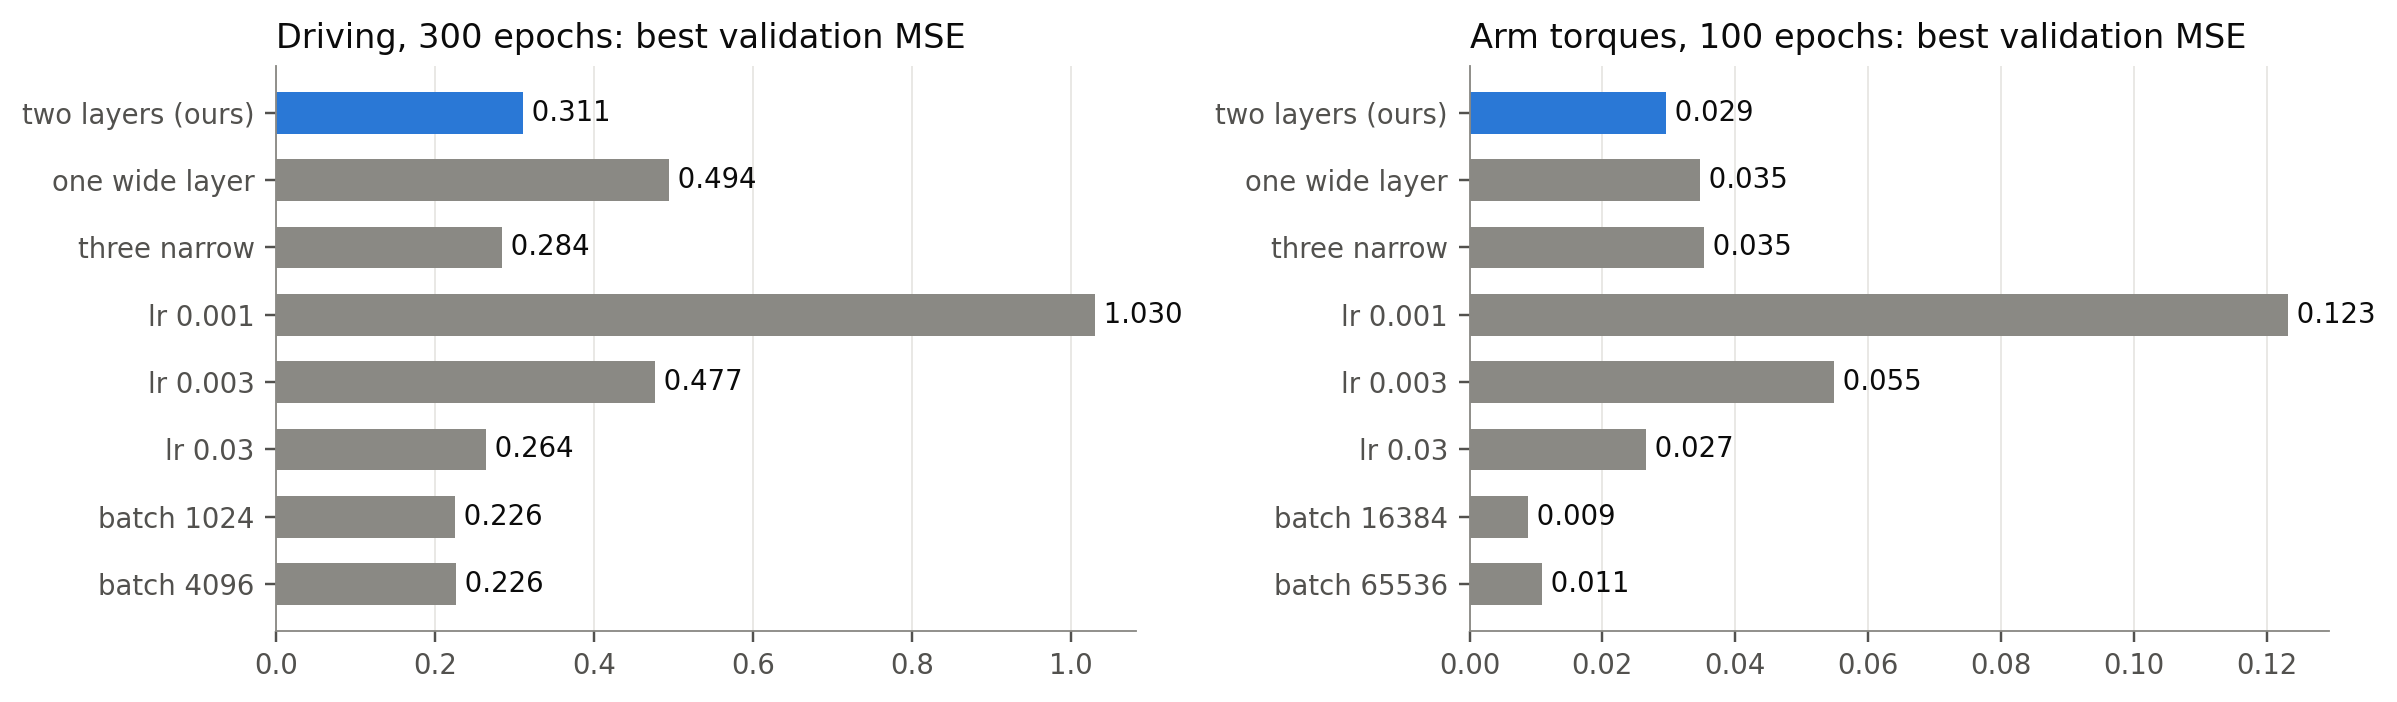

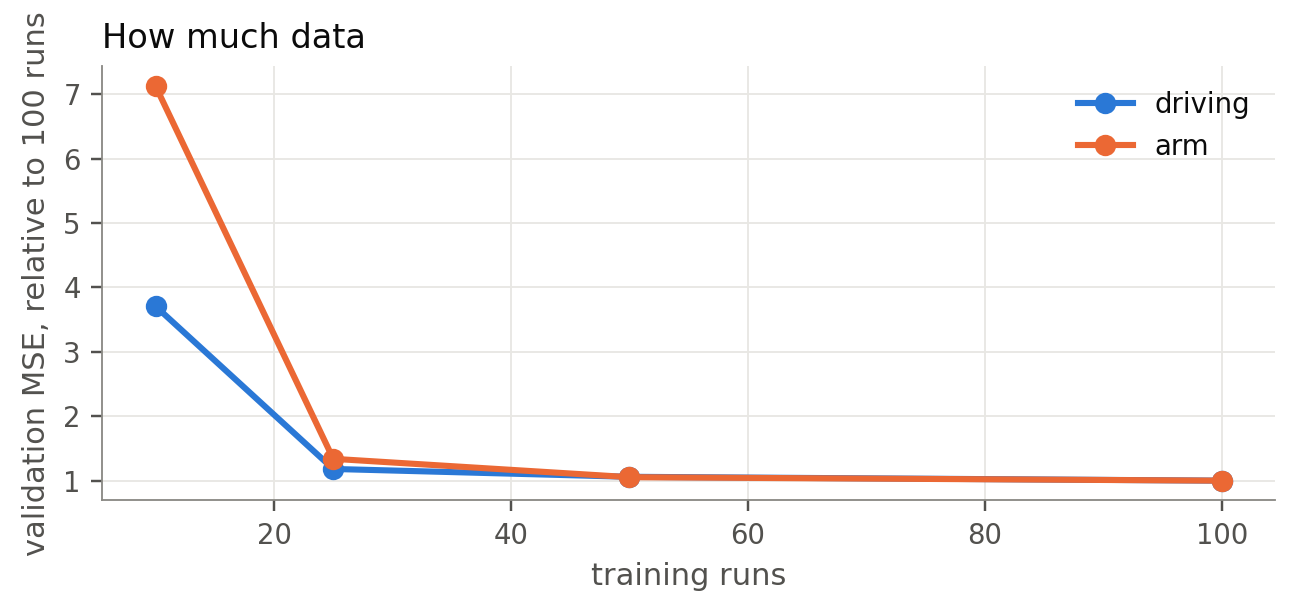

,network,tag,best_val,last_train,params,seconds,runs
0,arm,base,0.0295,0.0278,19847,12.2875,NaN
1,arm,batch16384,0.0088,0.0069,19847,16.8250,NaN
2,arm,batch65536,0.0110,0.0085,19847,15.1721,NaN
3,arm,data10,0.2103,0.0112,19847,1.5597,10.0
4,arm,data25,0.0395,0.0229,19847,3.3576,25.0
5,arm,data50,0.0311,0.0252,19847,6.3515,50.0
6,arm,deep,0.0353,0.0340,19511,14.6443,NaN
7,arm,lr0.001,0.1232,0.1210,19847,12.5944,NaN
8,arm,lr0.003,0.0549,0.0531,19847,14.4578,NaN
9,arm,lr0.03,0.0265,0.0245,19847,14.0442,NaN


In [10]:
if SWEEP:
    S = pd.DataFrame([{k: r.get(k) for k in ('network', 'tag', 'seed', 'params', 'best_val', 'best_epoch', 'last_train', 'last_val', 'seconds', 'runs')} for r in SWEEP])
    S = S.groupby(['network', 'tag'], as_index=False).agg(best_val=('best_val', 'mean'), last_train=('last_train', 'mean'), params=('params', 'first'), seconds=('seconds', 'mean'), runs=('runs', 'first'))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
    order = ['base', 'shallow', 'deep', 'lr0.001', 'lr0.003', 'lr0.03']; lab = ['two layers (ours)', 'one wide layer', 'three narrow', 'lr 0.001', 'lr 0.003', 'lr 0.03']
    for a, net, title in ((ax[0], 'drive', 'Driving, 300 epochs'), (ax[1], 'arm', 'Arm torques, 100 epochs')):
        d = S[S.network == net].set_index('tag'); extra = [t for t in d.index if t.startswith('batch')]; tags = order + extra; v = [d.best_val.get(t, np.nan) for t in tags]; y = np.arange(len(tags))[::-1]
        a.barh(y, v, color=[BLUE] + [MUTED] * (len(tags) - 1), height=.62); a.set_yticks(y); a.set_yticklabels(lab + [t.replace('batch', 'batch ') for t in extra]); a.set_title(title + ': best validation MSE'); a.grid(axis='y', visible=False)
        for yi, q in zip(y, v): a.text(q, yi, f' {q:.3f}', va='center', fontsize=9)
    plt.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(6, 2.9))
    for net, col, lab_ in (('drive', BLUE, 'driving'), ('arm', ORANGE, 'arm')):
        d = S[S.network == net].set_index('tag'); x = [10, 25, 50, 100]; y = [d.best_val.get(f'data{n}', np.nan) for n in (10, 25, 50)] + [d.best_val['base']]; y0 = y[-1]; ax.plot(x, np.array(y) / y0, color=col, marker='o', label=lab_)
    ax.set_xlabel('training runs'); ax.set_ylabel('validation MSE, relative to 100 runs'); ax.set_title('How much data'); ax.legend(); plt.tight_layout(); plt.show(); display(S.round(4))

**Reading.** Validation loss, not robot scores. Shape first: at about the same parameter count, three layers beat one on driving (0.284 against 0.494), and on the arm two layers (0.0295) beat both one (0.0347) and three (0.0353). Learning rate: 0.03 ends slightly lower than 0.01 on both, and 0.001 is far behind after these epochs. Batch size is the surprise. Mini-batches of 16,384 reach 0.0088 on the arm in 17 s, against 0.0295 for full batches in 12 s at the same 100 epochs. That is about the level of the final 1,200-epoch model (0.011), so full batches cost a lot of training time, though nothing here tests the mini-batch model on the robot. Data amount, Lecture 4.1's learning curve: with 10 runs training loss is far below validation (0.0112 against 0.2103 on the arm, 0.183 against 1.153 on driving), which is overfitting. By 25 runs the gap is mostly gone, and 25, 50 and 100 runs differ by little (0.0395, 0.0311, 0.0295). These runs all take the same number of steps, so this undersells more data.

## 3.7 PARK and STOP decisions, and where the error sits (Lab 4, Lecture 1.2, preprocessing notes, Choudhury L05)

The two yes/no decisions at the expert's states. The preprocessing notes warn about rare events and that "errors are not weighted equally in robotics". Choudhury's cliff example: a mistake on "a tiny fraction of the overall data set" can decide the run. So this splits error by phase and shows the share of rows in each phase.

,model,decision,TP,FP,FN,TN,precision,recall,F1
0,41 learned arm,PARK,7772,703,1100,16853,0.917,0.876,0.896
1,41 learned arm,STOP,20111,7892,12176,248639,0.718,0.623,0.667
2,43 clean,PARK,7772,703,1100,16853,0.917,0.876,0.896
3,43 clean,STOP,24166,4362,8121,252169,0.847,0.748,0.795
4,52 fixed DART,PARK,7659,619,1213,16937,0.925,0.863,0.893
5,52 fixed DART,STOP,22057,4451,10230,252080,0.832,0.683,0.750
6,54 DAgger,PARK,6011,505,2861,17051,0.922,0.678,0.781
7,54 DAgger,STOP,24166,4362,8121,252169,0.847,0.748,0.795
8,56 both,PARK,7777,274,1095,17282,0.966,0.877,0.919
9,56 both,STOP,22057,4451,10230,252080,0.832,0.683,0.750


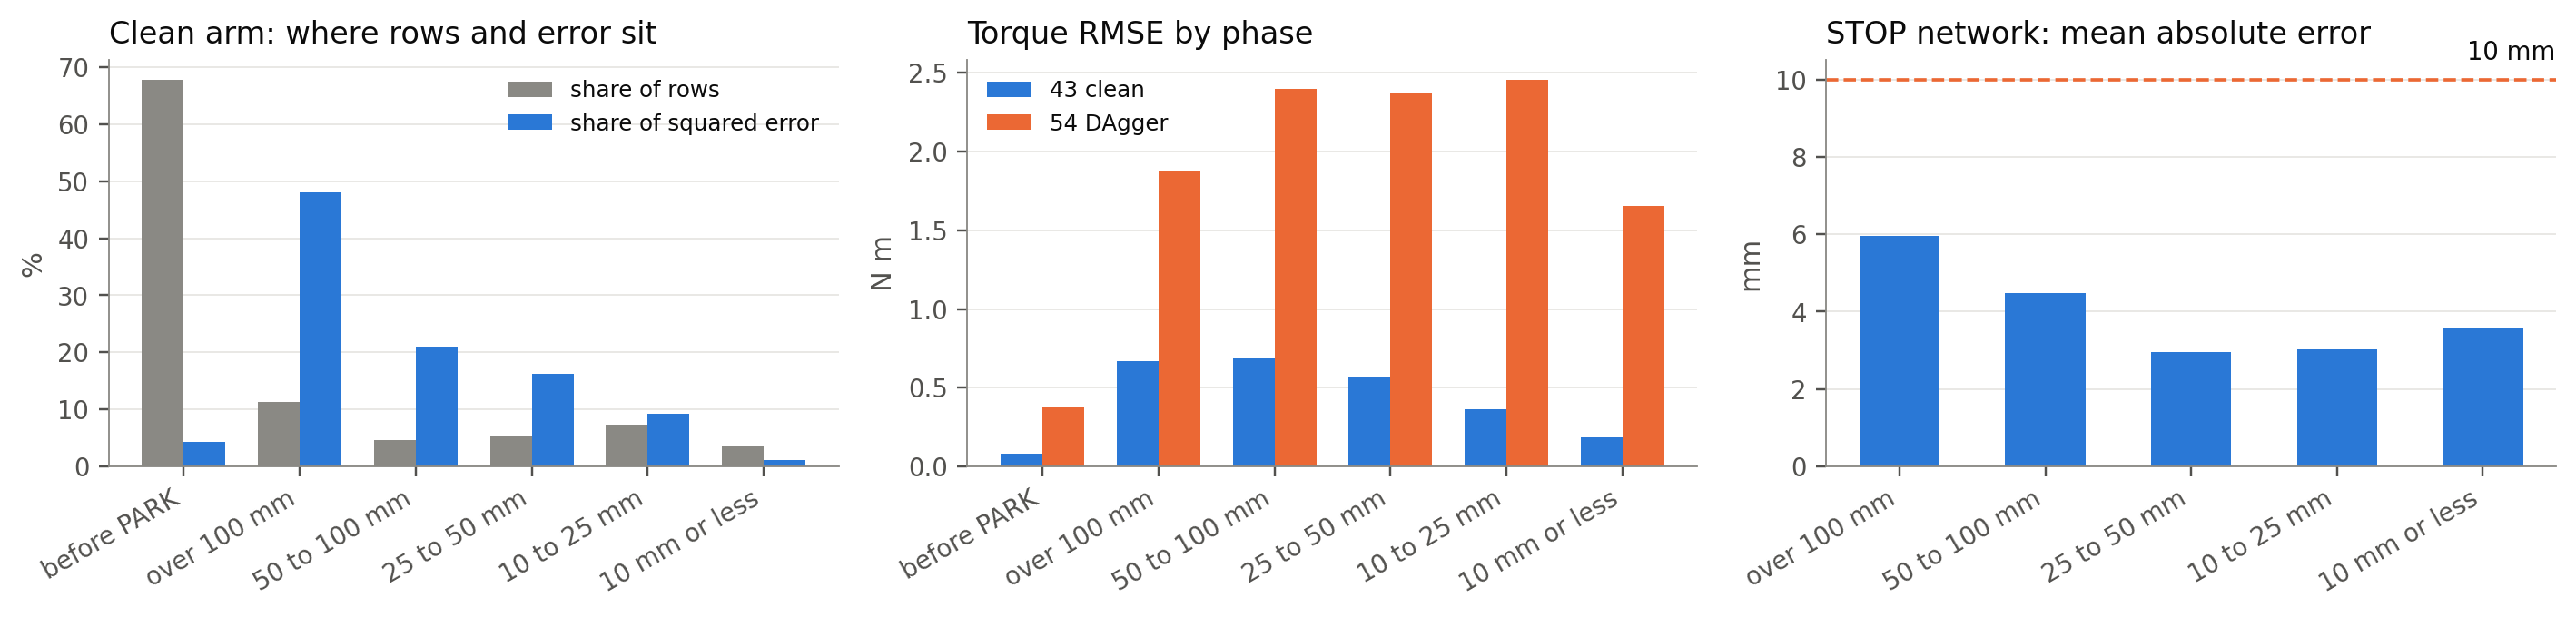

,model,stop_never,stop_fires_at_park,stop_true_mm_at_first_fire,stop_minus_crossing_s,park_never,park_minus_expert_s
0,41 learned arm,50,4,13.307,-0.166,7,-0.392
1,43 clean,51,0,10.532,-0.036,7,-0.392
2,52 fixed DART,54,1,10.832,-0.060,8,-0.340
3,54 DAgger,51,0,10.532,-0.036,21,-0.411
4,56 both,54,1,10.832,-0.060,5,-0.224


In [11]:
if DEEP:
    m = DEEP['models']; rows = []
    for k in MODELS:
        for dec, key in (('PARK', 'park_decision_rows'), ('STOP', 'stop_decision_rows')):
            q = m[k][key]; f1 = 2 * q['precision'] * q['recall'] / max(q['precision'] + q['recall'], 1e-9); rows.append(dict(model=SHORT[k], decision=dec, TP=q['tp'], FP=q['fp'], FN=q['fn'], TN=q['tn'], precision=q['precision'], recall=q['recall'], F1=f1))
    display(pd.DataFrame(rows).round(3))
    ph = m['basics_standard']['torque_by_phase']; L = list(ph); fig, ax = plt.subplots(1, 3, figsize=(13, 3.2)); x = np.arange(len(L)); w = .36
    ax[0].bar(x - w / 2, [ph[k]['row_share'] * 100 for k in L], w, color=MUTED, label='share of rows'); ax[0].bar(x + w / 2, [ph[k]['error_share'] * 100 for k in L], w, color=BLUE, label='share of squared error'); ax[0].set_xticks(x); ax[0].set_xticklabels(L, rotation=30, ha='right'); ax[0].set_ylabel('%'); ax[0].set_title('Clean arm: where rows and error sit'); ax[0].legend(fontsize=8); ax[0].grid(axis='x', visible=False)
    for k, off in (('basics_standard', -w / 2), ('dagger', w / 2)):
        p2 = m[k]['torque_by_phase']; ax[1].bar(x + off, [p2[q]['rmse_nm'] for q in L], w, color=COL[k], label=SHORT[k])
    ax[1].set_xticks(x); ax[1].set_xticklabels(L, rotation=30, ha='right'); ax[1].set_ylabel('N m'); ax[1].set_title('Torque RMSE by phase'); ax[1].legend(fontsize=8); ax[1].grid(axis='x', visible=False)
    L2 = L[1:]; ax[2].bar(np.arange(len(L2)), [ph[k]['stop_mae_mm'] for k in L2], color=BLUE, width=.55); ax[2].axhline(10, color=ORANGE, lw=1.2, ls='--'); ax[2].text(len(L2) - .5, 10.5, '10 mm', color=INK, fontsize=9, ha='right'); ax[2].set_xticks(np.arange(len(L2))); ax[2].set_xticklabels(L2, rotation=30, ha='right'); ax[2].set_ylabel('mm'); ax[2].set_title('STOP network: mean absolute error'); ax[2].grid(axis='x', visible=False)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame([dict(model=SHORT[k], stop_never=m[k]['stop_runs']['never'], stop_fires_at_park=m[k]['stop_runs']['fires_within_50ms_of_park'], stop_true_mm_at_first_fire=m[k]['stop_runs']['true_distance_at_first_fire_mm'][0], stop_minus_crossing_s=m[k]['stop_runs']['first_fire_minus_true_crossing_s'][0], park_never=m[k]['park_runs']['never'], park_minus_expert_s=m[k]['park_runs']['first_fire_minus_expert_park_s'][0]) for k in MODELS]).round(3))

**Reading.** These rows are the expert's states, so they show the decision at its best. STOP fires on none of the runs within 50 ms of PARK. Precision and recall at the row level are 0.85 and 0.75, and it never fires on 51 of 100 expert runs. Its first firing is at 10.5 mm, so its threshold sits close to the 10 mm line. For torque, 68% of rows are before PARK and hold only 4% of the squared error, so most of the average loss comes from rows where nothing happens. Section 3.26 shows what happens on the network's own states.

## 3.8 Covariate shift, measured directly (Laskey, Ross, Choudhury L01, L03)

Laskey splits a policy's loss on its own states into a shift term and the standard loss on the expert's states. DAgger collection saved exactly what that needs: the learner's states with the expert's labels. So this is the same model on the same training targets, scored two ways. The final DAgger model has no labelled runs of its own, because that would need a fourth round, so the trend stops at round 2.

Note on the expert's label here: it is the stateful copy of the expert, so far from its path it asks for large correcting torques. That is the point of DAgger, and also part of why the number is large.

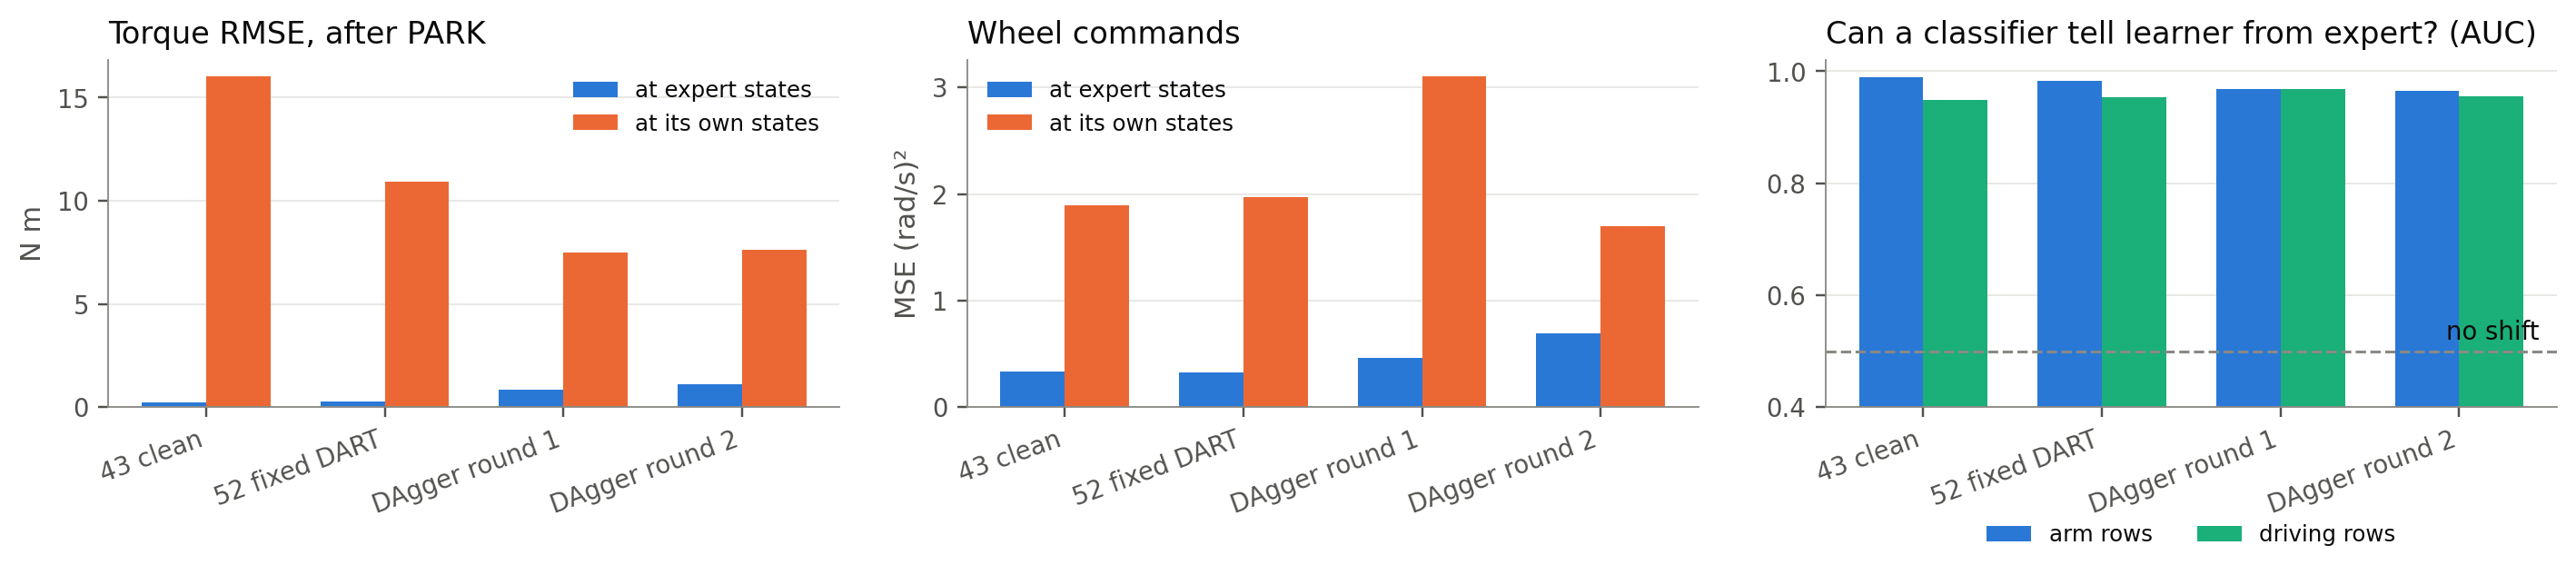

,model,runs,torque_rmse_expert,torque_rmse_own,wheel_ratio_own_over_expert,arm_auc,arm_rows_clearly_unlike_expert,drive_auc,first_stop_true_mm_own,never_stop_share
0,43 clean,100,0.235,16.020,5.438,0.990,0.899,0.948,153.060,0.010
1,52 fixed DART,100,0.253,10.939,5.710,0.982,0.880,0.954,59.478,0.170
2,DAgger round 1,100,0.866,7.501,5.261,0.969,0.774,0.968,40.985,0.190
3,DAgger round 2,93,1.124,7.640,1.329,0.965,0.758,0.955,51.638,0.312


In [12]:
if DEEP:
    s = DEEP['shift']; L = ['basics_standard', 'dart', 'dagger round 1', 'dagger round 2']; lab = ['43 clean', '52 fixed DART', 'DAgger round 1', 'DAgger round 2']; x = np.arange(4); w = .36
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
    ax[0].bar(x - w / 2, [s[k]['torque_rmse_nm_expert'][0] for k in L], w, color=BLUE, label='at expert states'); ax[0].bar(x + w / 2, [s[k]['torque_rmse_nm_own'][0] for k in L], w, color=ORANGE, label='at its own states'); ax[0].set_ylabel('N m'); ax[0].set_title('Torque RMSE, after PARK'); ax[0].legend(fontsize=8)
    ax[1].bar(x - w / 2, [s[k]['wheel_mse_at_expert_states'][0] for k in L], w, color=BLUE, label='at expert states'); ax[1].bar(x + w / 2, [s[k]['wheel_mse_on_own_states'][0] for k in L], w, color=ORANGE, label='at its own states'); ax[1].set_ylabel('MSE (rad/s)²'); ax[1].set_title('Wheel commands'); ax[1].legend(fontsize=8)
    ax[2].bar(x - w / 2, [s[k]['arm_shift']['auc'] for k in L], w, color=BLUE, label='arm rows'); ax[2].bar(x + w / 2, [s[k]['drive_shift']['auc'] for k in L], w, color=AQUA, label='driving rows'); ax[2].axhline(.5, color=MUTED, lw=1, ls='--'); ax[2].text(3.45, .52, 'no shift', fontsize=9, ha='right'); ax[2].set_ylim(.4, 1.02); ax[2].set_title('Can a classifier tell learner from expert? (AUC)'); ax[2].legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.28), ncol=2)
    for a in ax: a.set_xticks(x); a.set_xticklabels(lab, rotation=20, ha='right'); a.grid(axis='x', visible=False)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame([dict(model=l, runs=s[k]['runs'], torque_rmse_expert=s[k]['torque_rmse_nm_expert'][0], torque_rmse_own=s[k]['torque_rmse_nm_own'][0], wheel_ratio_own_over_expert=s[k]['wheel_ratio_per_run'][0], arm_auc=s[k]['arm_shift']['auc'], arm_rows_clearly_unlike_expert=s[k]['arm_shift']['learner_rows_clearly_unlike_expert'], drive_auc=s[k]['drive_shift']['auc'], first_stop_true_mm_own=s[k]['true_distance_at_first_stop_own_states_mm'][0], never_stop_share=s[k]['never_stop_share']) for k, l in zip(L, lab)]).round(3))

**Reading.** The clean arm's torque error is 0.24 N m at the expert's states and 16.0 N m on its own, 68 times larger. Round 1 of DAgger gives 0.87 and 7.5, 9 times. So DAgger worsens the fit at the expert's states and reduces the error on its own. The ratios are large partly because the expert's label far from its path is a large correction.

AUC stays high in every row (0.990 for the clean arm, 0.965 for round 2), and the classifier's folds split whole runs, so rows from one run never sit on both sides. AUC measures how easy the states are to tell apart. It says nothing about the cost of the difference. Own-state torque error falls while AUC stays high, so the learner's states remain unlike the expert's and acting in them became less costly. The wheels' median per-run ratio improves from 5.4 to 1.3 by round 2.

## 3.9 The STOP network on the learner's states

The STOP network never gets DAgger rows. So how far from the target is the gripper, on the learner's own states, the first time the network says stop? Compare with the expert's states, where it is nearly exact.

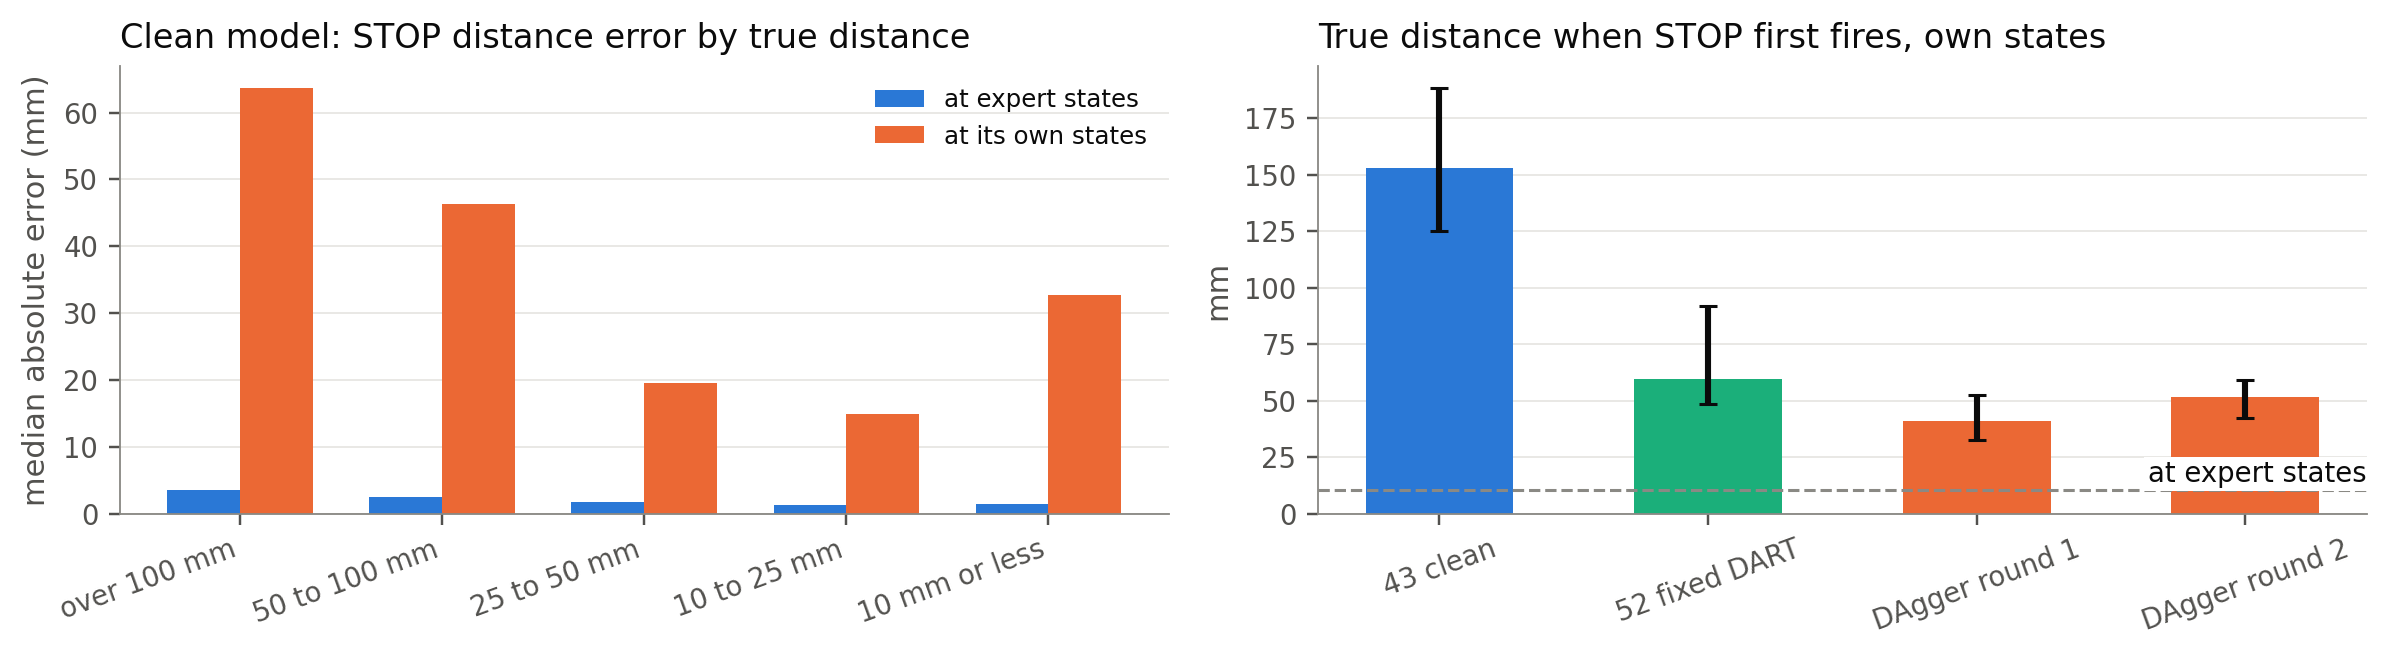

In [13]:
if DEEP:
    s = DEEP['shift']; bands = ['over 100 mm', '50 to 100 mm', '25 to 50 mm', '10 to 25 mm', '10 mm or less']; x = np.arange(5); w = .36
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.1)); e = s['basics_standard']
    ax[0].bar(x - w / 2, [e['stop_abs_err_mm_expert'][b]['median'] for b in bands], w, color=BLUE, label='at expert states'); ax[0].bar(x + w / 2, [e['stop_abs_err_mm_own'][b]['median'] for b in bands], w, color=ORANGE, label='at its own states'); ax[0].set_xticks(x); ax[0].set_xticklabels(bands, rotation=20, ha='right'); ax[0].set_ylabel('median absolute error (mm)'); ax[0].set_title('Clean model: STOP distance error by true distance'); ax[0].legend(fontsize=8); ax[0].grid(axis='x', visible=False)
    L = ['basics_standard', 'dart', 'dagger round 1', 'dagger round 2']; lab = ['43 clean', '52 fixed DART', 'DAgger round 1', 'DAgger round 2']; v = [s[k]['true_distance_at_first_stop_own_states_mm'] for k in L]
    ax[1].bar(lab, [q[0] for q in v], color=[BLUE, AQUA, ORANGE, ORANGE], width=.55, yerr=[[q[0] - q[1] for q in v], [q[2] - q[0] for q in v]], ecolor=INK, capsize=3); ax[1].axhline(DEEP['models']['basics_standard']['stop_runs']['true_distance_at_first_fire_mm'][0], color=MUTED, ls='--', lw=1); ax[1].text(3.45, 14, 'at expert states', fontsize=9, ha='right', bbox=dict(fc='white', ec='none', pad=1)); ax[1].set_ylabel('mm'); ax[1].set_title('True distance when STOP first fires, own states'); ax[1].grid(axis='x', visible=False); ax[1].tick_params(axis='x', rotation=20)
    plt.tight_layout(); plt.show()

**Reading.** At the expert's states STOP error is at most a few mm in every band. On the clean model's own states it is 64 mm far from the target and 33 mm inside 10 mm. First firing moves from 153 mm to 41 mm with DAgger's round 1. The STOP network's weights are identical in those two models, so the change comes only from the inputs the improved arm now gives it. This is a change in what the network is given, with no learning in the STOP network itself.

## 3.10 Is the network copying? Action predictability (Wen 2020)

Wen's test for copying: train a small network to predict the wheel command from the previous 9 commands. If it is easier to predict on a learner's runs than on the expert's, the learner is repeating itself. A positive log ratio means more predictable than the expert. Iterations 37 and 38 differ only by the six speed inputs.

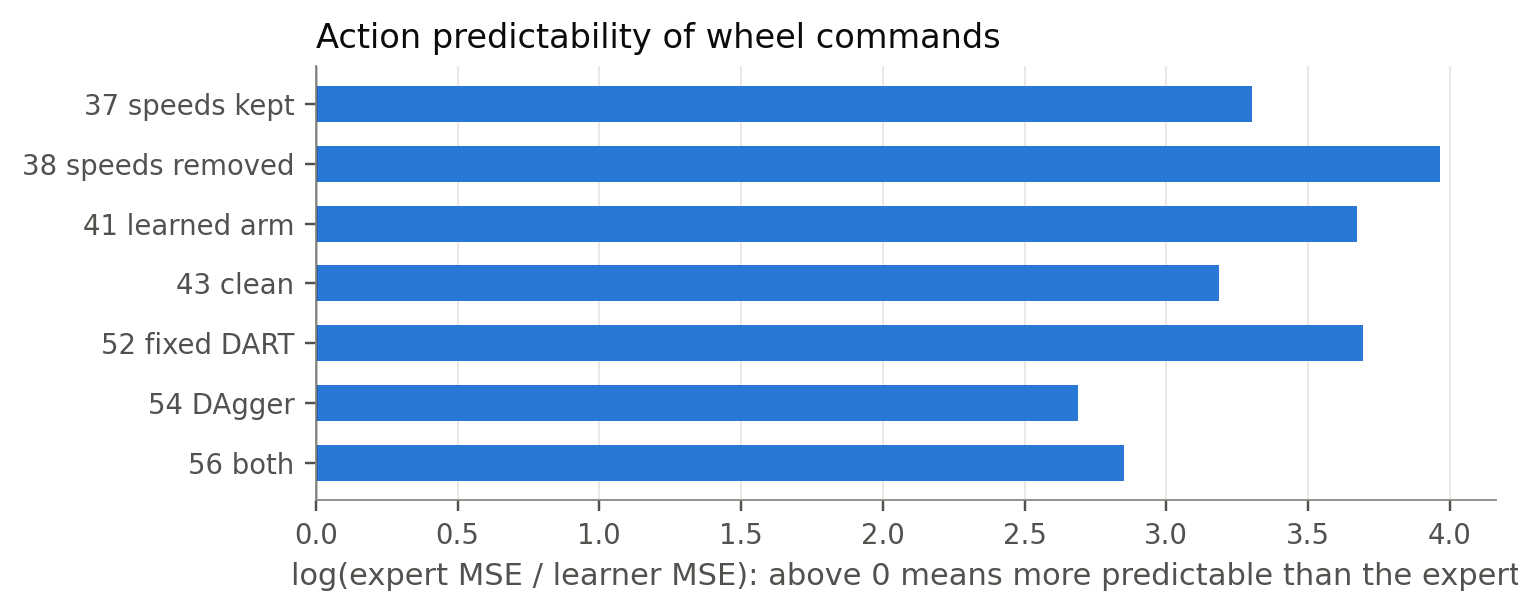

,model,mse,log_ratio
0,expert,0.0732,0.0000
1,37 speeds kept,0.0027,3.3007
2,38 speeds removed,0.0014,3.9658
3,41 learned arm,0.0019,3.6738
4,43 clean,0.0030,3.1855
5,52 fixed DART,0.0018,3.6923
6,54 DAgger,0.0050,2.6901
7,56 both,0.0042,2.8519


In [14]:
if EXTRA and 'action_predictability' in EXTRA:
    a = EXTRA['action_predictability']; L = [k for k in ('height', 'no_speed', 'baseline', 'basics_standard', 'dart', 'dagger', 'dart_dagger') if a.get(k)]; lab = {'height': '37 speeds kept', 'no_speed': '38 speeds removed', **SHORT}
    fig, ax = plt.subplots(figsize=(7, 2.9)); y = np.arange(len(L))[::-1]; v = [a[k]['log_ratio'] for k in L]; ax.barh(y, v, color=[BLUE if q > 0 else ORANGE for q in v], height=.6); ax.axvline(0, color=INK, lw=.8); ax.set_yticks(y); ax.set_yticklabels([lab[k] for k in L]); ax.set_xlabel('log(expert MSE / learner MSE): above 0 means more predictable than the expert'); ax.set_title('Action predictability of wheel commands'); ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()
    display(pd.DataFrame([dict(model='expert', mse=a['expert_mse'], log_ratio=0)] + [dict(model=lab[k], **a[k]) for k in L]).round(4))

**Reading.** A negative result to keep. Every learner is far more predictable than the expert, and iteration 38 without speeds (3.97) is more predictable than 37 with them (3.30), the opposite ordering to what the copycat diagnostic expects. Predictable commands can come from unhelpful repetition or from smooth successful control, and this test cannot separate them here. This does not refute Wen et al.: the task differs and the diagnostic is adapted. It only says action predictability did not discriminate harmful copying on this task. The range gain in Section 3.12 did.

## 3.11 The task in one dimension

The framing: driving is a turn, then one straight approach; reaching is one progress variable per target. PCA is from Lecture 2.2, and Liu 2025 validates its theory with a one-dimensional simulation. The 1D reduction itself is ours. First, is it true of the expert?

,phase,measure,value
0,Driving,"path length / straight line (10th, 50th, 90th ...","[1.0672453457925688, 1.2204257842358728, 1.602..."
1,Driving,share of drive within 10 degrees of target,"[0.5267262969588552, 0.7374887398658794, 0.889..."
2,Driving,"base speed, 95th percentile (m/s)","[0.25129967128603037, 0.25156130108924024, 0.2..."
3,Driving,"time to PARK from distance to go, R²",0.988642
4,Driving,"speed from distance to go, R²",0.649371
5,Driving,"range at PARK minus standoff table: median, SD...","[0.05758769210232001, 0.01403798224707332]"
6,Reaching,gripper path / straight line,"[1.0424975438731432, 1.0929924120024304, 1.508..."
7,Reaching,share of frames where gripper distance does no...,"[0.9829600484261501, 1.0, 1.0]"
8,Reaching,"first principal direction of 7-joint path, per...","[0.8192198118532168, 0.936617101350537, 0.9817..."
9,Reaching,"first three directions, pooled over runs","[0.4386665842222059, 0.377791579965176, 0.1175..."


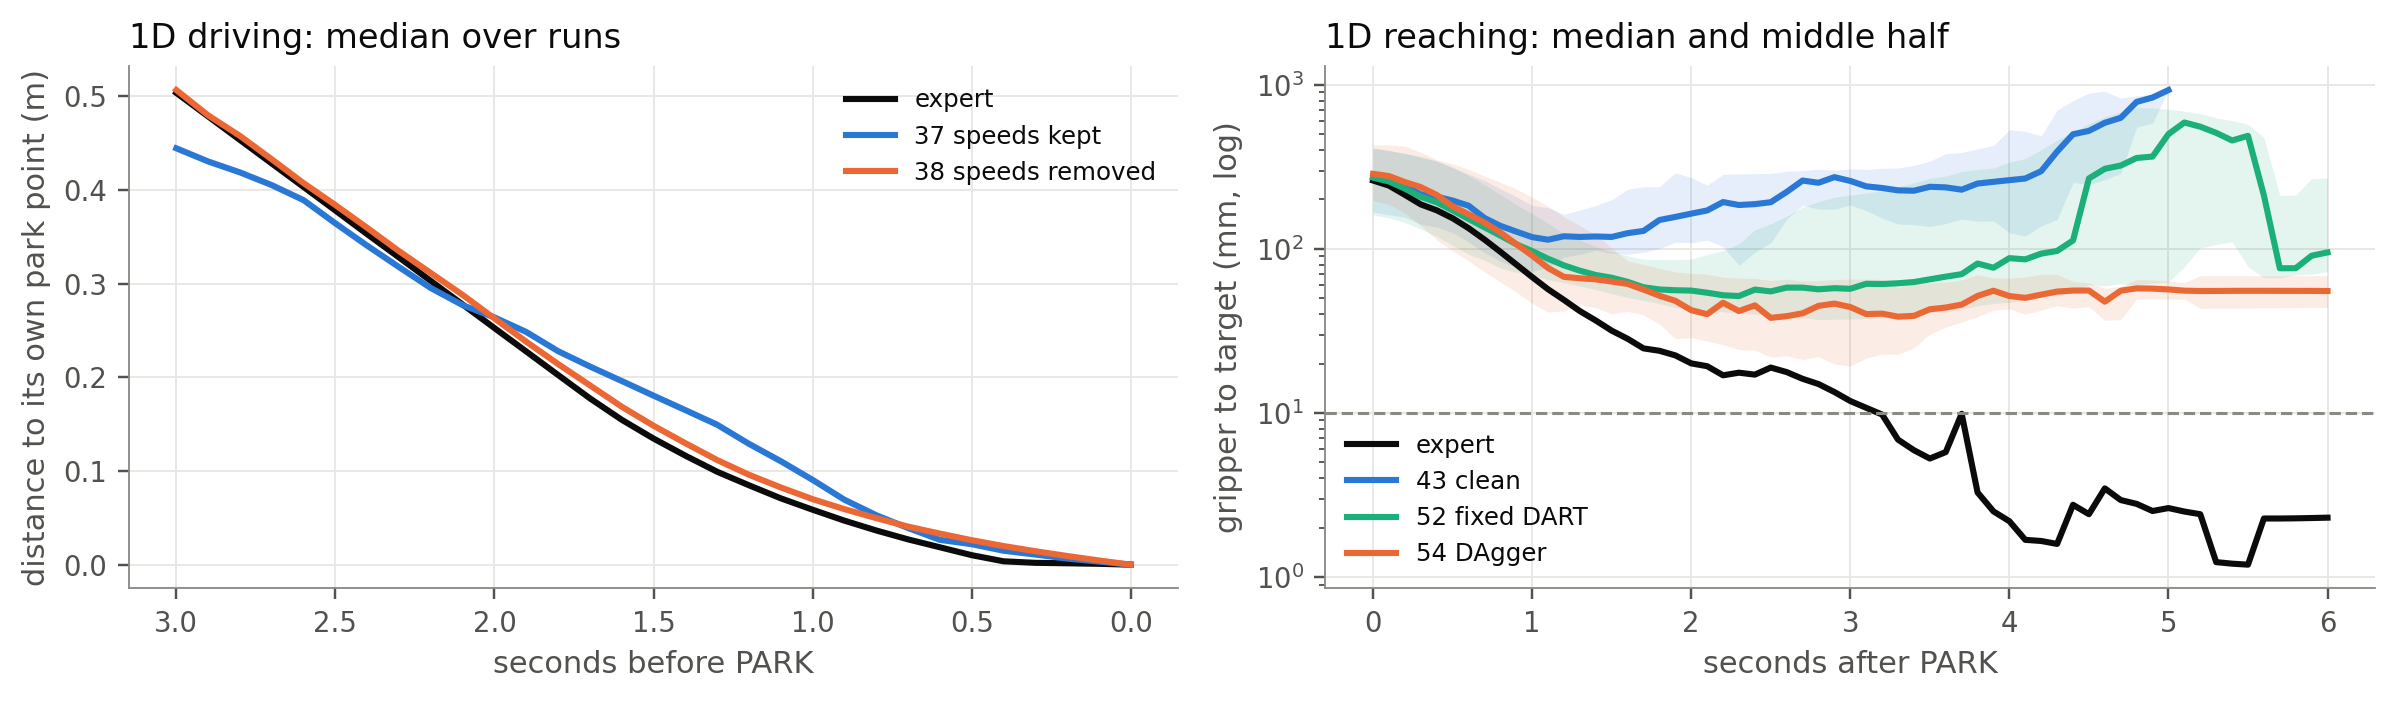

In [15]:
e = MAC['expert_1d']
display(pd.DataFrame([('Driving', 'path length / straight line (10th, 50th, 90th percentile)', e['path_over_straight']), ('Driving', 'share of drive within 10 degrees of target', e['share_of_drive_within_10deg']), ('Driving', 'base speed, 95th percentile (m/s)', e['base_speed_95pct_m_s']), ('Driving', 'time to PARK from distance to go, R²', e['ttp_from_distance_to_go_r2']), ('Driving', 'speed from distance to go, R²', e['speed_from_distance_to_go_r2']), ('Driving', 'range at PARK minus standoff table: median, SD (m)', [e['minus_standoff_table_median_m'], e['minus_standoff_table_sd_m']]), ('Reaching', 'gripper path / straight line', e['gripper_path_over_straight']), ('Reaching', 'share of frames where gripper distance does not grow', e['gripper_distance_not_growing']), ('Reaching', 'first principal direction of 7-joint path, per run', e['joint_path_pc1_per_run']), ('Reaching', 'first three directions, pooled over runs', e['joint_path_pc123_pooled']), ('Reaching', 'normalised distance curve, variance explained by one mean curve', e['reach_curve_variance_explained'])], columns=['phase', 'measure', 'value']))
if COMP:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.3)); G = np.array(COMP['expert']['grid'])
    ax[0].plot(COMP['expert']['range_to_go_grid'], COMP['expert']['range_to_go_m']['median'], color=INK, label='expert')
    for k in ('height', 'no_speed'):
        if k in COMP: ax[0].plot(COMP['expert']['range_to_go_grid'], COMP[k]['range_to_go_m']['median'], color=COL[k], label={'height': '37 speeds kept', 'no_speed': '38 speeds removed'}[k])
    ax[0].set_xlabel('seconds before PARK'); ax[0].set_ylabel('distance to its own park point (m)'); ax[0].set_title('1D driving: median over runs'); ax[0].invert_xaxis(); ax[0].legend(fontsize=8)
    ax[1].plot(G, COMP['expert']['gripper_mm']['median'], color=INK, label='expert')
    for k in ('basics_standard', 'dart', 'dagger'):
        ax[1].plot(G, COMP[k]['gripper_mm']['median'], color=COL[k], label=SHORT[k]); ax[1].fill_between(G, COMP[k]['gripper_mm']['p25'], COMP[k]['gripper_mm']['p75'], color=COL[k], alpha=.12, lw=0)
    ax[1].axhline(10, color=MUTED, ls='--', lw=1); ax[1].set_yscale('log'); ax[1].set_xlabel('seconds after PARK'); ax[1].set_ylabel('gripper to target (mm, log)'); ax[1].set_title('1D reaching: median and middle half'); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Reading.** The expert's range at PARK is the standoff table plus 5.8 cm with an SD of 1.4 cm, so parking is close to a function of height alone. In each run the 7-joint path is about one direction (94%), and it takes three directions across runs, one per coordinate of the target. Two things do not reduce: the blind turn, which is its own problem with no feedback on bearing, and torque, which acts through inertia, so the arm is a harder kind of 1D problem than the wheels.

## 3.12 Driving in 1D: how strongly the command reacts

In one dimension the loop is `δ(t+1) = δ(t) - dt·ρ·δu(t)`, `δu(t) = a·δu(t-1) + k·δ(t)`, with `k` the gain on range, `a` the gain on the network's own measured speed, and ρ the wheel radius, 0.11 m. These are read exactly from the network: a ReLU network is piecewise linear (Lecture 3.2), so its local slope comes from the active units. Reference: the expert's law `v = clip(1.0·d, 0.05, 0.25)` gives k = 9.1 rad/s per m and a 1 s time constant in the last 25 cm. Method not from the course.

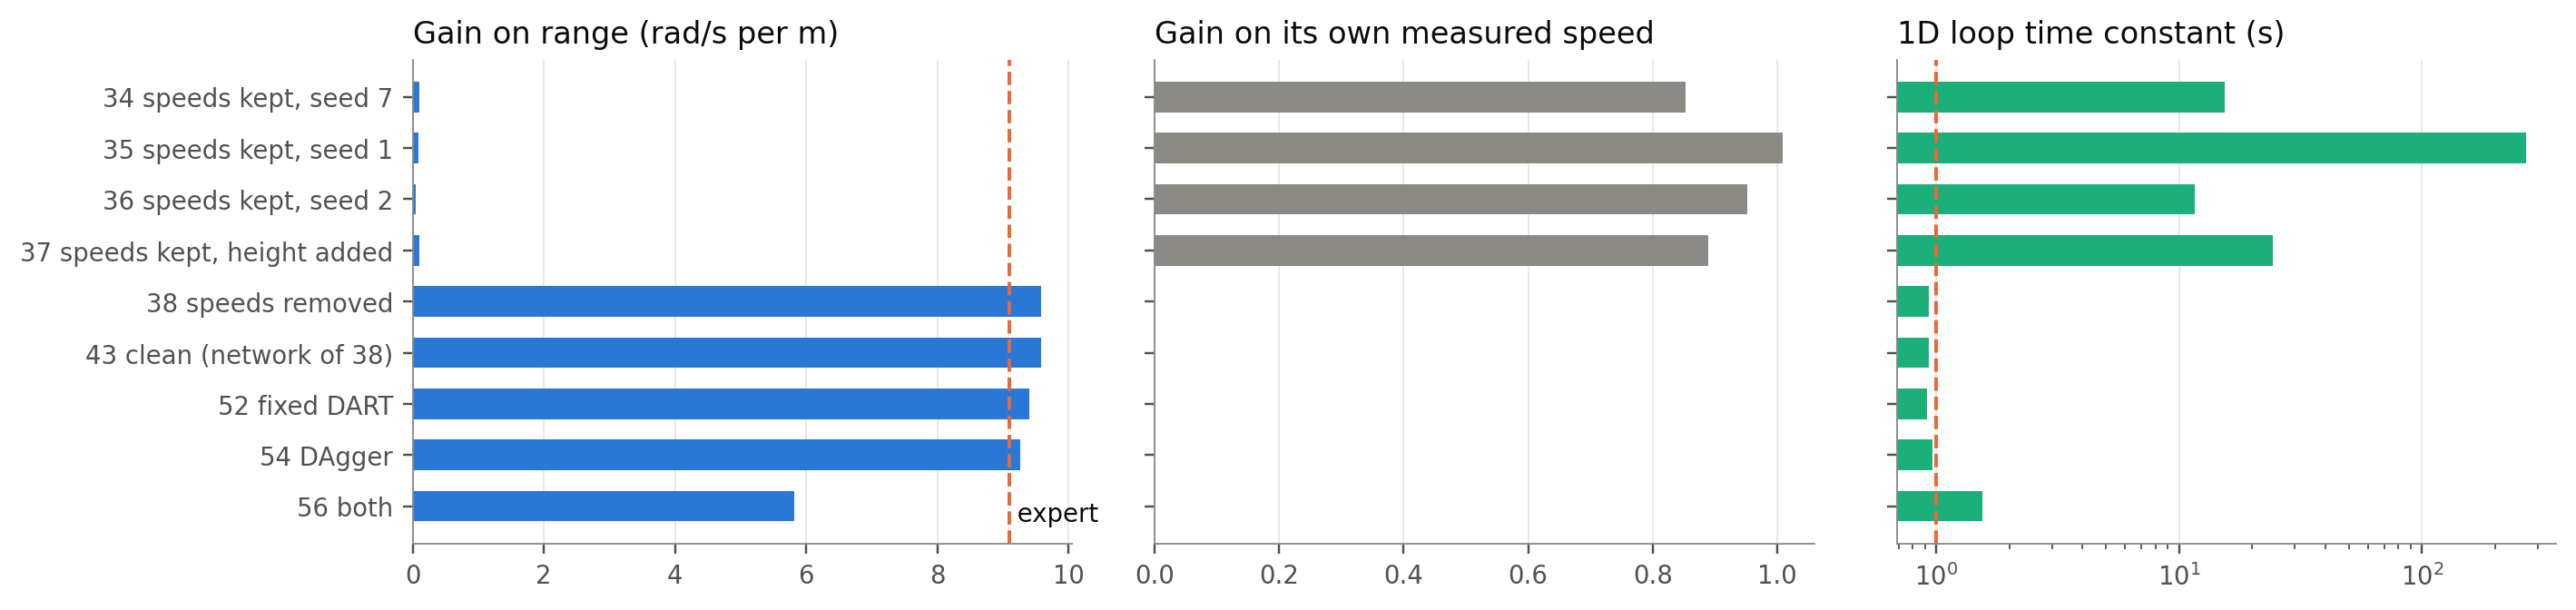

,model,range_gain,self_gain,steering_gain,ttp_s_per_m,time_constant_s,share_not_decaying
0,"34 speeds kept, seed 7",0.108,0.853,1.320,0.373,15.406,0.132
1,"35 speeds kept, seed 1",0.092,1.009,1.635,0.880,268.821,0.688
2,"36 speeds kept, seed 2",0.050,0.952,1.780,0.176,11.602,0.249
3,"37 speeds kept, height added",0.096,0.889,1.299,0.249,24.377,0.294
4,38 speeds removed,9.573,0.000,2.325,11.019,0.933,0.035
5,43 clean (network of 38),9.573,0.000,2.325,11.019,0.933,0.035
6,52 fixed DART,9.396,0.000,2.244,10.660,0.915,0.031
7,54 DAgger,9.258,0.000,10.832,9.822,0.965,0.005
8,56 both,5.814,0.000,9.409,8.145,1.547,0.001


In [16]:
if EXTRA and 'driving_gains' in EXTRA:
    g = EXTRA['driving_gains']; P = 'last 1 s before PARK'; keys = [k for k in g if k != 'expert']; show = {'34 speeds kept, seed 7': '34 speeds kept, seed 7', '35 speeds kept, seed 1': '35 speeds kept, seed 1', '36 speeds kept, seed 2': '36 speeds kept, seed 2', '37 speeds kept, height added': '37 speeds kept, height added', '38 speeds removed': '38 speeds removed', '43 basics_standard': '43 clean (network of 38)', '52 dart': '52 fixed DART', '54 dagger': '54 DAgger', '56 dart_dagger': '56 both'}; rows = [dict(model=show[k], range_gain=g[k][P]['range_gain_rad_s_per_m'][0], self_gain=g[k][P]['self_gain'][0], steering_gain=g[k][P]['steering_gain'][0], ttp_s_per_m=g[k][P]['ttp_s_per_m'][0], time_constant_s=g[k][P]['time_constant_s'][0], share_not_decaying=g[k][P]['share_not_decaying']) for k in keys]
    T = pd.DataFrame(rows); fig, ax = plt.subplots(1, 3, figsize=(13, 3.2)); y = np.arange(len(T))[::-1]
    ax[0].barh(y, T.range_gain, color=BLUE, height=.6); ax[0].axvline(1 / .11, color=ORANGE, lw=1.3, ls='--'); ax[0].set_yticks(y); ax[0].set_yticklabels(T.model); ax[0].set_title('Gain on range (rad/s per m)'); ax[0].text(1 / .11, y[-1] - .3, ' expert', color=INK, fontsize=9)
    ax[1].barh(y, T.self_gain, color=MUTED, height=.6); ax[1].set_yticks(y); ax[1].set_yticklabels([]); ax[1].set_title('Gain on its own measured speed')
    ax[2].barh(y, T.time_constant_s, color=AQUA, height=.6); ax[2].axvline(1, color=ORANGE, lw=1.3, ls='--'); ax[2].set_yticks(y); ax[2].set_yticklabels([]); ax[2].set_title('1D loop time constant (s)'); ax[2].set_xscale('log')
    for a in ax: a.grid(axis='y', visible=False)
    plt.tight_layout(); plt.show(); display(T.round(3))

**Reading.** Prediction held, more cleanly than I expected. With speed inputs the range gain is 0.05 to 0.11 rad/s per metre, about 100 times below the expert's 9.1, and the gain on measured speed is 0.85 to 1.01, close to 1. That is a network repeating its last command with almost no regard for range. Without them, the gain is 9.6 and the time constant 0.93 s, against the expert's 9.1 and 1 s. Nobody told it that law: it came out of the data once the shortcut was gone. Iterations 38 and 43 share one driving network, so they have one row each with the same values. DAgger also raises the steering gain from 2.3 to 10.8. The expert's law has its own steering, and I did not compare that.

## 3.13 Arm gains: did recovery data teach feedback?

From the same exact local slopes: K is how strongly torque reacts to joint angle, D to joint speed, and the target gain is N m per cm of target movement. The expert's own PD law is K = 100 and D = 30. Noise line: encoder noise of 0.14 rad/s on speed, through D, as torque noise.

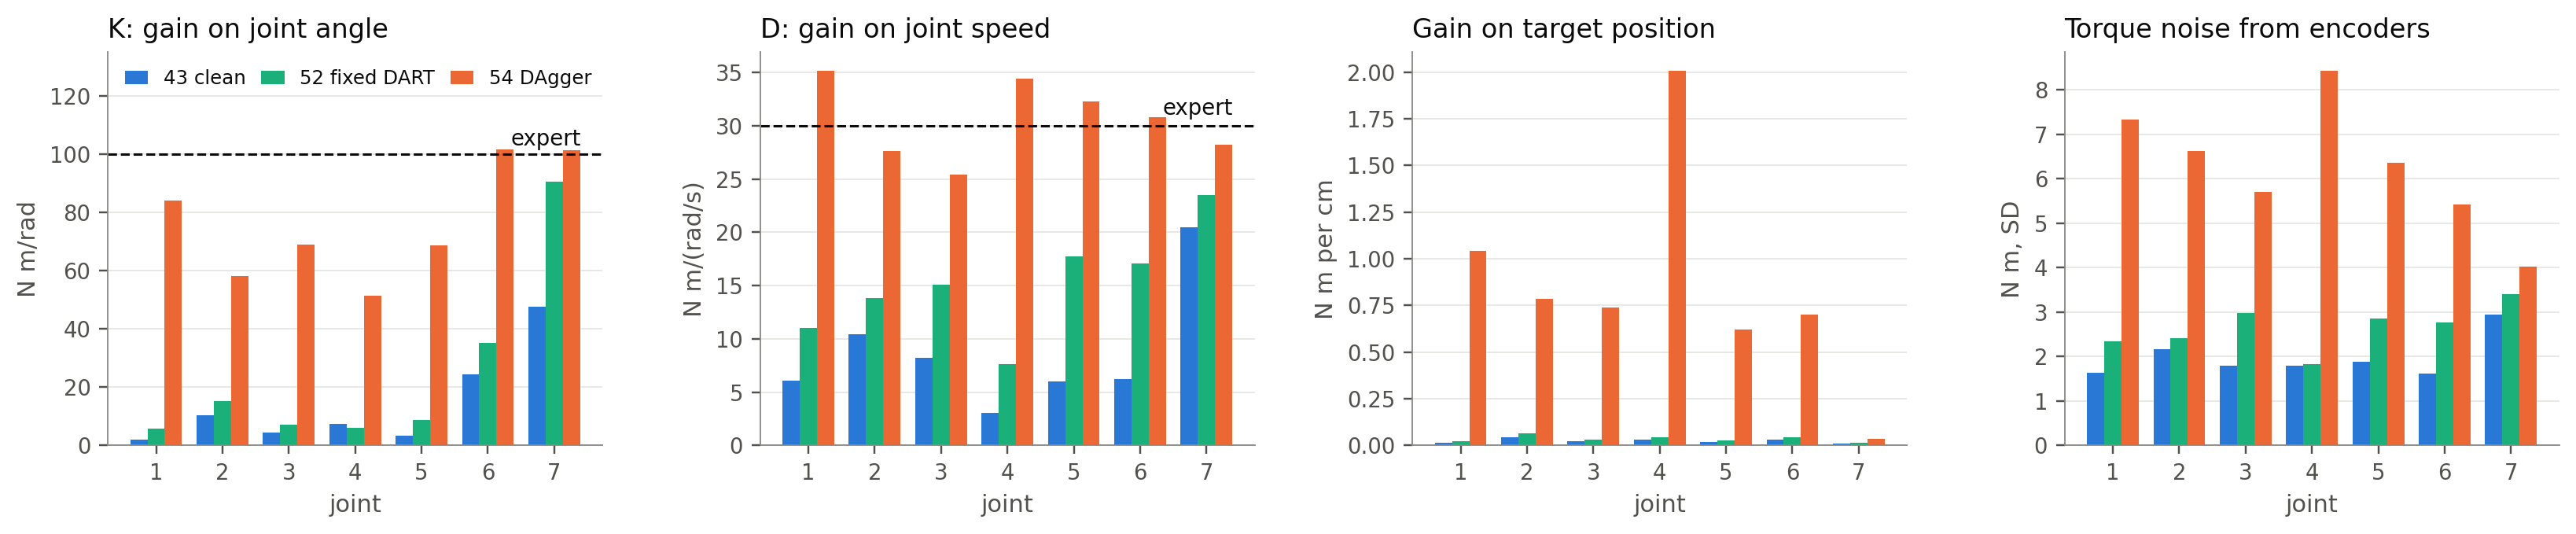

,model,K_median,D_median,target_gain_median,noise_torque_median,torque_rmse
0,41 learned arm,4.712,8.045,0.055,2.685,0.378
1,43 clean,7.488,6.237,0.024,1.791,0.296
2,52 fixed DART,8.666,15.104,0.031,2.758,0.303
3,54 DAgger,68.963,30.837,0.740,6.360,1.189
4,56 both,80.962,27.225,0.836,5.287,0.915


In [17]:
if DEEP:
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.2)); x = np.arange(1, 8); w = .26; L = ['basics_standard', 'dart', 'dagger']
    for i, k in enumerate(L):
        g = DEEP['models'][k]['arm_gains']; off = (i - 1) * w
        ax[0].bar(x + off, g['k_diag_median'], w, color=COL[k], label=SHORT[k]); ax[1].bar(x + off, g['d_diag_median'], w, color=COL[k]); ax[2].bar(x + off, g['target_gain_nm_per_cm'], w, color=COL[k]); ax[3].bar(x + off, g['torque_noise_sd_nm'], w, color=COL[k])
    ax[0].axhline(100, color=INK, ls='--', lw=1); ax[0].text(7.4, 103, 'expert', ha='right', fontsize=9); ax[1].axhline(30, color=INK, ls='--', lw=1); ax[1].text(7.4, 31, 'expert', ha='right', fontsize=9)
    for a, t, u in zip(ax, ('K: gain on joint angle', 'D: gain on joint speed', 'Gain on target position', 'Torque noise from encoders'), ('N m/rad', 'N m/(rad/s)', 'N m per cm', 'N m, SD')): a.set_title(t); a.set_ylabel(u); a.set_xlabel('joint'); a.set_xticks(x); a.grid(axis='x', visible=False)
    ax[0].set_ylim(0, 135); ax[0].legend(fontsize=8, loc='upper left', ncol=3, columnspacing=.8, handlelength=1.2); plt.tight_layout(); plt.show()
    display(pd.DataFrame([dict(model=SHORT[k], K_median=np.median(DEEP['models'][k]['arm_gains']['k_diag_median']), D_median=np.median(DEEP['models'][k]['arm_gains']['d_diag_median']), target_gain_median=np.median(DEEP['models'][k]['arm_gains']['target_gain_nm_per_cm']), noise_torque_median=np.median(DEEP['models'][k]['arm_gains']['torque_noise_sd_nm']), torque_rmse=np.mean([q['rmse'] for q in OFF['models'][k]['torque']])) for k in MODELS]).round(3))

**Reading.** Median K goes from 7 to 69 N m/rad and D from 6 to 31, and the expert's are 100 and 30. Fixed noise sits between (9, 15). A supported explanation: each expert reach is close to one direction in joint space (Section 3.11), so a demonstration says little about how to respond to a displacement in other directions. Several networks can then match the torques along the path while having very different slopes away from it. DAgger rows supply those slopes. PCA alone cannot establish that the demonstrations caused the low gains, so this is an explanation and not a proof.

The cost is measurement sensitivity. Encoder noise passes through D, so torque noise is 1.6 to 2.9 N m for the clean model and 4.0 to 8.4 N m for DAgger. Stronger gains correct a real displacement and also amplify a false one reported by a noisy sensor. The training noise and the sensor noise also differ in kind: action noise held for 33 ms, against encoder noise entering a 1 ms backward difference.

## 3.14 Is each network a stable controller? (Zhang 2025)

Zhang names control-theoretic stability as the mechanism behind compounding, and calls it the continuous form of recoverability. Linearise robot plus network around saved states: `M(q) δq̈ = (∂τ/∂q − ∂G/∂q) δq + (∂τ/∂q̇) δq̇`, with M and G from the simulator's own model, 1 kg link included. A positive growth rate means small errors grow on their own. Also shown: the discrete loop at 1 ms using the backward-difference speed, with and without the 3 ms delay. The simulator is not stepped. Method not from the course. Local linear checks on a piecewise linear network do not prove behaviour over a whole run.

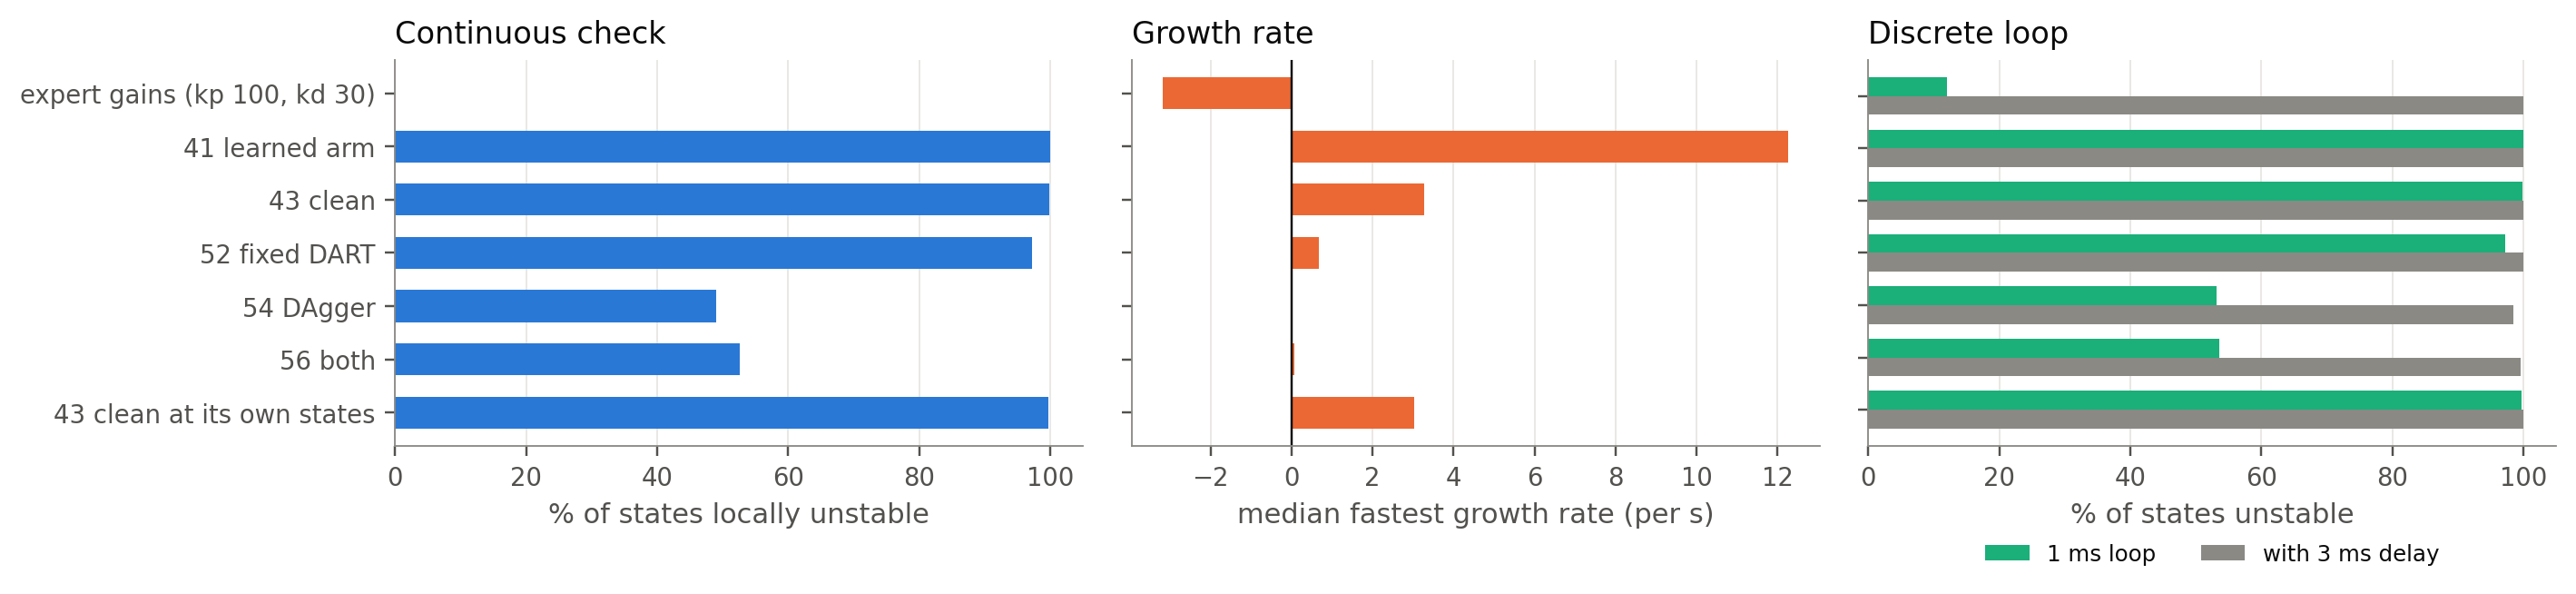

,model,rows,unstable_pct,growth_p10,growth_p50,growth_p90,e_fold_s,radius_1ms,unstable_1ms_pct,unstable_3ms_pct
0,"expert gains (kp 100, kd 30)",300,0.000,-3.183,-3.175,-3.165,NaN,0.997,12.000,100.000
1,41 learned arm,1209,100.000,1.806,12.267,47.284,0.082,1.013,100.000,100.000
2,43 clean,1209,99.835,0.890,3.265,22.599,0.305,1.003,99.835,100.000
3,52 fixed DART,1209,97.270,0.152,0.681,2.785,1.429,1.001,97.270,100.000
4,54 DAgger,1209,49.049,-0.861,-0.020,4.360,1.027,1.000,53.184,98.428
5,56 both,1209,52.605,-0.899,0.077,3.408,1.251,1.000,53.515,99.586
6,43 clean at its own states,819,99.756,0.997,3.034,21.191,0.329,1.003,99.756,100.000


In [18]:
if STAB:
    L = list(STAB); nice = lambda k: SHORT.get(k, k.replace('basics_standard', '43 clean')); fig, ax = plt.subplots(1, 3, figsize=(13, 3.2)); y = np.arange(len(L))[::-1]
    ax[0].barh(y, [STAB[k]['unstable_share'] * 100 for k in L], color=BLUE, height=.6); ax[0].set_yticks(y); ax[0].set_yticklabels([nice(k) for k in L]); ax[0].set_xlabel('% of states locally unstable'); ax[0].set_title('Continuous check')
    ax[1].barh(y, [STAB[k]['growth_rate_per_s'][1] for k in L], color=ORANGE, height=.6); ax[1].axvline(0, color=INK, lw=.8); ax[1].set_yticks(y); ax[1].set_yticklabels([]); ax[1].set_xlabel('median fastest growth rate (per s)'); ax[1].set_title('Growth rate')
    h = .36; ax[2].barh(y + h / 2, [STAB[k]['unstable_share_1ms'] * 100 for k in L], h, color=AQUA, label='1 ms loop'); ax[2].barh(y - h / 2, [STAB[k]['unstable_share_3ms_delay'] * 100 for k in L], h, color=MUTED, label='with 3 ms delay'); ax[2].set_yticks(y); ax[2].set_yticklabels([]); ax[2].set_xlabel('% of states unstable'); ax[2].set_title('Discrete loop'); ax[2].legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.2), ncol=2)
    for a in ax: a.grid(axis='y', visible=False)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame([dict(model=nice(k), rows=STAB[k]['rows'], unstable_pct=STAB[k]['unstable_share'] * 100, growth_p10=STAB[k]['growth_rate_per_s'][0], growth_p50=STAB[k]['growth_rate_per_s'][1], growth_p90=STAB[k]['growth_rate_per_s'][2], e_fold_s=STAB[k]['e_fold_time_s_if_unstable'], radius_1ms=STAB[k]['spectral_radius_1ms'][0], unstable_1ms_pct=STAB[k]['unstable_share_1ms'] * 100, unstable_3ms_pct=STAB[k]['unstable_share_3ms_delay'] * 100) for k in L]).round(3))

**Reading.** Exploratory: local linear checks on a piecewise linear network, on saved states. They do not prove behaviour over a run and should not carry the central conclusion. The expert's gains are stable everywhere (-3.17 per second). The clean arm is locally unstable at 99.8% of expert states, growth rate 3.26 per second. Learning to hold without standardising gives 12.27 per second, fixed DART 0.68, DAgger -0.02 with 49% of states unstable. The check at the clean model's own states gives about the same result as at the expert's. The 3 ms delay column marks every model as unstable, the expert's gains included, so it cannot separate them and I would not use it. Over a whole run errors do not grow by the factor these rates imply, because the state keeps moving through different linear regions.

## 3.15 How error grows after a mistake (Ross, Choudhury L03, L04, L09)

BC can compound with T², on-policy data gives T. For each test run, distance in joint space from the expert's path, by time since PARK. Growth exponent is the log-log slope per run between 0.1 and 2 s. 1 means linear growth, 2 quadratic. Bounds in the papers are worst cases on a different cost, so this is an illustration and does not test the bound.

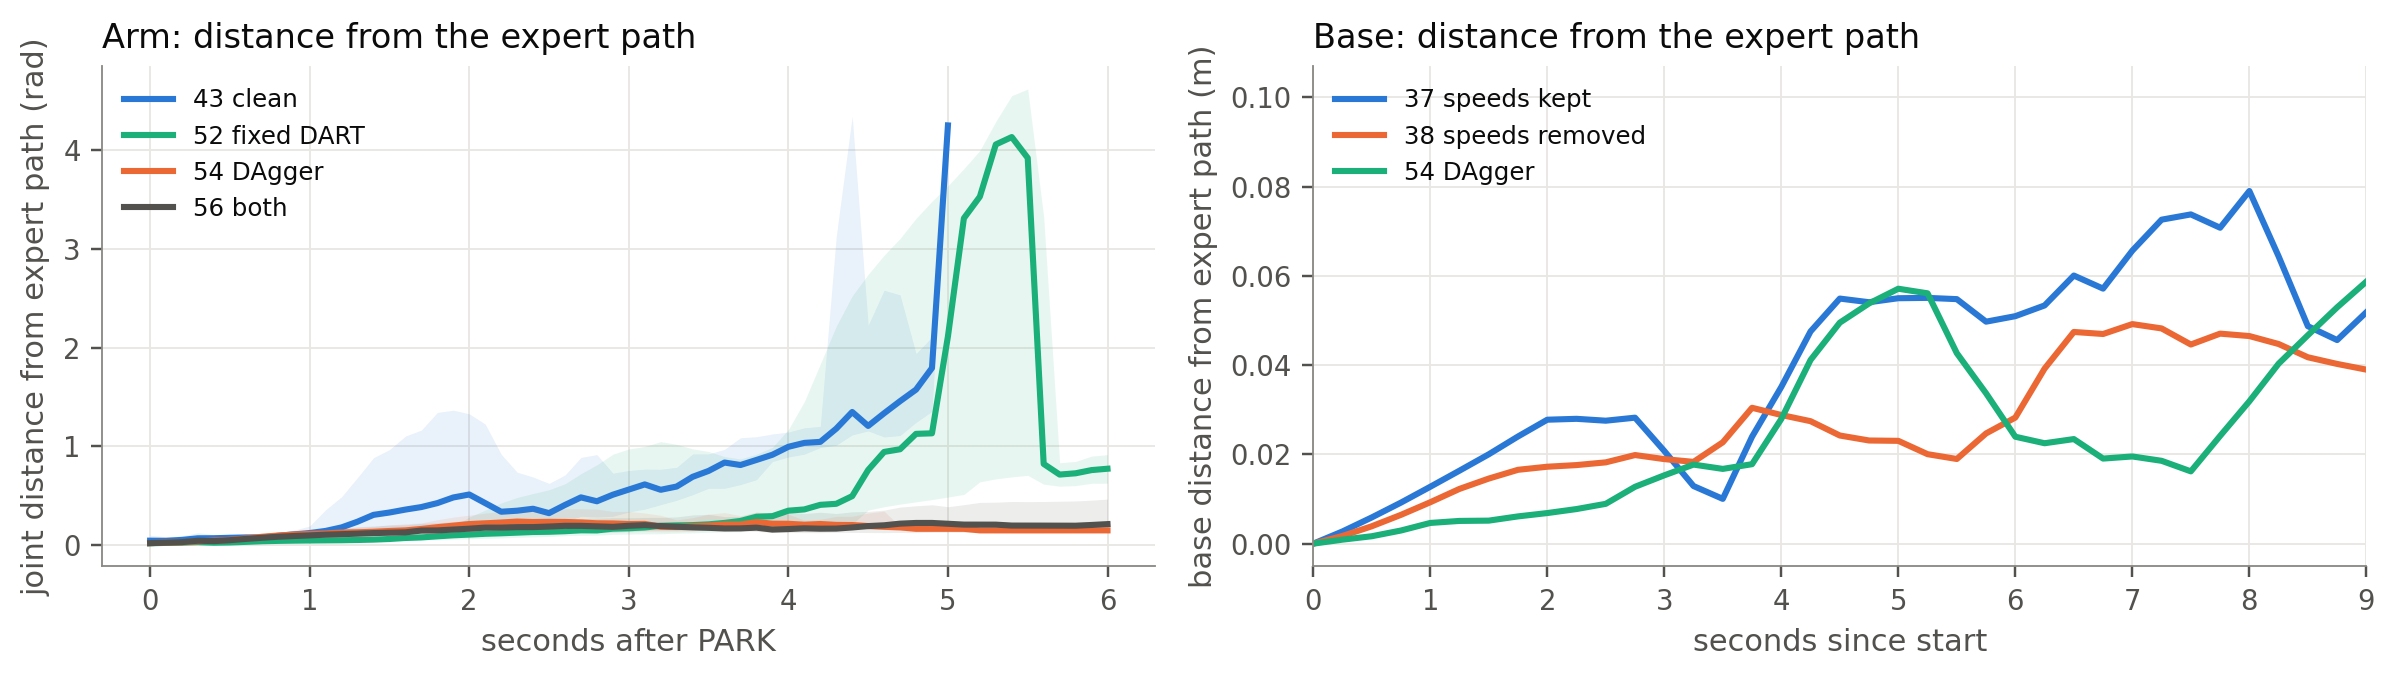

,model,growth_exponent_arm,growth_exponent_base,park_along_range_cm,park_sideways_cm,park_heading_deg,tracker_range_err_at_park_mm
0,37 speeds kept,1.291,0.874,17.686,6.660,10.378,7.746
1,38 speeds removed,1.516,0.803,3.732,3.691,2.826,8.597
2,41 learned arm,0.530,0.793,3.317,3.491,2.990,8.464
3,43 clean,0.911,0.800,3.376,3.778,2.936,9.044
4,52 fixed DART,0.601,0.749,2.955,3.854,2.934,9.243
5,54 DAgger,0.771,0.843,3.269,2.567,2.989,8.984
6,56 both,0.801,0.900,2.704,3.386,1.766,9.691


In [19]:
if COMP:
    G = np.array(COMP['expert']['grid']); fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    for k in ('basics_standard', 'dart', 'dagger', 'dart_dagger'):
        v = COMP[k]['joint_dev_rad']; ax[0].plot(G, v['median'], color=COL[k], label=SHORT[k]); ax[0].fill_between(G, v['p25'], v['p75'], color=COL[k], alpha=.1, lw=0)
    ax[0].set_xlabel('seconds after PARK'); ax[0].set_ylabel('joint distance from expert path (rad)'); ax[0].set_title('Arm: distance from the expert path'); ax[0].legend(fontsize=8)
    Gb = np.arange(0, 12.01, .25)
    for k, col, lab in (('height', BLUE, '37 speeds kept'), ('no_speed', ORANGE, '38 speeds removed'), ('dagger', AQUA, '54 DAgger')):
        if k in COMP: ax[1].plot(Gb, COMP[k]['base_path_dev_m']['median'], color=col, label=lab)
    ax[1].set_xlim(0, 9); ax[1].set_xlabel('seconds since start'); ax[1].set_ylabel('base distance from expert path (m)'); ax[1].set_title('Base: distance from the expert path'); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
    display(pd.DataFrame([dict(model={'height': '37 speeds kept', 'no_speed': '38 speeds removed', **SHORT}[k], growth_exponent_arm=COMP[k]['growth_exponent_joint'][0], growth_exponent_base=COMP[k]['growth_exponent_base'][0], park_along_range_cm=COMP[k]['park_radial_abs_cm'][0], park_sideways_cm=COMP[k]['park_tangential_cm'][0], park_heading_deg=COMP[k]['park_heading_deg'][0], tracker_range_err_at_park_mm=COMP[k]['tracker_range_err_at_park_mm'][0]) for k in COMP if k != 'expert']).round(3))

**Reading.** No T² against T here. Exponents are 0.91 for the clean arm ([0.73, 1.13]), 0.77 for DAgger ([0.69, 0.88]) and 0.60 for fixed DART, overlapping and all at or below linear. The bounds are worst cases, on a different cost, so this does not contradict them, but the report should not claim to show them. What separates the models is the level of the curve: the size of the error early on, rather than its growth rate.

## 3.16 How far is fixed noise from Laskey's rule?

True DART sets the noise covariance from the model's own residuals. So: residual SD of the model on the expert's training states, against what we injected, 0.025 rad/s on the wheels and 0.5 N m on the arm. An initial 0.1 rad/s caused a navigation timeout in a pilot, which is why the wheel noise is so small. Zhang finds larger noise helps within tolerance, and that clean labels and a clean plus noisy mix are what matter.

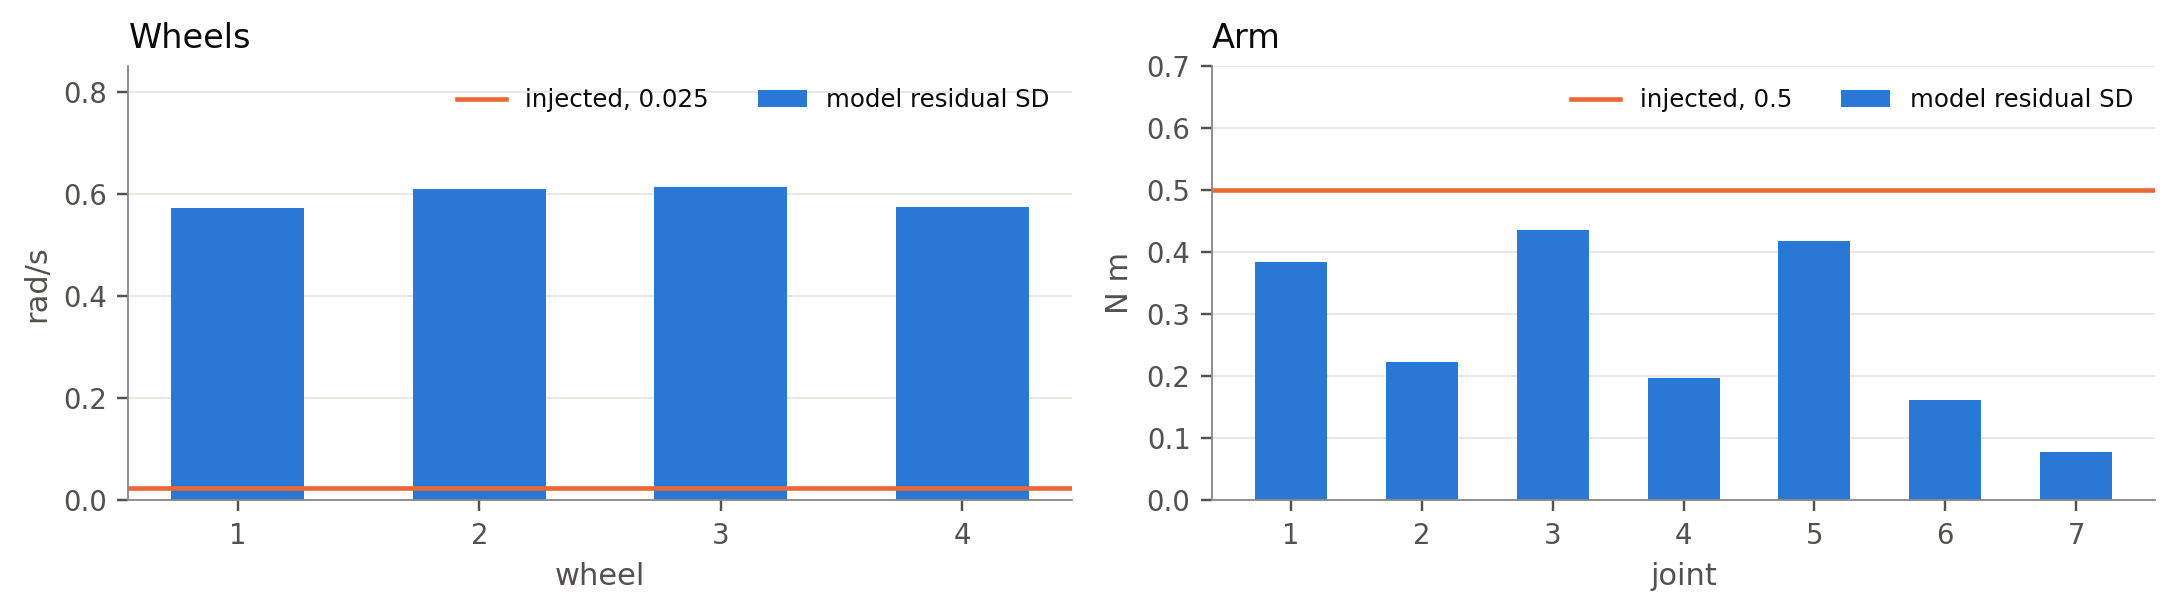

,ratio_wheel,ratio_torque,wheel_cov_trace,torque_cov_trace
basics_standard,23.705,0.603,1.405,0.634
dart,23.802,0.628,1.416,0.688


In [20]:
if EXTRA and 'dart_noise' in EXTRA:
    d = EXTRA['dart_noise']['basics_standard']; fig, ax = plt.subplots(1, 2, figsize=(10, 2.9))
    ax[0].bar(range(1, 5), d['wheel_residual_sd'], color=BLUE, width=.55, label='model residual SD'); ax[0].axhline(.025, color=ORANGE, lw=1.5, label='injected, 0.025'); ax[0].set_xticks(range(1, 5)); ax[0].set_ylim(0, .85); ax[0].set_xlabel('wheel'); ax[0].set_ylabel('rad/s'); ax[0].set_title('Wheels'); ax[0].legend(fontsize=8, loc='upper right', ncol=2)
    ax[1].bar(range(1, 8), d['torque_residual_sd'], color=BLUE, width=.55, label='model residual SD'); ax[1].axhline(.5, color=ORANGE, lw=1.5, label='injected, 0.5'); ax[1].set_ylim(0, .7); ax[1].set_xlabel('joint'); ax[1].set_ylabel('N m'); ax[1].set_title('Arm'); ax[1].legend(fontsize=8, loc='upper right', ncol=2)
    for a in ax: a.grid(axis='x', visible=False)
    plt.tight_layout(); plt.show(); display(pd.DataFrame(EXTRA['dart_noise']).T[['ratio_wheel', 'ratio_torque', 'wheel_cov_trace', 'torque_cov_trace']].astype(float).round(3))

**Reading.** Model error on the expert's states is 0.6 times the injected noise on the arm and 24 times on the wheels. This shows a scale mismatch worth investigating, and it does not show that the arm noise was right or that an adaptive version would do better. Part of the wheel residual is the blind start, which noise cannot fix. It does fit one observation: the driving gains of 52 match the clean model while its arm feedback changes (Sections 3.12 and 3.13).

## 3.17 Do the heads compete for the shared layers? (GradNorm, PCGrad, Kirchdorfer, UDL 9.3.6)

Gradient size of each head's loss on the shared layers, and the angle between them. GradNorm says the larger gradient dominates; PCGrad counts cosine below 0 as conflict, and magnitude similarity near 0 as domination. The last column is the weight an inverse-loss rule (Kirchdorfer) would give the extra head.

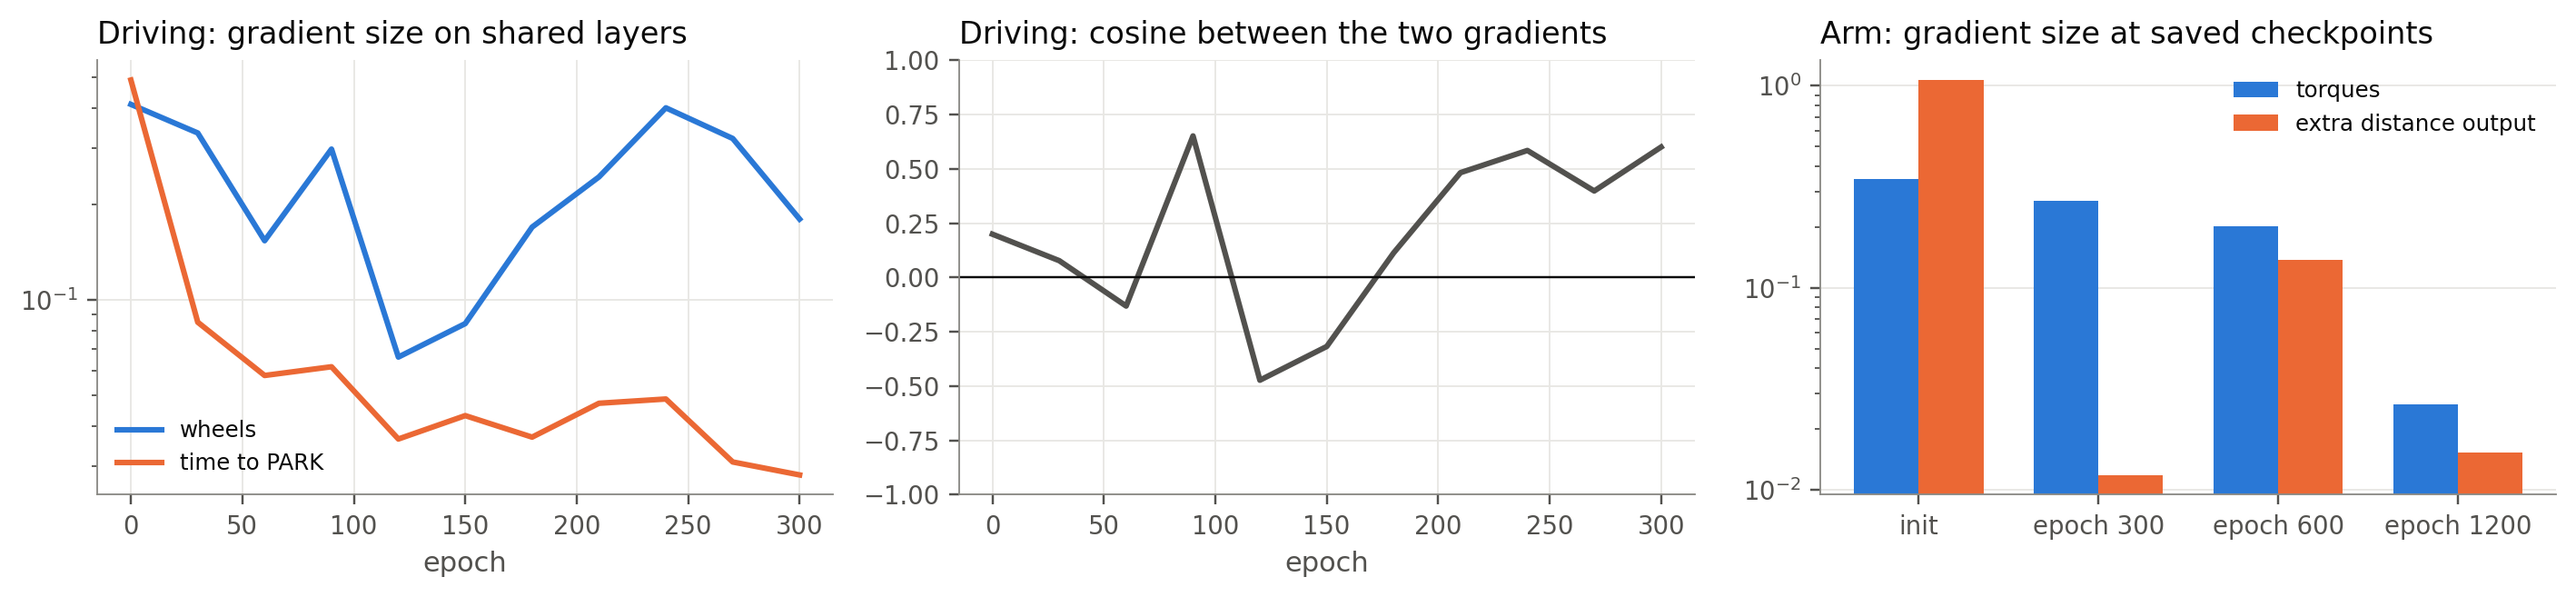

,epoch,loss_command,loss_aux,grad_norm_command,grad_norm_aux,norm_ratio,cosine,inverse_loss_weights_aux_over_command
0,0,3.0314,0.2626,0.4113,0.4906,0.8383,0.1993,11.5427
1,30,1.3652,0.0441,0.3344,0.0850,3.9334,0.0773,30.9494
5,150,0.3881,0.0108,0.0842,0.0432,1.9462,-0.3177,35.8384
10,300,0.2888,0.0082,0.1793,0.0282,6.3690,0.6005,35.2165


,checkpoint,loss_command,loss_aux,grad_norm_command,grad_norm_aux,norm_ratio,cosine,inverse_loss_weights_aux_over_command
0,init,0.9848,0.7189,0.3462,1.0671,0.3245,0.0164,1.3699
1,epoch 300,0.0200,0.0023,0.2681,0.0118,22.6646,-0.0012,8.7890
2,epoch 600,0.0150,0.0039,0.2012,0.1377,1.4618,-0.0353,3.7972
3,epoch 1200,0.0086,0.0007,0.0264,0.0152,1.7334,0.0273,11.5744


In [21]:
if HEAD:
    d = pd.DataFrame(HEAD['driving_retrained_300_epochs']); a = pd.DataFrame(HEAD['arm_saved_checkpoints']); fig, ax = plt.subplots(1, 3, figsize=(13, 3.1))
    ax[0].plot(d.epoch, d.grad_norm_command, color=BLUE, label='wheels'); ax[0].plot(d.epoch, d.grad_norm_aux, color=ORANGE, label='time to PARK'); ax[0].set_yscale('log'); ax[0].set_xlabel('epoch'); ax[0].set_title('Driving: gradient size on shared layers'); ax[0].legend(fontsize=8)
    ax[1].plot(d.epoch, d.cosine, color=GREY); ax[1].axhline(0, color=INK, lw=.8); ax[1].set_xlabel('epoch'); ax[1].set_title('Driving: cosine between the two gradients'); ax[1].set_ylim(-1, 1)
    x = np.arange(len(a)); w = .36; ax[2].bar(x - w / 2, a.grad_norm_command, w, color=BLUE, label='torques'); ax[2].bar(x + w / 2, a.grad_norm_aux, w, color=ORANGE, label='extra distance output'); ax[2].set_yscale('log'); ax[2].set_xticks(x); ax[2].set_xticklabels(a.checkpoint); ax[2].set_title('Arm: gradient size at saved checkpoints'); ax[2].legend(fontsize=8); ax[2].grid(axis='x', visible=False)
    plt.tight_layout(); plt.show()
    display(d.iloc[[0, 1, 5, -1]][['epoch', 'loss_command', 'loss_aux', 'grad_norm_command', 'grad_norm_aux', 'norm_ratio', 'cosine', 'inverse_loss_weights_aux_over_command']].round(4)); display(a[['checkpoint', 'loss_command', 'loss_aux', 'grad_norm_command', 'grad_norm_aux', 'norm_ratio', 'cosine', 'inverse_loss_weights_aux_over_command']].round(4))

**Reading.** By PCGrad's definition the driving heads do conflict for part of training: cosine is negative at 3 of 11 saved points, as low as -0.47, and ends at 0.60. The wheel gradient is 1.8 to 6.4 times the other after the first epoch. Losses end 35 to 1, so an inverse loss weight would give time to PARK about 35 times more. On the arm, cosine is between -0.035 and 0.027, close to orthogonal, and the ratio is 1.5 to 23. So domination on both networks, some conflict on driving, little on the arm. A hand-set weight of 10 had made parking worse, so the sizes alone do not decide this, and these methods remain untested here. This replaces the draft's single checkpoint figure.

## 3.18 Full runs on the test targets (Lecture 1.2, Lab 3, Lab 4)

Success counts with Wilson intervals, medians with bootstrap intervals over targets. Comparisons are target by target: an exact sign test on distances, which is the lecture's fair-coin test, and McNemar on events. Before looking at any result, the alpha for this list is 0.05, and Holm's correction is applied across the list because many comparisons on one reused test set inflate false positives. Lecture 1.2 also says p is not the probability that H0 is true.

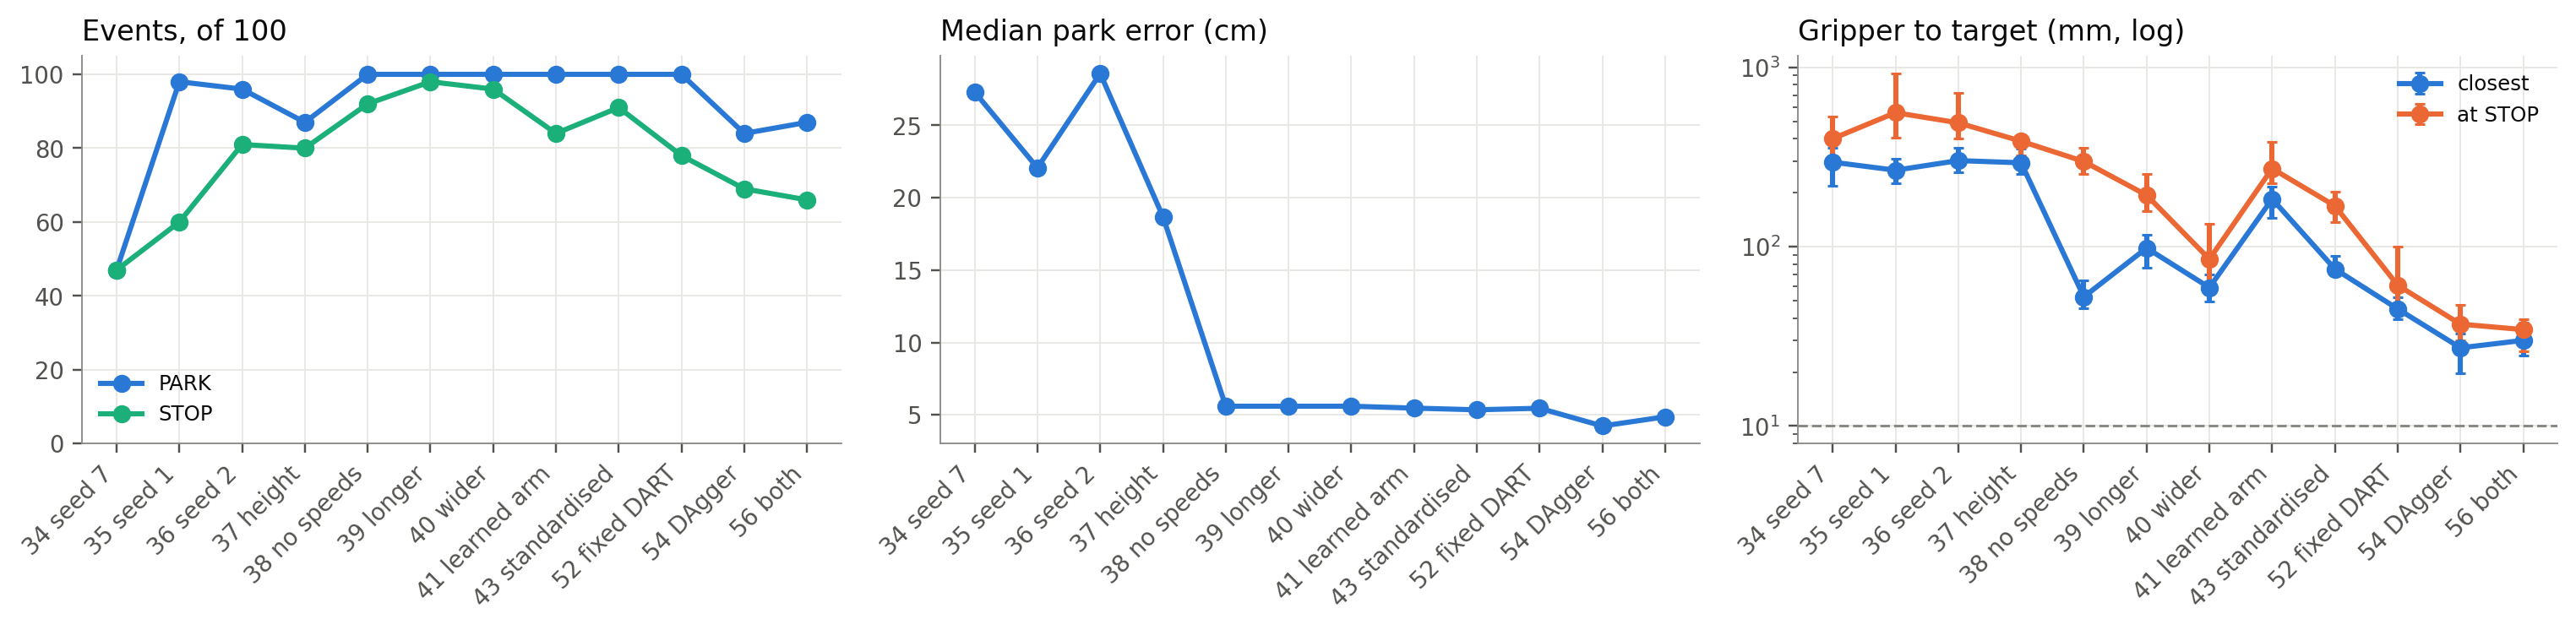

,model,PARK,STOP,success,success_low,success_high,park_error_cm,closest_mm,closest_low,closest_high,at_stop_mm,at_stop_low,at_stop_high
0,34 seed 7,47,47,0,0.0,3.7,27.3,295.8,217.3,357.7,400.4,318.6,532.4
1,35 seed 1,98,60,0,0.0,3.7,22.1,266.9,224.6,308.7,558.8,407.5,923.8
2,36 seed 2,96,81,0,0.0,3.7,28.6,302.0,259.1,356.6,490.3,400.8,720.1
3,37 height,87,80,0,0.0,3.7,18.7,293.5,253.1,351.1,387.5,324.5,419.6
4,38 no speeds,100,92,0,0.0,3.7,5.6,52.5,45.4,64.7,298.5,253.2,357.2
5,39 longer,100,98,0,0.0,3.7,5.6,98.3,76.5,116.4,193.7,158.6,255.5
6,40 wider,100,96,2,0.6,7.0,5.6,59.1,49.4,70.3,85.2,61.8,134.8
7,41 learned arm,100,84,0,0.0,3.7,5.5,184.5,143.9,216.2,272.7,226.3,383.1
8,43 standardised,100,91,0,0.0,3.7,5.3,75.1,69.3,88.4,168.8,136.5,201.5
9,52 fixed DART,100,78,1,0.2,5.4,5.5,45.0,39.5,52.3,60.9,47.4,100.0


In [22]:
S = CL['summary']; order = [('seed7', '34 seed 7'), ('seed1', '35 seed 1'), ('seed2', '36 seed 2'), ('height', '37 height'), ('no_speed', '38 no speeds'), ('longer_arm', '39 longer'), ('wider_arm', '40 wider'), ('baseline', '41 learned arm'), ('basics_standard', '43 standardised'), ('dart', '52 fixed DART'), ('dagger', '54 DAgger'), ('dart_dagger', '56 both')]
T = pd.DataFrame([dict(model=l, PARK=S[k]['parked'], STOP=S[k]['stopped'], success=S[k]['success'], success_low=S[k]['success_ci'][0], success_high=S[k]['success_ci'][1], park_error_cm=S[k]['park_error_cm'][0], closest_mm=S[k]['closest_mm'][0], closest_low=S[k]['closest_mm'][1], closest_high=S[k]['closest_mm'][2], at_stop_mm=S[k]['at_stop_mm'][0], at_stop_low=S[k]['at_stop_mm'][1], at_stop_high=S[k]['at_stop_mm'][2]) for k, l in order])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5)); x = np.arange(len(T))
ax[0].plot(x, T.PARK, color=BLUE, marker='o', label='PARK'); ax[0].plot(x, T.STOP, color=AQUA, marker='o', label='STOP'); ax[0].set_title('Events, of 100'); ax[0].set_ylim(0, 105); ax[0].legend(fontsize=8)
ax[1].plot(x, T.park_error_cm, color=BLUE, marker='o'); ax[1].set_title('Median park error (cm)')
ax[2].errorbar(x, T.closest_mm, yerr=[T.closest_mm - T.closest_low, T.closest_high - T.closest_mm], color=BLUE, marker='o', capsize=2, label='closest'); ax[2].errorbar(x, T.at_stop_mm, yerr=[T.at_stop_mm - T.at_stop_low, T.at_stop_high - T.at_stop_mm], color=ORANGE, marker='o', capsize=2, label='at STOP'); ax[2].axhline(10, color=MUTED, ls='--', lw=1); ax[2].set_yscale('log'); ax[2].set_title('Gripper to target (mm, log)'); ax[2].legend(fontsize=8)
for a in ax: a.set_xticks(x); a.set_xticklabels(T.model, rotation=45, ha='right')
plt.tight_layout(); plt.show(); display(T.round(1))

In [23]:
def binom_two_sided(k, n):
    if n == 0: return 1.
    return min(1., 2 * sum(math.comb(n, i) for i in range(0, min(k, n - k) + 1)) / 2 ** n)
def compare(a, b, col):
    A, B = per_target(a), per_target(b); d = (B[col] - A[col]).dropna(); pos, neg = int((d > 0).sum()), int((d < 0).sum()); return dict(n=pos + neg, better=neg, worse=pos, median_change=d.median(), p=binom_two_sided(pos, pos + neg))
plan = [('37 to 38: remove speeds', 'height', 'no_speed', 'park_error_cm'), ('37 to 38: remove speeds', 'height', 'no_speed', 'closest_mm'), ('39 to 40: wider arm', 'longer_arm', 'wider_arm', 'closest_mm'), ('40 to 41: learn hold', 'wider_arm', 'baseline', 'closest_mm'), ('41 to 43: standardise', 'baseline', 'basics_standard', 'closest_mm'), ('43 to 52: fixed DART', 'basics_standard', 'dart', 'closest_mm'), ('43 to 52: fixed DART', 'basics_standard', 'dart', 'at_stop_mm'), ('43 to 54: DAgger', 'basics_standard', 'dagger', 'closest_mm'), ('43 to 54: DAgger', 'basics_standard', 'dagger', 'at_stop_mm'), ('52 to 56: add DAgger', 'dart', 'dart_dagger', 'at_stop_mm'), ('54 to 56: add DART', 'dagger', 'dart_dagger', 'closest_mm'), ('54 to 56: add DART', 'dagger', 'dart_dagger', 'at_stop_mm')]
R = pd.DataFrame([dict(comparison=l, measure=c_, **compare(a, b, c_)) for l, a, b, c_ in plan]); o = np.argsort(R.p.values); m = len(R); adj = np.zeros(m); run = 0
for rank, i in enumerate(o): run = max(run, (m - rank) * R.p.values[i]); adj[i] = min(1, run)
R['holm_p'] = adj; R['verdict_at_0.05'] = np.where(R.holm_p <= .05, 'reject H0', 'do not reject'); display(R.round(4))

,comparison,measure,n,better,worse,median_change,p,holm_p,verdict_at_0.05
0,37 to 38: remove speeds,park_error_cm,87,76,11,-14.2056,0.0000,0.0000,reject H0
1,37 to 38: remove speeds,closest_mm,87,82,5,-221.1896,0.0000,0.0000,reject H0
2,39 to 40: wider arm,closest_mm,100,60,40,-16.5596,0.0569,0.1707,do not reject
3,40 to 41: learn hold,closest_mm,100,14,86,103.2428,0.0000,0.0000,reject H0
4,41 to 43: standardise,closest_mm,100,87,13,-100.0026,0.0000,0.0000,reject H0
5,43 to 52: fixed DART,closest_mm,100,76,24,-27.8436,0.0000,0.0000,reject H0
6,43 to 52: fixed DART,at_stop_mm,71,42,29,-20.7494,0.1539,0.3078,do not reject
7,43 to 54: DAgger,closest_mm,84,75,9,-48.0961,0.0000,0.0000,reject H0
8,43 to 54: DAgger,at_stop_mm,66,65,1,-129.9490,0.0000,0.0000,reject H0
9,52 to 56: add DAgger,at_stop_mm,59,52,7,-41.3395,0.0000,0.0000,reject H0


**Reading.** 8 of 12 comparisons survive Holm at 0.05. Holm handles the size of this list only. It does not undo the repeated use of the test set during development, so these are descriptive comparisons on reused targets. I wrote the list after seeing summary scores, so it is not a pre-registered plan. Removing speeds, learning to hold (worse), standardising, DAgger, and adding DAgger to fixed DART all stand. Fixed DART's gain on closest distance stands, its gain at STOP does not. Adding DART on top of DAgger does not stand on either measure, and neither does the wider arm. Comparisons at STOP use only runs where both models stopped, so they say nothing about the runs that never stopped. Magnitudes with intervals are in Section 3.22.

## 3.19 Where runs end, and what predicts failure (Lab 4)

Lab 4 asks for a confusion matrix and examples of failure. The closest thing here is each run's outcome.

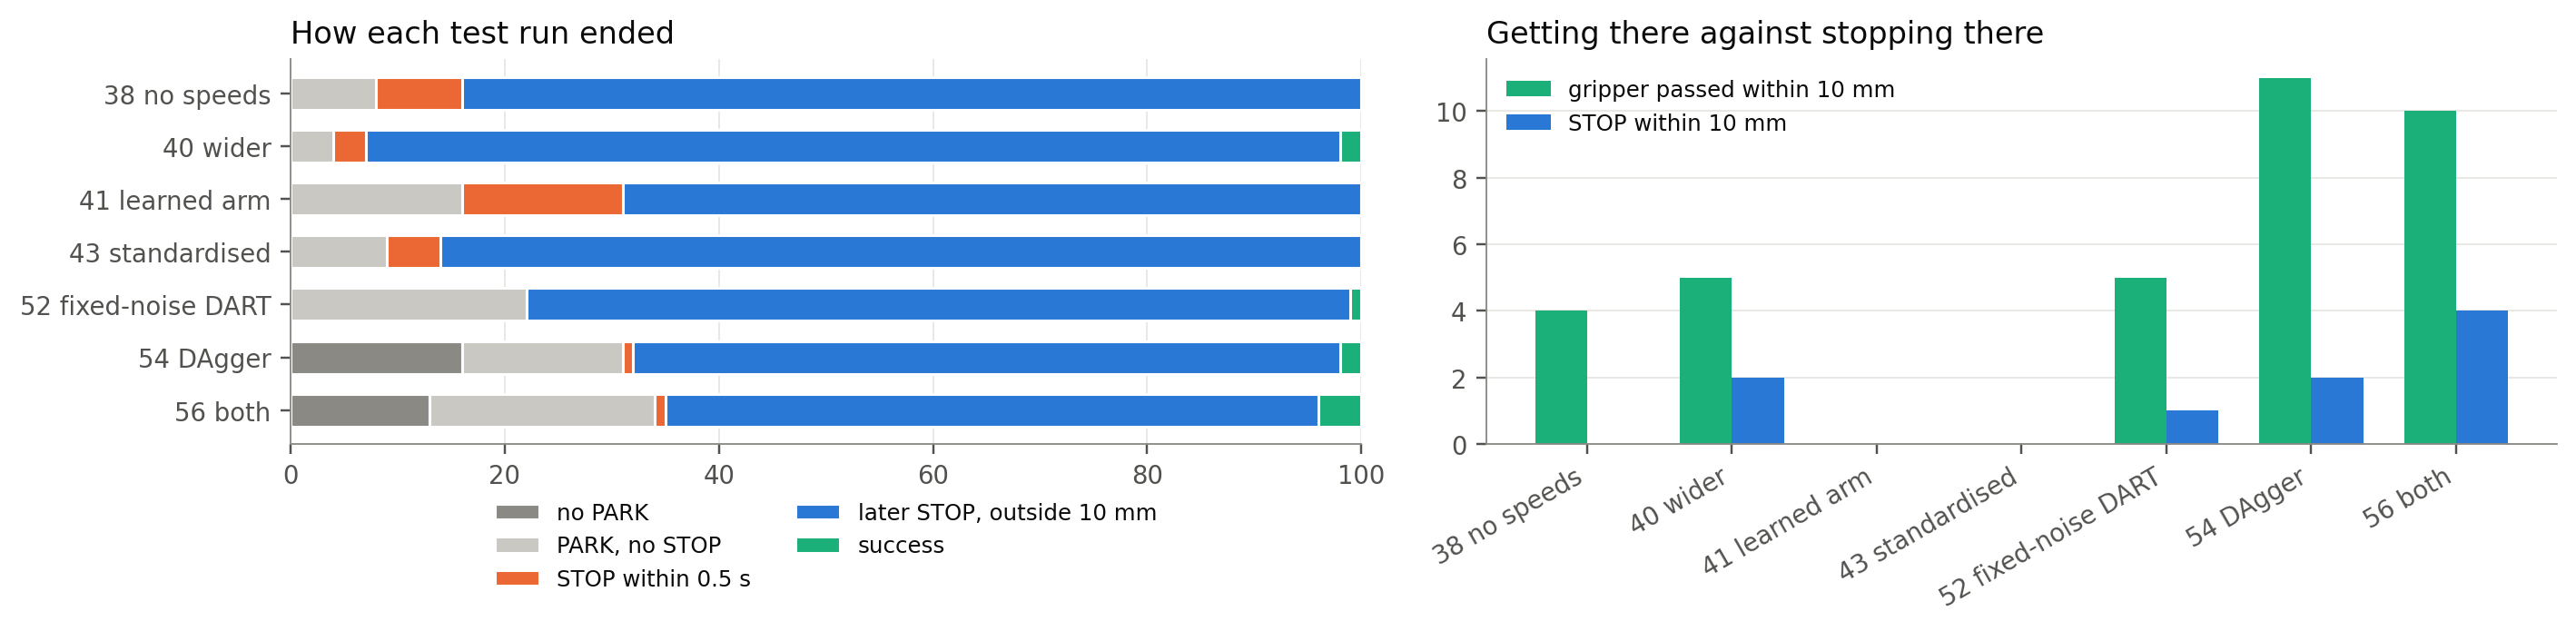

,model,rho_park_error_vs_closest,low,high,rho_heading_vs_closest,rho_height_vs_closest,rho_height_vs_park,closest_if_park_within_5cm,closest_if_park_over_5cm
0,43 standardised,0.07,-0.12,0.27,-0.12,-0.20,0.21,74.89,75.33
1,52 fixed-noise DART,-0.02,-0.21,0.18,0.02,-0.36,0.25,39.77,47.61
2,54 DAgger,0.23,0.04,0.41,0.36,-0.21,0.29,26.20,29.04
3,56 both,-0.10,-0.32,0.14,0.27,-0.37,0.38,43.04,27.35


,band,n,PARK,STOP,success,park_cm,closest_mm,at_stop_mm
0,target_range_m 1 to 1.33,39,34,25,1,4.9,29.8,48.3
1,target_range_m 1.33 to 1.66,30,25,22,0,4.0,19.3,27.4
2,target_range_m 1.66 to 2.01,31,25,22,1,4.1,29.8,36.8
3,target_height_m 0 to 0.5,34,32,26,2,3.9,31.1,47.5
4,target_height_m 0.5 to 1.1,56,42,34,0,4.1,23.8,32.0
5,target_height_m 1.1 to 1.3,10,10,9,0,16.2,28.7,35.4
6,bearing -180 to -90,20,20,18,0,3.4,29.8,48.7
7,bearing -90 to -30,27,27,26,1,5.1,17.5,30.8
8,bearing -30 to 30,12,12,10,0,3.5,19.8,20.3
9,bearing 30 to 90,13,11,11,1,4.1,27.4,47.3


,model,val_PARK,test_PARK,val_success,test_success,val_closest,test_closest,val_at_stop,test_at_stop
0,41 learned arm,100,100,0,0,211.0,184.5,363.3,272.7
1,43 clean,100,100,0,0,92.0,75.1,183.0,168.8
2,52 fixed DART,100,100,2,1,54.3,45.0,81.4,60.9
3,54 DAgger,89,84,4,2,25.3,27.3,35.6,37.0
4,56 both,93,87,1,4,28.6,30.0,27.8,34.5


In [24]:
F = MAC['failure_breakdown']; L = ['no_speed', 'wider_arm', 'baseline', 'basics_standard', 'dart', 'dagger', 'dart_dagger']; parts = [('no_park', 'no PARK', MUTED), ('park_no_stop', 'PARK, no STOP', '#c9c8c3'), ('stop_within_500ms', 'STOP within 0.5 s', ORANGE), ('stop_later_outside', 'later STOP, outside 10 mm', BLUE), ('success', 'success', AQUA)]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.3)); y = np.arange(len(L))[::-1]; left = np.zeros(len(L))
for k, lab, col in parts:
    v = np.array([F[m_][k] + (F[m_]['stop_at_park_within_50ms'] if k == 'stop_within_500ms' else 0) for m_ in L], float); ax[0].barh(y, v, left=left, color=col, label=lab, height=.62, edgecolor='white', lw=1); left += v
ax[0].set_yticks(y); ax[0].set_yticklabels([NAMES[m_] for m_ in L]); ax[0].set_xlim(0, 100); ax[0].set_title('How each test run ended'); ax[0].legend(fontsize=8, ncol=2, loc='upper center', bbox_to_anchor=(.5, -.1)); ax[0].grid(axis='y', visible=False)
w = .36; x = np.arange(len(L)); ax[1].bar(x - w / 2, [F[m_]['got_within_10mm'] for m_ in L], w, color=AQUA, label='gripper passed within 10 mm'); ax[1].bar(x + w / 2, [F[m_]['success'] for m_ in L], w, color=BLUE, label='STOP within 10 mm'); ax[1].set_xticks(x); ax[1].set_xticklabels([NAMES[m_] for m_ in L], rotation=30, ha='right'); ax[1].set_title('Getting there against stopping there'); ax[1].legend(fontsize=8); ax[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
C = MAC['chain']; display(pd.DataFrame([dict(model=NAMES[m_], rho_park_error_vs_closest=C[m_]['park_error_vs_closest'][0], low=C[m_]['park_error_vs_closest'][1], high=C[m_]['park_error_vs_closest'][2], rho_heading_vs_closest=C[m_]['heading_vs_closest'][0], rho_height_vs_closest=C[m_]['height_vs_closest'][0], rho_height_vs_park=C[m_]['height_vs_park_error'][0], closest_if_park_within_5cm=C[m_]['closest_if_park_error_5cm_or_less'][0], closest_if_park_over_5cm=C[m_]['closest_if_park_error_over_5cm'][0]) for m_ in ('basics_standard', 'dart', 'dagger', 'dart_dagger')]).round(2))
B = MAC['bands']['dagger']; display(pd.DataFrame([dict(band=k, n=v['n'], PARK=v['parked'], STOP=v['stopped'], success=v['success'], park_cm=v['park_error_cm'][0], closest_mm=v['closest_mm'][0], at_stop_mm=v['at_stop_mm'][0]) for k, v in B.items() if v['n']]).round(1))
V = MAC['val_vs_test']; display(pd.DataFrame([dict(model=SHORT[k], val_PARK=V[k]['val']['parked'], test_PARK=V[k]['test']['parked'], val_success=V[k]['val']['success'], test_success=V[k]['test']['success'], val_closest=V[k]['val']['closest_mm'][0], test_closest=V[k]['test']['closest_mm'][0], val_at_stop=V[k]['val']['at_stop_mm'][0], test_at_stop=V[k]['test']['at_stop_mm'][0]) for k in MODELS]).round(1))

**Reading.** Most runs now end with a STOP outside 10 mm, rather than a missing event. The gripper comes within 10 mm at any time on 11 DAgger runs and 10 combined runs, and STOP lands inside on 2 and 4. Those counts include the 0.5 s after STOP, and Section 3.26 separates them. For the clean model, parking accuracy says nothing about the reach (ρ = 0.07 [-0.12, 0.27]). For DAgger it starts to (ρ = 0.23 [0.04, 0.41]), and heading more so (ρ = 0.36 [0.15, 0.55]). Validation and test agree on the DAgger model, with closest 25 mm and 27 mm.

## 3.20 Robustness: effects added in turn (Lab 3, Lecture 4.2)

Lab 3 asks about damping and delay. Each row adds one simulator effect to a frozen network, with no retraining. The lower rows apply all effects at once to each trained model.

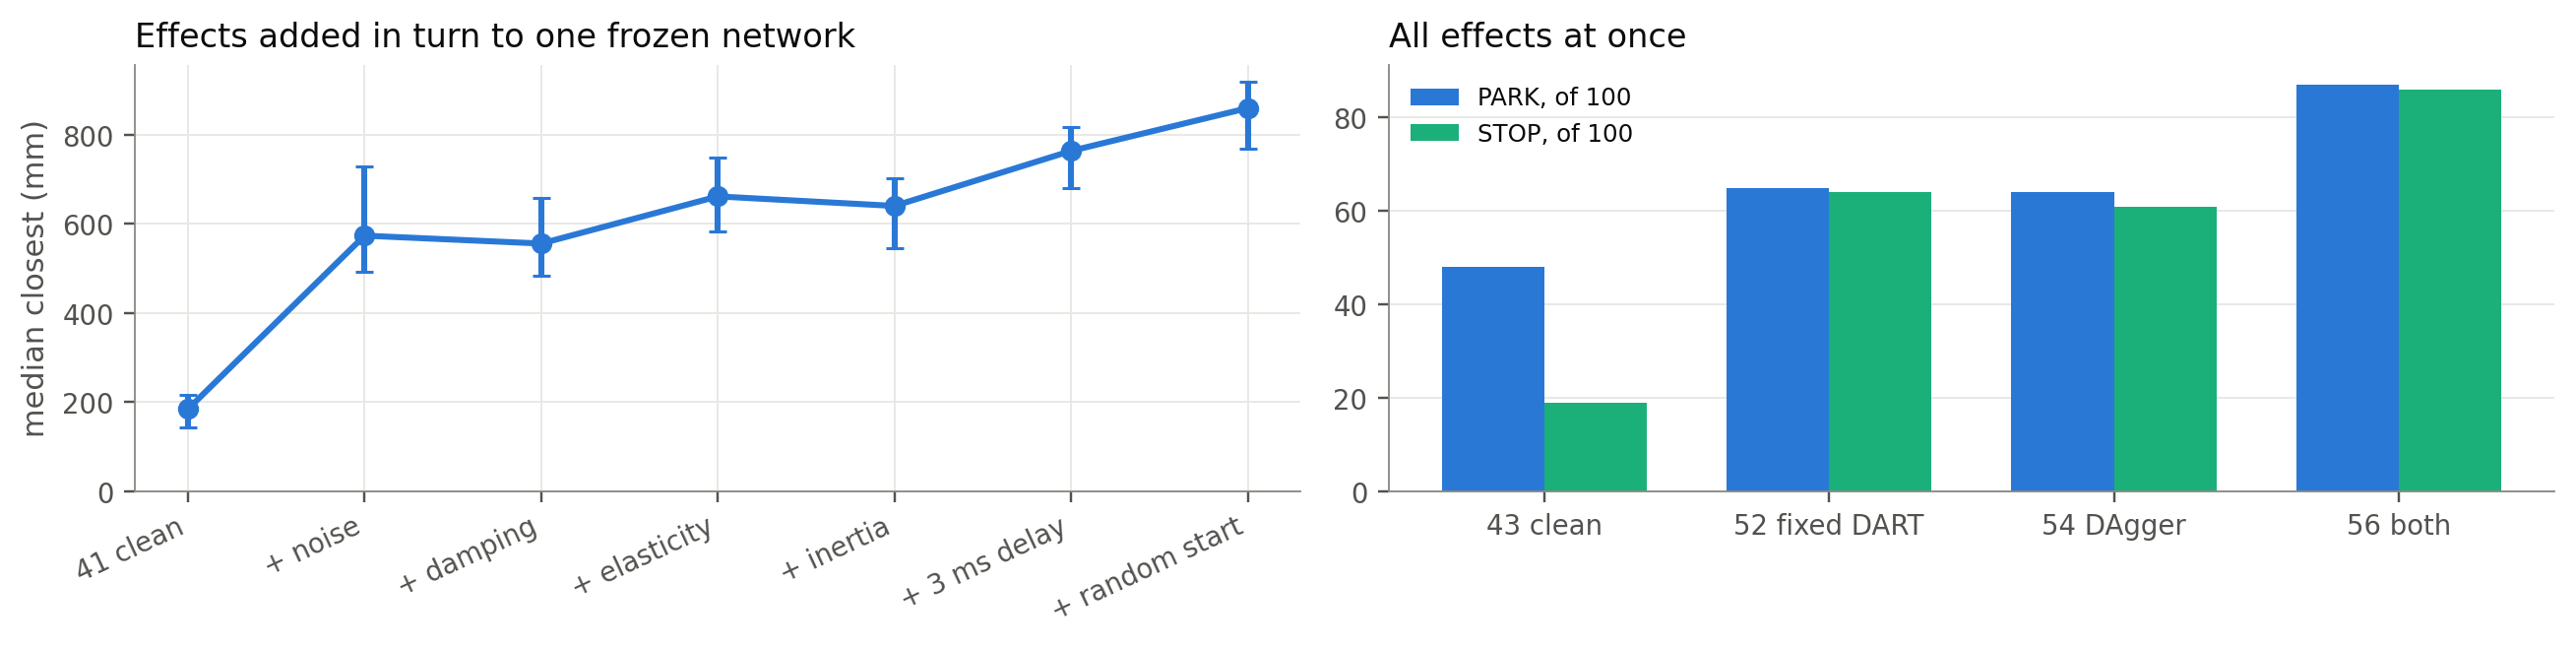

,condition,iteration,PARK,STOP,park_error_cm,closest_mm,closest_low,closest_high,at_stop_mm
0,41 clean,41,100,84,5.5,184.5,143.9,216.2,272.7
1,+ noise,42,99,91,6.2,573.9,493.8,728.6,755.0
2,+ damping,44,100,88,6.3,556.2,483.6,657.8,707.5
3,+ elasticity,45,99,93,6.0,662.0,582.4,748.6,790.5
4,+ inertia,46,100,94,7.2,640.6,546.4,703.1,779.3
5,+ 3 ms delay,47,91,91,7.2,764.1,680.0,817.6,825.9
6,+ random start,48,89,89,7.8,860.1,768.0,919.0,899.3
7,43 clean,51,48,19,34.0,386.7,261.1,635.8,1143.1
8,52 fixed DART,53,65,64,19.1,488.6,364.8,574.8,655.6
9,54 DAgger,55,64,61,19.6,279.6,225.5,393.1,495.6


In [25]:
S = CL['summary']; steps = [('baseline', '41 clean'), ('encoder_noise', '+ noise'), ('damping', '+ damping'), ('elasticity', '+ elasticity'), ('inertia', '+ inertia'), ('delay', '+ 3 ms delay'), ('random_start_fixed', '+ random start')]; stack = [('standard_stack', '43 clean'), ('dart_stack', '52 fixed DART'), ('dagger_stack', '54 DAgger'), ('dart_dagger_stack', '56 both')]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.1)); x = np.arange(len(steps)); v = [S[k]['closest_mm'] for k, _ in steps]
ax[0].errorbar(x, [q[0] for q in v], yerr=[[q[0] - q[1] for q in v], [q[2] - q[0] for q in v]], color=BLUE, marker='o', capsize=3); ax[0].set_xticks(x); ax[0].set_xticklabels([l for _, l in steps], rotation=25, ha='right'); ax[0].set_ylim(0, None); ax[0].set_ylabel('median closest (mm)'); ax[0].set_title('Effects added in turn to one frozen network')
x = np.arange(4); w = .36; ax[1].bar(x - w / 2, [S[k]['parked'] for k, _ in stack], w, color=BLUE, label='PARK, of 100'); ax[1].bar(x + w / 2, [S[k]['stopped'] for k, _ in stack], w, color=AQUA, label='STOP, of 100'); ax[1].set_xticks(x); ax[1].set_xticklabels([l for _, l in stack]); ax[1].set_title('All effects at once'); ax[1].legend(fontsize=8); ax[1].grid(axis='x', visible=False); plt.tight_layout(); plt.show()
display(pd.DataFrame([dict(condition=l, iteration=S[k]['iteration'], PARK=S[k]['parked'], STOP=S[k]['stopped'], park_error_cm=S[k]['park_error_cm'][0], closest_mm=S[k]['closest_mm'][0], closest_low=S[k]['closest_mm'][1], closest_high=S[k]['closest_mm'][2], at_stop_mm=S[k]['at_stop_mm'][0]) for k, l in steps + stack]).round(1))

**Reading.** Noise gives the largest first increase in this ordering: closest distance goes from 184 to 574 mm. That does not show motor effects matter less than sensor noise. The order is fixed, and later effects may interact with, or be hidden by, the damage already there, so each step only measures its increment after those before it. The roadmap expected no detectable change from encoder noise, and it was wrong. With all effects at once, the combined model parks on 87 and stops on 86, against 48 and 19 for the clean one, at 322 mm against 1143 mm. Those are single-seed descriptive results. They do not make the recovery models robust in general: no run in the stack is reliably precise.

## 3.21 Clean and disturbed together, every run counted

The evidence on the four main models in one table: completion, accuracy and robustness. Medians marked "all 100" count a run with no event as a failure ranked last, so they keep the denominator at 100. If more than half the runs have no event, that median does not exist and shows as "none". "Clean" means no added disturbance. "Disturbed" is encoder noise, damping, elasticity, inertia, 3 ms delay and random starts together.

PARK /100  STOP /100  success /100  \
condition model                                                
clean     43 clean model        100         91             0   
          52 fixed DART         100         78             1   
          54 DAgger              84         69             2   
          56 both                87         66             4   
disturbed 43 clean model         48         19             0   
          52 fixed DART          65         64             0   
          54 DAgger              64         61             0   
          56 both                87         86             0   

                         closest mm, all 100 at STOP mm, all 100  \
condition model                                                    
clean     43 clean model                  75                 181   
          52 fixed DART                   45                 180   
          54 DAgger                       31                  52   
          56 both                         34                  53   
disturbed 43 clean model                none                none   
          52 fixed DART                  731                1015   
          54 DAgger                      596                 938   
          56 both                        257                 364   

                         at STOP mm, runs with STOP  
condition model                                      
clean     43 clean model                        169  
          52 fixed DART                          61  
          54 DAgger                              37  
          56 both                                34  
disturbed 43 clean model                       1143  
          52 fixed DART                         656  
          54 DAgger                             496  
          56 both                               322

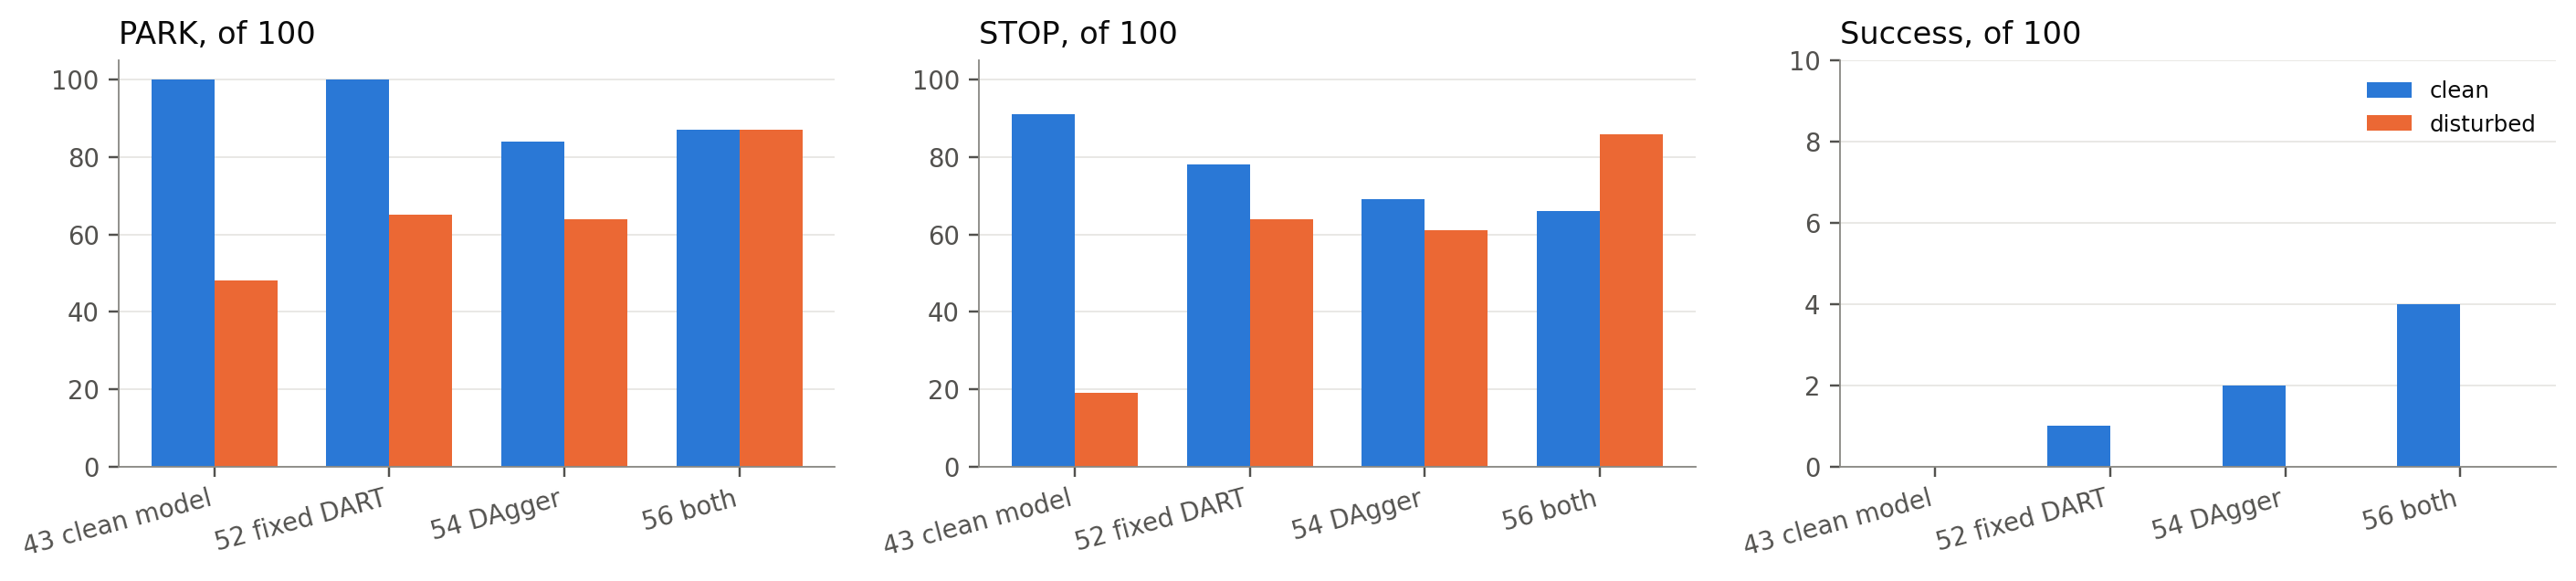

In [26]:
M4 = [('basics_standard', 'standard_stack', '43 clean model'), ('dart', 'dart_stack', '52 fixed DART'), ('dagger', 'dagger_stack', '54 DAgger'), ('dart_dagger', 'dart_dagger_stack', '56 both')]
def med_all(v, n=100):
    v = np.sort(np.asarray(v, float)); v = v[np.isfinite(v)]
    if len(v) < n / 2: return None
    full = np.r_[v, np.full(n - len(v), np.inf)]; return float(np.median(full))
fmt = lambda x: 'none' if x is None or not np.isfinite(x) else f'{x:.0f}'
def row(k, cond, lab):
    t = per_target(k); s = t.at_stop_mm.where(t.stopped); return {'model': lab, 'condition': cond, 'PARK /100': int(t.parked.sum()), 'STOP /100': int(t.stopped.sum()), 'success /100': int(t.success.sum()), 'closest mm, all 100': fmt(med_all(t.closest_mm.where(t.parked))), 'at STOP mm, all 100': fmt(med_all(s)), 'at STOP mm, runs with STOP': fmt(np.nanmedian(s))}
T = pd.DataFrame([row(a, 'clean', l) for a, _, l in M4] + [row(b, 'disturbed', l) for _, b, l in M4]); display(T.set_index(['condition', 'model']))
fig, ax = plt.subplots(1, 3, figsize=(13, 3)); x = np.arange(4); w = .36; D = T[T.condition == 'clean']; S_ = T[T.condition == 'disturbed']; names = [l for _, _, l in M4]
for a, col, title in ((ax[0], 'PARK /100', 'PARK, of 100'), (ax[1], 'STOP /100', 'STOP, of 100'), (ax[2], 'success /100', 'Success, of 100')):
    a.bar(x - w / 2, D[col], w, color=BLUE, label='clean'); a.bar(x + w / 2, S_[col], w, color=ORANGE, label='disturbed'); a.set_xticks(x); a.set_xticklabels(names, rotation=15, ha='right'); a.set_title(title); a.grid(axis='x', visible=False); a.set_ylim(0, 105 if col != 'success /100' else 10)
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** Better reaching comes with worse completion. From the clean model to DAgger, median distance at STOP falls from 169 to 37 mm, while PARK falls from 100 to 84 and STOP from 91 to 69. Keep the 100-run columns first. The conditional medians exclude failures, so read them second.

## 3.22 Paired changes with intervals

The same comparisons as Section 3.18, now with the size of the change. Each is a median of paired differences on targets where both models have the event, with a 95% bootstrap interval over targets. Negative means closer to the target. This covers target uncertainty for these two trained models and says nothing about training seeds (Section 3.24). McNemar counts below use all 100 targets, so they show what the distance comparisons leave out.

,comparison,measure,pairs,median_change,low,high,better,worse
0,37 to 38: remove speeds,park_error_cm,87,-14.2,-18.8,-9.1,76,11
1,37 to 38: remove speeds,closest_mm,87,-221.2,-274.1,-195.8,82,5
2,40 to 41: learn hold,closest_mm,100,103.2,67.4,131.1,14,86
3,41 to 43: standardise,closest_mm,100,-100.0,-129.4,-64.8,87,13
4,43 to 52: fixed DART,closest_mm,100,-27.8,-32.9,-20.3,76,24
5,43 to 52: fixed DART,at_stop_mm,71,-20.7,-72.4,14.2,42,29
6,43 to 54: DAgger,closest_mm,84,-48.1,-61.4,-36.6,75,9
7,43 to 54: DAgger,at_stop_mm,66,-129.9,-175.5,-97.6,65,1
8,54 to 56: add DART,closest_mm,81,0.0,-5.6,6.7,40,41
9,54 to 56: add DART,at_stop_mm,57,-5.2,-10.9,-2.3,37,20


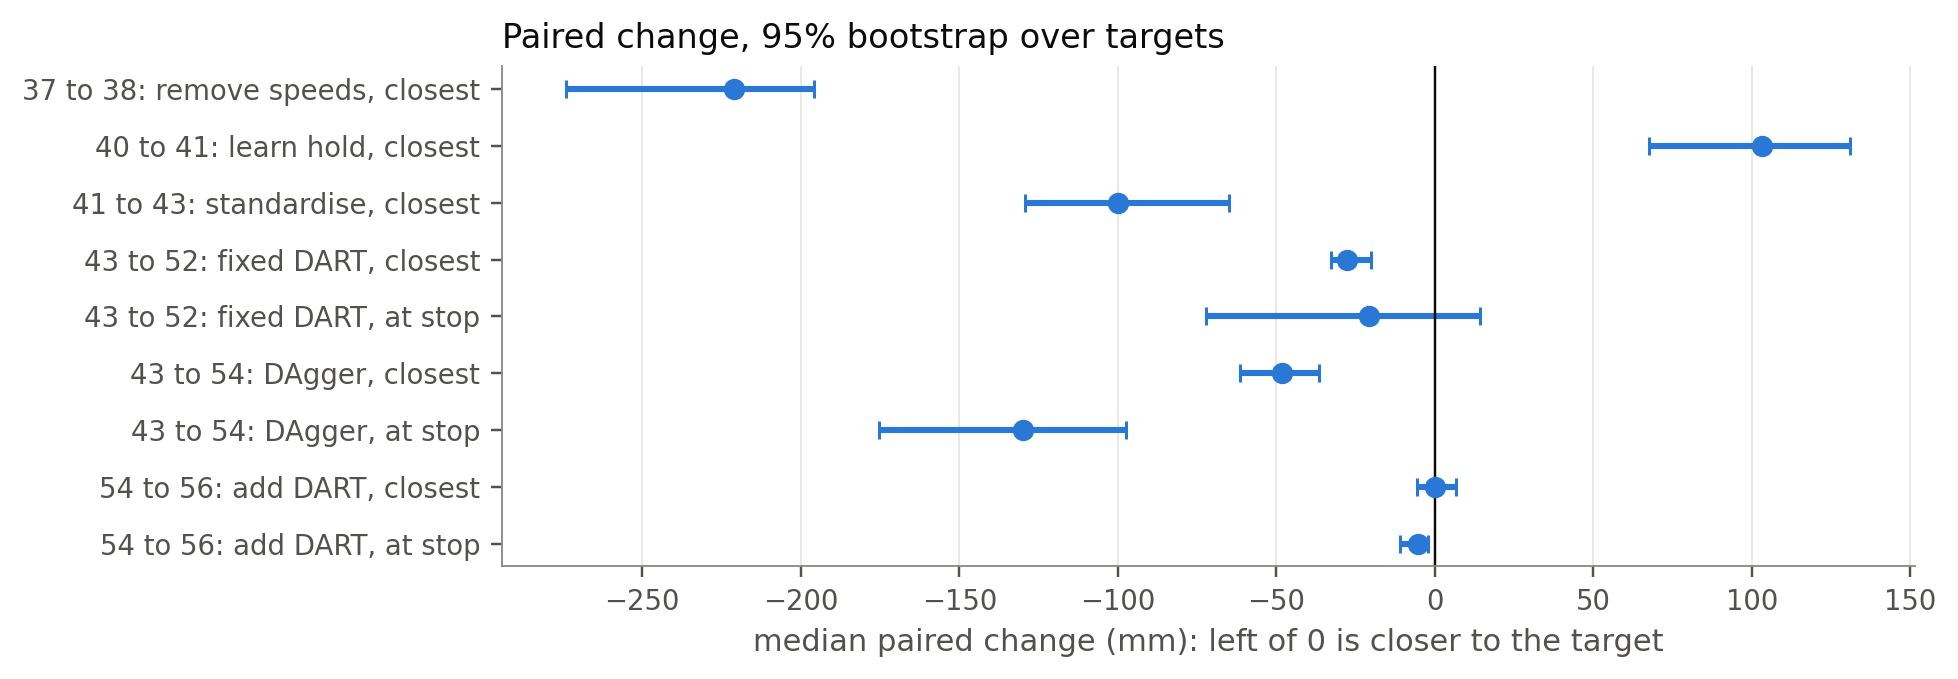

,comparison,event,only_first,only_second,p
0,43 to 54: DAgger,parked,16,0,0.0000
1,43 to 54: DAgger,stopped,25,3,0.0000
2,43 to 54: DAgger,success,0,2,0.5000
3,43 to 52: fixed DART,parked,0,0,1.0000
4,43 to 52: fixed DART,stopped,20,7,0.0192
5,43 to 52: fixed DART,success,0,1,1.0000
6,54 to 56: add DART,parked,3,6,0.5078
7,54 to 56: add DART,stopped,12,9,0.6636
8,54 to 56: add DART,success,2,4,0.6875


In [27]:
def paired(a, b, col, B=5000):
    rng = np.random.default_rng(7); d = (per_target(b)[col] - per_target(a)[col]).dropna().values; s = np.median(d[rng.integers(0, len(d), (B, len(d)))], 1); return dict(pairs=len(d), median_change=np.median(d), low=np.percentile(s, 2.5), high=np.percentile(s, 97.5), better=int((d < 0).sum()), worse=int((d > 0).sum()))
PL = [('37 to 38: remove speeds', 'height', 'no_speed', 'park_error_cm'), ('37 to 38: remove speeds', 'height', 'no_speed', 'closest_mm'), ('40 to 41: learn hold', 'wider_arm', 'baseline', 'closest_mm'), ('41 to 43: standardise', 'baseline', 'basics_standard', 'closest_mm'), ('43 to 52: fixed DART', 'basics_standard', 'dart', 'closest_mm'), ('43 to 52: fixed DART', 'basics_standard', 'dart', 'at_stop_mm'), ('43 to 54: DAgger', 'basics_standard', 'dagger', 'closest_mm'), ('43 to 54: DAgger', 'basics_standard', 'dagger', 'at_stop_mm'), ('54 to 56: add DART', 'dagger', 'dart_dagger', 'closest_mm'), ('54 to 56: add DART', 'dagger', 'dart_dagger', 'at_stop_mm')]
P_ = pd.DataFrame([dict(comparison=l, measure=m_, **paired(a, b, m_)) for l, a, b, m_ in PL]); display(P_.round(1))
fig, ax = plt.subplots(figsize=(9, 3.2)); Q = P_[P_.measure != 'park_error_cm'].reset_index(drop=True); y = np.arange(len(Q))[::-1]; ax.errorbar(Q.median_change, y, xerr=[Q.median_change - Q.low, Q.high - Q.median_change], fmt='o', color=BLUE, capsize=3); ax.axvline(0, color=INK, lw=.8); ax.set_yticks(y); ax.set_yticklabels([f"{a}, {b.replace('_mm', '').replace('_', ' ')}" for a, b in zip(Q.comparison, Q.measure)]); ax.set_xlabel('median paired change (mm): left of 0 is closer to the target'); ax.set_title('Paired change, 95% bootstrap over targets'); ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()
def mcn(a, b, col):
    A, B = per_target(a)[col].astype(bool), per_target(b)[col].astype(bool); oa, ob = int((A & ~B).sum()), int((~A & B).sum()); n = oa + ob; return dict(only_first=oa, only_second=ob, p=min(1., 2 * sum(math.comb(n, i) for i in range(min(oa, ob) + 1)) / 2 ** n) if n else 1.)
display(pd.DataFrame([dict(comparison=l, event=e, **mcn(a, b, e)) for l, a, b in (('43 to 54: DAgger', 'basics_standard', 'dagger'), ('43 to 52: fixed DART', 'basics_standard', 'dart'), ('54 to 56: add DART', 'dagger', 'dart_dagger')) for e in ('parked', 'stopped', 'success')]).round(4))

## 3.23 Training curves of the models tested on the robot

Train (solid) and validation (dashed) loss per epoch for each model's three networks, with the selected checkpoint marked. This complements Section 3.6, which compares settings on separate runs. The DAgger curves are the final round's.

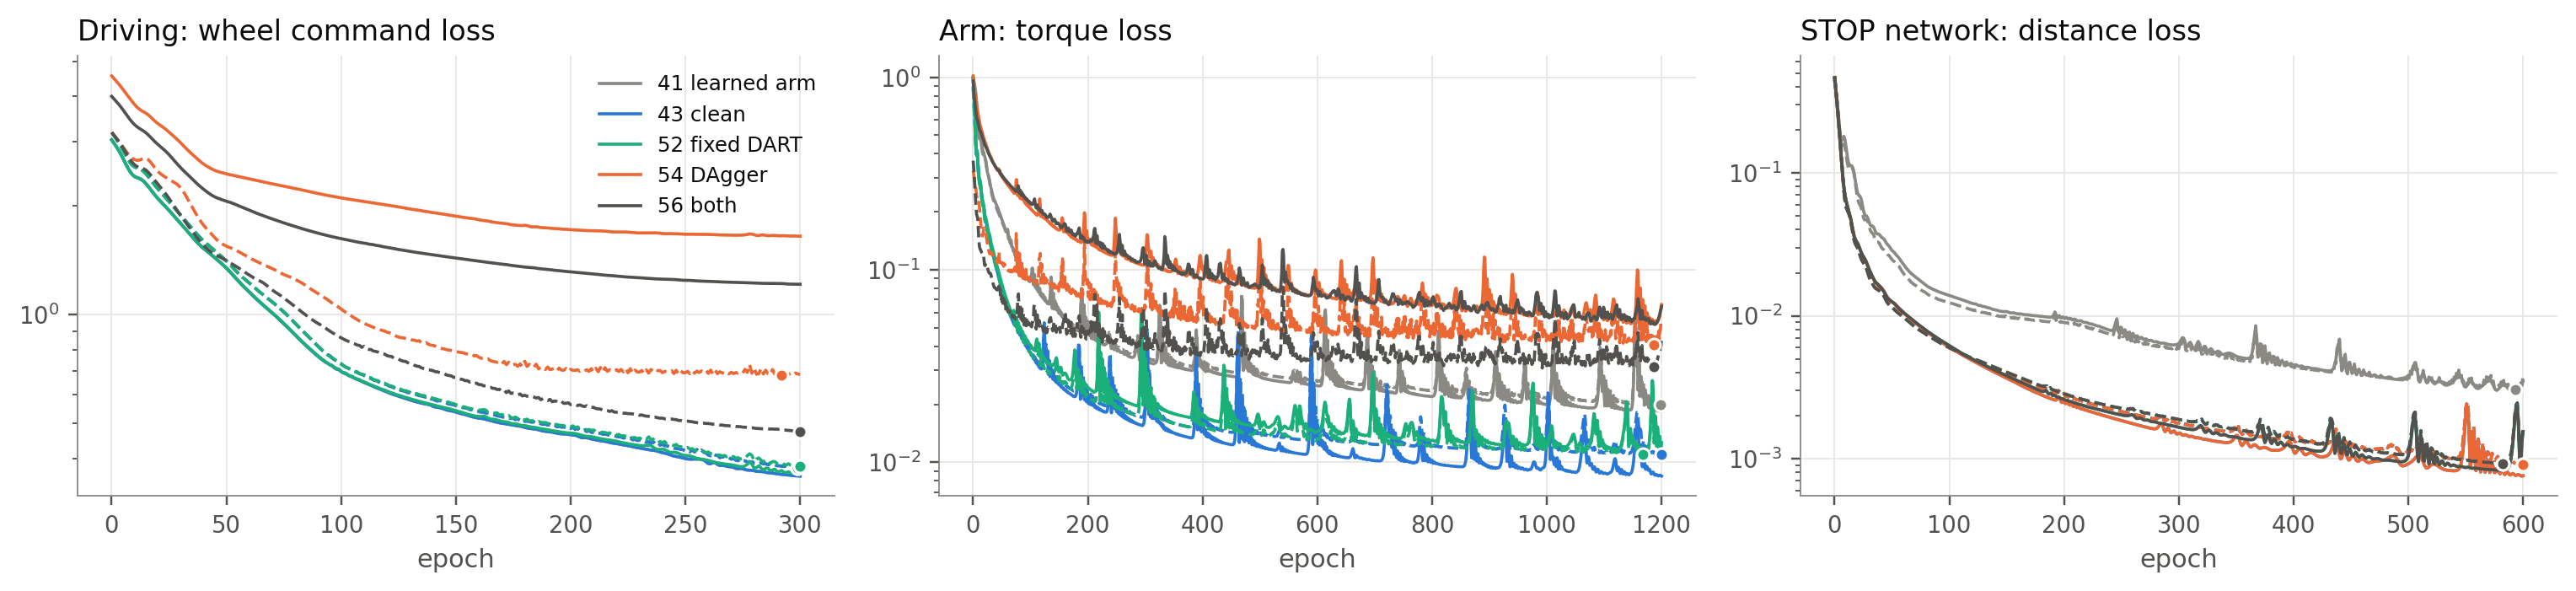

,model,network,selected_epoch,selected_val_loss
0,41 learned arm,driving,299,0.3842
1,41 learned arm,torque,1198,0.0217
2,41 learned arm,stop,593,0.0030
3,43 clean,driving,299,0.3842
4,43 clean,torque,1200,0.0121
5,43 clean,stop,600,0.0009
6,52 fixed DART,driving,300,0.3879
7,52 fixed DART,torque,1168,0.0121
8,52 fixed DART,stop,582,0.0009
9,54 DAgger,driving,292,0.6960


In [28]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
for a, net, title, tr, va in ((ax[0], 'driving', 'Driving: wheel command loss', 'train_command', 'val_command'), (ax[1], 'torque', 'Arm: torque loss', 'train_command', 'val_command'), (ax[2], 'stop', 'STOP network: distance loss', None, None)):
    for m in MODELS:
        f = DATA / f'histories/{m}/{net}_seed7_history.json'
        if not f.exists(): continue
        h = pd.DataFrame(json.load(open(f))); kt = tr or next(k for k in h if k.startswith('train') and 'total' not in k and k != 'train_aux'); kv = va or next(k for k in h if k.startswith('val') and 'total' not in k and k != 'val_aux')
        a.plot(h.epoch, h[kt], color=COL[m], lw=1.2, label=SHORT[m]); a.plot(h.epoch, h[kv], color=COL[m], lw=1.2, ls='--'); e_ = json.load(open(DATA / f'histories/{m}/{net}_seed7_summary.json')).get('selected_epoch')
        if e_ is not None and e_ in set(h.epoch): a.scatter([e_], [h.set_index('epoch').loc[e_, kv]], color=COL[m], s=24, zorder=4, edgecolor='white')
    a.set_yscale('log'); a.set_xlabel('epoch'); a.set_title(title)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
display(pd.DataFrame([dict(model=SHORT[m], network=net, selected_epoch=json.load(open(DATA / f'histories/{m}/{net}_seed7_summary.json')).get('selected_epoch'), selected_val_loss=json.load(open(DATA / f'histories/{m}/{net}_seed7_summary.json')).get('selected_val_loss')) for m in MODELS for net in ('driving', 'torque', 'stop')]).round(4))

**Reading.** Each model's loss is in its own standardised units, so compare shapes across panels and not heights between recovery and clean models. Training and validation stay close on clean data and losses are still falling slowly when training ends. Recovery rows raise training loss above validation because those rows are harder.

## 3.24 Target uncertainty is separate from seed variation

Bootstrapping 100 targets measures uncertainty for one trained model. It does not cover what changes if the same setup is trained again. Iterations 34 to 36 differ only by seed. Their intervals are the thin marks, and the gap between seeds is often larger than any one interval. From iteration 37 onward every result is seed 7, so no later comparison can be checked against seed spread. The roadmap's own rule was that a difference smaller than the seed spread is not a finding.

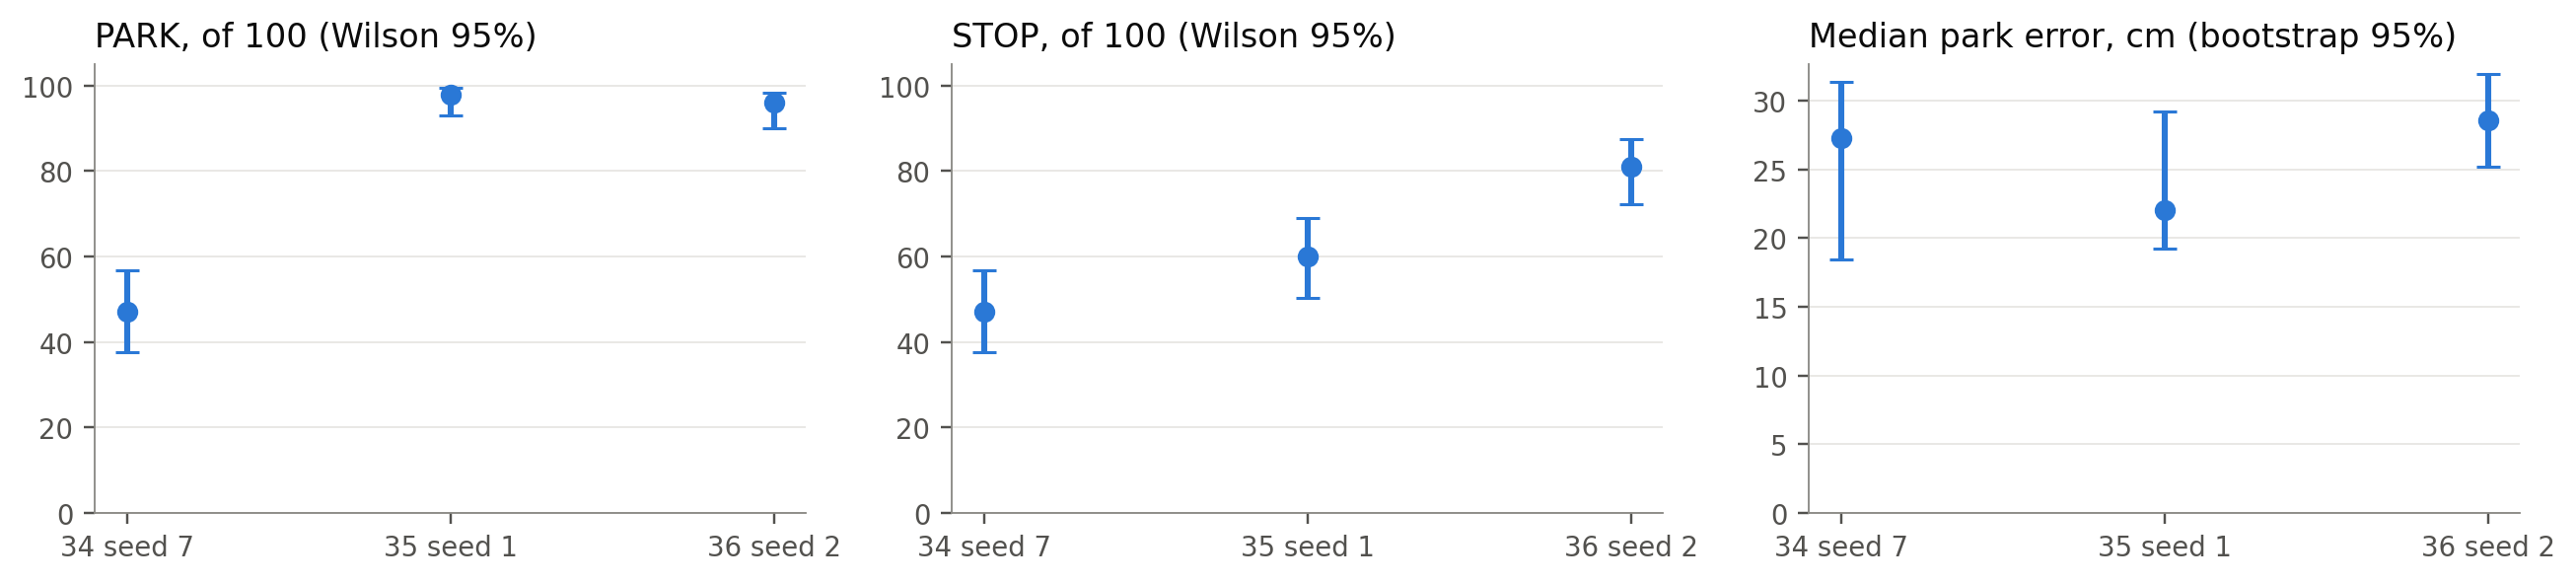

In [29]:
S = CL['summary']; K = [('seed7', '34 seed 7'), ('seed1', '35 seed 1'), ('seed2', '36 seed 2')]; fig, ax = plt.subplots(1, 3, figsize=(12, 2.8)); x = np.arange(3)
for a, f_, ci, title in ((ax[0], 'parked', 'parked_ci', 'PARK, of 100 (Wilson 95%)'), (ax[1], 'stopped', 'stopped_ci', 'STOP, of 100 (Wilson 95%)')):
    v = [S[k][f_] for k, _ in K]; lo = [S[k][ci][0] for k, _ in K]; hi = [S[k][ci][1] for k, _ in K]; a.errorbar(x, v, yerr=[np.array(v) - lo, np.array(hi) - v], fmt='o', color=BLUE, capsize=4); a.set_ylim(0, 105); a.set_title(title)
v = [S[k]['park_error_cm'] for k, _ in K]; ax[2].errorbar(x, [q[0] for q in v], yerr=[[q[0] - q[1] for q in v], [q[2] - q[0] for q in v]], fmt='o', color=BLUE, capsize=4); ax[2].set_ylim(0, None); ax[2].set_title('Median park error, cm (bootstrap 95%)')
for a in ax: a.set_xticks(x); a.set_xticklabels([l for _, l in K]); a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

## 3.25 Model comparison ledger

What differs in each contrast, so unlike experiments are not read as interchangeable. All tests use the same 100 test targets and one machine.

| Contrast | What changed | Training data | Network | Arm before PARK | Seed | Test condition |
|---|---|---|---|---|---|---|
| 34, 35, 36 | Seed only | 100 expert runs | Driving 16 inputs (with speeds), arm 17 inputs, 64 units | Supplied PD and gravity controller | 7, 1, 2 | Clean |
| 34 to 37 | Target height added to driving | Same | Driving 17 inputs | Same | 7 | Clean |
| 37 to 38 | Six wheel speed inputs removed | Same | Driving 11 inputs | Same | 7 | Clean |
| 38 to 39 | 1,200 torque epochs | Same | Arm 64 units | Same | 7 | Clean |
| 39 to 40 | Wider arm | Same | Arm 128 units | Same | 7 | Clean |
| 40 to 41 | Network holds the arm from reset | Arm rows from reset | Arm 18 inputs (PARK flag added), physical scales | Learned | 7 | Clean |
| 41 to 43 | Arm inputs standardised | Same as 41 | Same shape | Learned | 7 | Clean |
| 41 to 42, 44 to 48 | One effect added at each step | No retraining | Frozen 41 | Learned | 7 | Cumulative disturbances |
| 43 to 52 | Fixed noise recovery rows | + 199 noisy expert runs | Same shape, retrained | Learned | 7 | Clean |
| 43 to 54 | DAgger rows (commands only) | + 3 rounds of 100 network runs | Same shape, retrained | Learned | 7 | Clean |
| 52 to 56 | DAgger on top of fixed noise | + both | Same shape, retrained | Learned | 7 | Clean |
| 51, 53, 55, 57 | Same four models | No retraining | Frozen 43, 52, 54, 56 | Learned | 7 | All disturbances, random starts |

Note that the ladder uses iteration 41 and the all-effects rows use iteration 43 and later, so the ladder cannot say how standardisation changes noise sensitivity.

## 3.26 On the way to the target: arrive, pass through, or stay?

Distance alone mixes three failures. This uses the saved 30 Hz records of each test run, from PARK to STOP. No run is excluded: every one of the 100 runs is in exactly one category.

- **No PARK**: the arm phase never started.
- **Never within 10 mm**: failure to arrive, the gripper was never inside the tolerance.
- **Within 10 mm only after STOP**: STOP fired early, and the arm carried on into the tolerance during the following 0.5 s.
- **Passed through**: inside for under 0.1 s before STOP.
- **Stayed**: inside for 0.1 s or more before STOP, with STOP firing elsewhere or not at all.
- **Success**: STOP fired inside 10 mm.

"Perfect stop" is what a perfect stopping rule could achieve on these same paths, stopping at the best instant before the network's own STOP. Records at 30 Hz can miss a pass shorter than 33 ms. The largest gap between the 30 Hz and 1 kHz closest distance is a few mm.

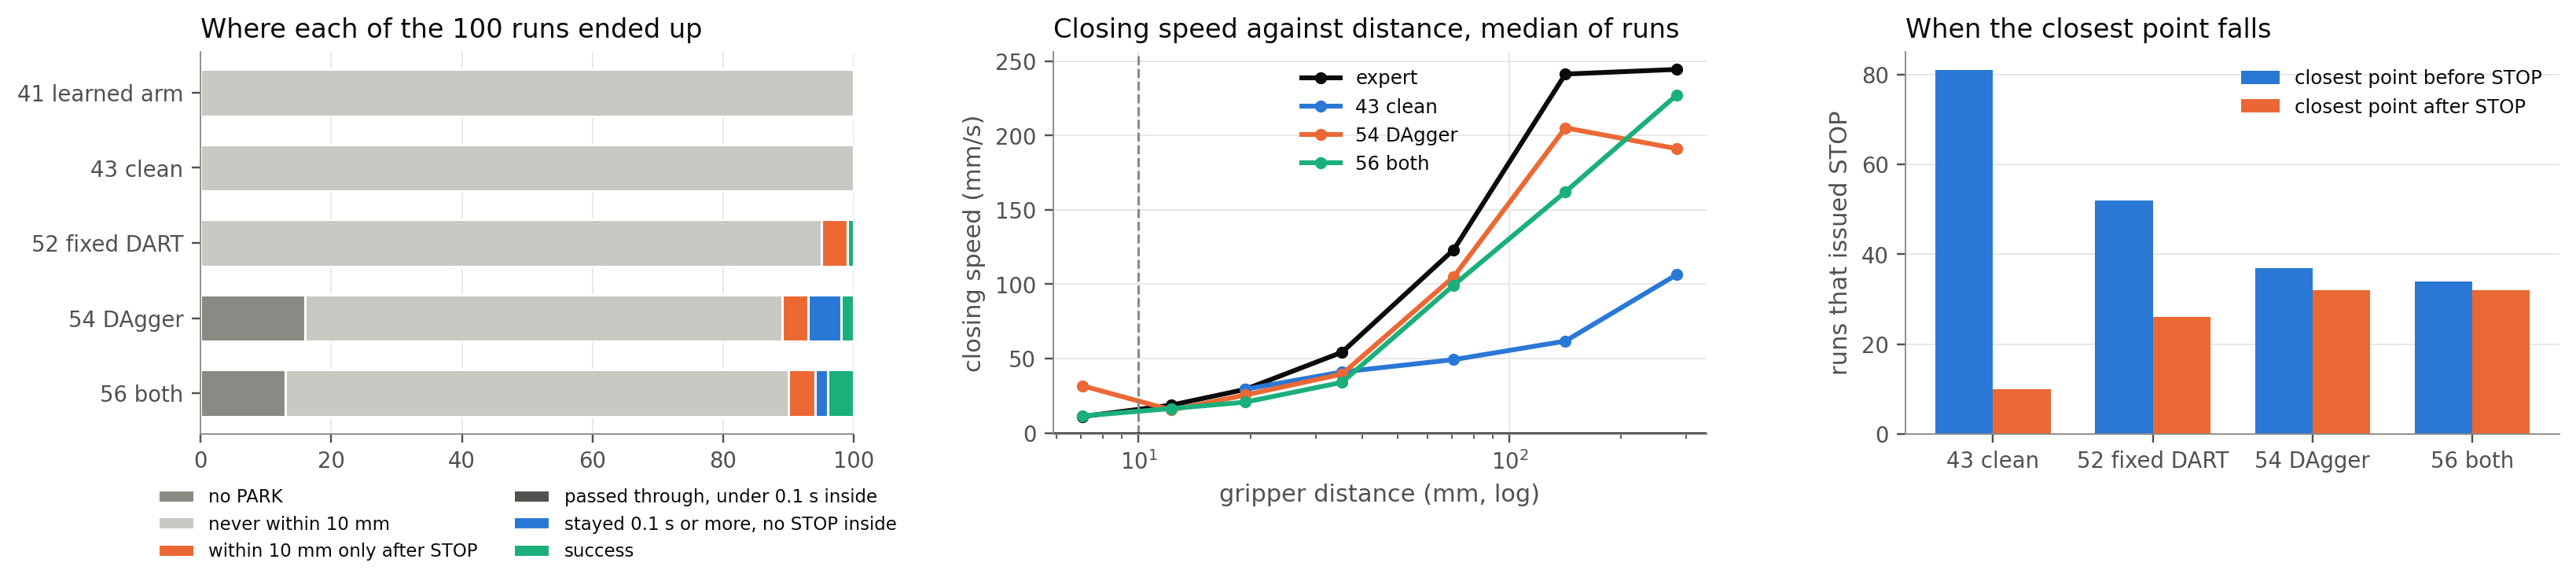

,model,no_PARK,never_within_10mm,only_after_STOP,passed_through,stayed,success,perfect_stop,within_25mm,within_50mm,STOP_minus_best_mm,time_inside_s,closing_at_25mm
0,41 learned arm,0,100,0,0,0,0,0,0,2,18.60,NaN,NaN
1,43 clean,0,100,0,0,0,0,0,6,22,71.86,NaN,51.69
2,52 fixed DART,0,95,4,0,0,1,1,13,54,5.77,0.46,22.95
3,54 DAgger,16,73,4,0,5,2,7,31,64,0.65,0.20,53.76
4,56 both,13,77,4,0,2,4,6,34,65,1.33,0.23,34.52


In [30]:
AP = J('approach.json'); L = ['baseline', 'basics_standard', 'dart', 'dagger', 'dart_dagger']; parts = [('no PARK', MUTED), ('never within 10 mm', '#c9c8c3'), ('within 10 mm only after STOP', ORANGE), ('passed through, under 0.1 s inside', GREY), ('stayed 0.1 s or more, no STOP inside', BLUE), ('success', AQUA)]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5)); y = np.arange(5)[::-1]; left = np.zeros(5)
for k, col in parts:
    v = np.array([AP[m]['categories'].get(k, 0) for m in L], float); ax[0].barh(y, v, left=left, color=col, label=k, height=.62, edgecolor='white', lw=1); left += v
ax[0].set_yticks(y); ax[0].set_yticklabels([SHORT[m] for m in L]); ax[0].set_xlim(0, 100); ax[0].set_title('Where each of the 100 runs ended up'); ax[0].legend(fontsize=7.5, ncol=2, loc='upper center', bbox_to_anchor=(.5, -.1)); ax[0].grid(axis='y', visible=False)
for name, col, lab in (('expert', INK, 'expert'), ('basics_standard', BLUE, '43 clean'), ('dagger', ORANGE, '54 DAgger'), ('dart_dagger', AQUA, '56 both')):
    b = [q for q in AP[name]['bins'] if q['closing_mm_s'] and q['runs'] >= 3]; xs = [np.sqrt(q['lo'] * q['hi']) for q in b]; ax[1].plot(xs, [q['closing_mm_s'][1] for q in b], color=col, marker='o', ms=4, label=lab)
ax[1].axvline(10, color=MUTED, ls='--', lw=1); ax[1].axhline(0, color=INK, lw=.7); ax[1].set_xscale('log'); ax[1].set_xlabel('gripper distance (mm, log)'); ax[1].set_ylabel('closing speed (mm/s)'); ax[1].set_title('Closing speed against distance, median of runs'); ax[1].legend(fontsize=8)
w = .36; x = np.arange(4); M_ = L[1:]; ax[2].bar(x - w / 2, [AP[m]['closest_before_stop'] for m in M_], w, color=BLUE, label='closest point before STOP'); ax[2].bar(x + w / 2, [AP[m]['closest_after_stop'] for m in M_], w, color=ORANGE, label='closest point after STOP'); ax[2].set_xticks(x); ax[2].set_xticklabels([SHORT[m] for m in M_]); ax[2].set_ylabel('runs that issued STOP'); ax[2].set_title('When the closest point falls'); ax[2].legend(fontsize=8); ax[2].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
display(pd.DataFrame([dict(model=SHORT[m], no_PARK=AP[m]['categories'].get('no PARK', 0), never_within_10mm=AP[m]['categories'].get('never within 10 mm', 0), only_after_STOP=AP[m]['categories'].get('within 10 mm only after STOP', 0), passed_through=AP[m]['categories'].get('passed through, under 0.1 s inside', 0), stayed=AP[m]['categories'].get('stayed 0.1 s or more, no STOP inside', 0), success=AP[m]['categories'].get('success', 0), perfect_stop=AP[m]['oracle_stop_successes'], within_25mm=AP[m]['within_25_before_stop'], within_50mm=AP[m]['within_50_before_stop'], STOP_minus_best_mm=AP[m]['stop_gap_over_best_mm'][1], time_inside_s=(AP[m]['time_inside_when_any_s'] or [0, np.nan])[1], closing_at_25mm=(AP[m]['closing_at_25mm_mm_s'] or [0, np.nan])[1]) for m in L]).round(2))

The next table takes only the runs that never came within 10 mm and asks what the gripper was doing when the run's approach ended, in the last 0.27 s before STOP or the deadline. Still closing means at over 10 mm/s towards the target, moving away means over 10 mm/s the other way, and nearly still is anything between.

In [31]:
def final_state(m):
    x = AP[m]; rows = [r for r in x['per_run'] if r['category'] != 'no PARK']; out = []
    for r, (d, v) in zip(rows, x['traces']):
        if r['category'] != 'never within 10 mm': continue
        v = np.array([np.nan if q is None else q for q in v], float); out.append(dict(speed=np.nanmedian(v[-min(len(v), 4):]), dist=d[-1], stop=r['stop_issued']))
    t = pd.DataFrame(out); return dict(model=SHORT[m], never_within_10mm=len(t), of_which_issued_STOP=int(t.stop.sum()), still_closing=int((t.speed >= 10).sum()), nearly_still=int((t.speed.abs() < 10).sum()), moving_away=int((t.speed <= -10).sum()), median_distance_mm=t.dist.median(), median_closing_mm_s=t.speed.median())
display(pd.DataFrame([final_state(m) for m in L]).round(1))

,model,never_within_10mm,of_which_issued_STOP,still_closing,nearly_still,moving_away,median_distance_mm,median_closing_mm_s
0,41 learned arm,100,84,39,8,53,345.0,-28.6
1,43 clean,100,91,14,8,78,159.0,-102.7
2,52 fixed DART,95,73,18,28,49,62.1,-12.6
3,54 DAgger,73,58,43,14,16,49.0,20.4
4,56 both,77,56,32,32,13,43.9,3.8


**Reading.** Most runs never reach the tolerance. 73 DAgger runs and 77 combined runs are never within 10 mm, and 16 and 13 more never park. Stopping at the best instant before the network's own STOP would give 7 and 6 successes, against the actual 2 and 4.

That count is a lower bound for a better STOP, because STOP also ends the path. Of the 73 DAgger runs that never arrive, 43 were still closing at over 10 mm/s when STOP or the deadline came, 14 were nearly still and 16 were moving away, with a median distance of 49 mm. For the combined model the counts are 32, 32 and 13. For the clean model 78 of 100 were moving away, which is a different failure. So "failure to arrive" mixes an early STOP, a stalled reach and a reach that turns away, and the saved runs cannot say how many of the still-closing runs would have arrived, since each run ends 0.5 s after STOP. Running the DAgger model with STOP ignored would settle it, and needs new simulation.

Nothing passes straight through: every pre-STOP visit inside 10 mm lasts at least 0.1 s, a median 0.20 s for DAgger. Across runs that issue STOP the closest point falls about evenly either side of it (37 before, 32 after, for DAgger), so STOP is neither consistently early nor consistently late. Closing speed at each distance is close to the expert's for both recovery models, so at a given distance they approach about as fast as the expert does.

## 3.27 After STOP

The run continues for 0.5 s after STOP with the networks still in control. How far does the gripper move? This uses the saved distance at STOP and at the end of the run. Every point is a run that issued STOP.

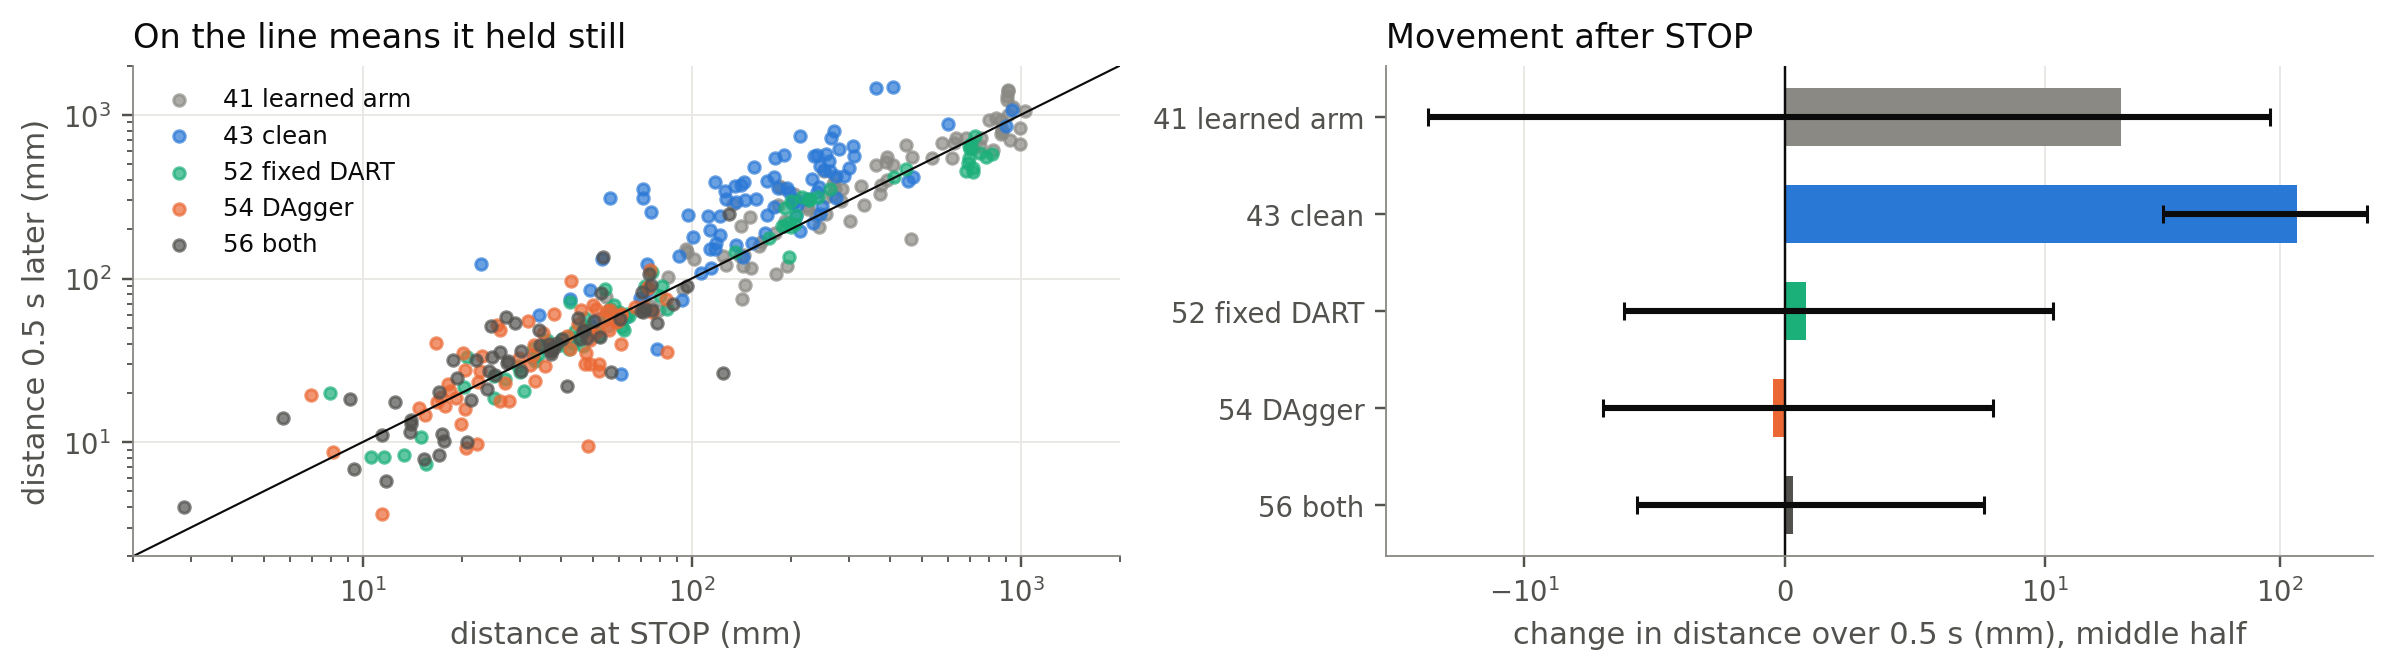

,model,runs,at_STOP_mm,after_half_second_mm,median_change_mm,p25,p75,moved_away_over_10mm,moved_closer_over_10mm
0,41 learned arm,84,272.7,340.4,21.0,-25.8,90.5,47,24
1,43 clean,91,168.8,306.2,119.0,31.8,236.5,74,8
2,52 fixed DART,78,60.9,63.5,0.8,-6.2,10.7,20,16
3,54 DAgger,69,37.0,35.6,-0.5,-7.0,8.0,16,12
4,56 both,66,34.5,36.0,0.3,-5.7,7.7,12,7


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2)); L = ['baseline', 'basics_standard', 'dart', 'dagger', 'dart_dagger']; rows = []
for m in L:
    t = per_target(m); t = t[t.stopped]; d = t.end_mm - t.at_stop_mm; rows.append(dict(model=SHORT[m], runs=len(t), at_STOP_mm=t.at_stop_mm.median(), after_half_second_mm=t.end_mm.median(), median_change_mm=d.median(), p25=d.quantile(.25), p75=d.quantile(.75), moved_away_over_10mm=int((d > 10).sum()), moved_closer_over_10mm=int((d < -10).sum())))
    ax[0].scatter(t.at_stop_mm, t.end_mm, s=14, color=COL[m], alpha=.7, label=SHORT[m])
lim = [2, 2000]; ax[0].plot(lim, lim, color=INK, lw=.7); ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlim(lim); ax[0].set_ylim(lim); ax[0].set_xlabel('distance at STOP (mm)'); ax[0].set_ylabel('distance 0.5 s later (mm)'); ax[0].set_title('On the line means it held still'); ax[0].legend(fontsize=8)
R_ = pd.DataFrame(rows); y = np.arange(5)[::-1]; ax[1].barh(y, R_.median_change_mm, color=[COL[m] for m in L], height=.6, xerr=[R_.median_change_mm - R_.p25, R_.p75 - R_.median_change_mm], ecolor=INK, capsize=3); ax[1].axvline(0, color=INK, lw=.8); ax[1].set_yticks(y); ax[1].set_yticklabels(R_.model); ax[1].set_xscale('symlog', linthresh=10); ax[1].set_xlabel('change in distance over 0.5 s (mm), middle half'); ax[1].set_title('Movement after STOP'); ax[1].grid(axis='y', visible=False); plt.tight_layout(); plt.show(); display(R_.round(1))

**Reading.** The clean models keep moving away after STOP (median change 103.1 mm for 43), which is the arm failing to hold. The recovery models hold close to where they stopped (median -0.6 mm for DAgger, middle half -6.3 to 7.0 mm). This is one of the clearest gains from recovery data, and one that distance at STOP does not show.